# TP3 — Black Friday Sales Prediction
## Modelos supervisados y no supervisados — Notebook integrada

**Mentoría — Diplomatura en Ciencia de Datos (FAMAF 2026)** · Proyecto: *Descifrando el carrito: patrones de compra en Black Friday*

Esta notebook integra el trabajo de las tres partes individuales del equipo, **sin modificaciones** al contenido original de cada una, más una comparación conjunta final:

| Parte | Contenido | Autoría |
|---|---|---|
| **1. Problema supervisado: predicción de ventas** | Tabla de modelado diaria, baseline estacional, SARIMA, modelos supervisados, evaluación, Black Friday, predicción desde un único origen | Constanza Bencharski y Rafael Pignata |
| **2. Segmentación de clientes** | Clustering por comportamiento de compra (2.a), caracterización sociodemográfica (2.b), clustering con variables sociodemográficas (2.c) | Sergio Santamarina |
| **3. Segmentación de productos** | Clustering por comportamiento de venta (3.a), caracterización (3.b), clustering con perfil de compradores (3.c) | Noelia Ramos |
| **4. Comparación de las segmentaciones** | Tabla maestra de las ocho particiones, efecto de variables sociodemográficas/perfil, síntesis metodológica |Síntesis conjunta a partir de las Partes 2 y 3 |

**Índice**
1. [Parte 1 — Predicción de ventas](#parte-1)
2. [Parte 2 — Segmentación de clientes](#parte-2)
3. [Parte 3 — Segmentación de productos](#parte-3)
4. [Parte 4 — Comparación de las segmentaciones](#parte-4)

> **Nota sobre la ejecución:** cada parte fue desarrollada de forma independiente y conserva sus propias celdas de carga de datos, imports y constantes (p. ej. `SEMILLA = 42`, `PALETA`). Esto es intencional para mantener la fidelidad del trabajo de cada autor; redefinir estos valores no afecta los resultados.

---

<a id="parte-1"></a>


# TP3 — Black Friday Sales Prediction
## Parte 1: Predicción de ventas diarias

**Mentoría · Diplomatura en Ciencia de Datos (FAMAF 2026)**
**Autoría:** Rafael Pignata y Constanza Bencharski
**Dataset:** `bf_dataset_temporal_curado.csv.gz` (curado en el TP2)

Aquí se resuelve la primera parte del TP3: un problema supervisado de series de tiempo,
predecir las ventas totales diarias (`Daily_Sales`) de ABC Private Limited.

Se parte del dataset curado en el TP2 (`bf_dataset_temporal_curado.csv.gz`), que tiene una fila
por transacción. Acá se agrega a nivel día y se construyen las variables que va a usar el modelo.

Se trabaja con un horizonte de predicción de un día: para predecir las ventas de una fecha se
puede usar toda la información de fechas anteriores, como si ya estuviera disponible al momento
de predecir. El punto h) plantea un escenario distinto (predecir todo el 2024 de una sola vez, sin
ir recibiendo datos reales día a día) y se compara contra este esquema principal.

### Qué cubre esta parte
- a) Construcción de la tabla de modelado a nivel día
- b) Modelos de referencia (baseline estacional y SARIMA)
- c) Partición y estrategia de validación
- d) Modelos supervisados (Ridge y LightGBM)
- e) Evaluación sobre el conjunto de test (2024)
- f) Desempeño específico en Black Friday
- g) Interpretación de los modelos
- h) Predicción desde un único origen (forecast a 2024 completo)

## 0. Preparación

In [1]:
# Celda: carga de datos
# El dataset curado en el TP2 tiene granularidad transaccional; para este punto hay que
# agregarlo a nivel día. Se lee directo desde el repositorio de GitHub, así corre igual en
# cualquier Colab o máquina con internet, sin montar Drive.
import pandas as pd
import numpy as np

from statsmodels.tsa.statespace.sarimax import SARIMAX

import matplotlib.pyplot as plt

import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit

from lightgbm import LGBMRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

URL_DATOS = ("https://raw.githubusercontent.com/RafaelPigata/RP_blackfriday_sales_prediction/"
             "main/datos/bf_dataset_temporal_curado.csv.gz")

df = pd.read_csv(URL_DATOS, compression="gzip", parse_dates=["Purchase_Date"])
df.shape

(1650204, 40)

In [2]:
PALETA = sns.color_palette("deep")

def millones(ax, eje="y"):
    """Formatea un eje en millones."""
    f = mticker.FuncFormatter(lambda v, p: f"{v/1e6:,.0f}M")
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)

## Datos de partida

Partimos del dataset curado en el TP2: **1.650.204 transacciones** (ver la salida de la celda de
carga), una fila por cada combinación de cliente, producto y fecha. Antes de construir cualquier
variable, confirmamos que la granularidad es efectivamente transaccional y que el rango de fechas
cubre los tres años completos, del 1 de enero de 2022 al 31 de diciembre de 2024 (celda
siguiente).

## a) Construcción de la tabla de modelado

El problema pide predecir `Daily_Sales`, la suma de `Purchase` por fecha. Esa es una variable a
nivel día, así que el primer paso es transformar el dataset transaccional en una tabla con una
fila por fecha.

A partir de esa tabla base vamos agregando, de a un bloque por vez, los grupos de variables que
sugiere el enunciado: calendario y estacionalidad, cercanía a Black Friday, contexto económico,
actividad comercial del día y comportamiento histórico de las ventas (lags y medias móviles). En
cada bloque explicamos qué se calculó y por qué.

Una distinción importante atraviesa todo este punto: las variables de calendario, cercanía a BF y
contexto económico se conocen de antemano, no hay riesgo de que se filtre información del futuro.
Las que dependen de las propias ventas (lags, medias móviles, mix de actividad) hay que
construirlas con cuidado para que, al predecir el día X, solo usen información de días anteriores
a X.

In [3]:
# Celda: chequeo rápido de la unidad de partida
# Confirmamos granularidad transaccional y el rango de fechas antes de agregar,
# para no dar por sentado nada del TP2.
df["Purchase_Date"].agg(["min", "max"])

,Purchase_Date
min,2022-01-01
max,2024-12-31


Agregamos primero la variable objetivo (`Daily_Sales`, suma de `Purchase` por fecha) y una
variable auxiliar (`Transactions`, cantidad de transacciones por fecha), que sirve como predictora
y para diagnósticos más adelante.

In [4]:
# Celda: tabla base a nivel día
# Daily_Sales es la variable objetivo del punto 1a. Transactions queda como variable
# auxiliar (sirve como predictora y para armar el ticket promedio más adelante).
daily = (
    df.groupby("Purchase_Date")
    .agg(Daily_Sales=("Purchase", "sum"), Transactions=("Transaction_ID", "count"))
    .reset_index()
    .sort_values("Purchase_Date")
    .reset_index(drop=True)
)
daily.shape

(1096, 3)

La tabla queda con 1.096 filas (365 días de 2022, 365 de 2023 y 366 de 2024, que es bisiesto), tal
como se ve arriba.

In [5]:
daily

,Purchase_Date,Daily_Sales,Transactions
0,2022-01-01,10668768,1184
1,2022-01-02,11276225,1222
2,2022-01-03,8485441,919
3,2022-01-04,8808836,974
4,2022-01-05,8900576,938
...,...,...,...
1091,2024-12-27,21362470,1704
1092,2024-12-28,25684569,2084
1093,2024-12-29,25536623,2062
1094,2024-12-30,20024816,1585


### Calendario y estacionalidad

Agregamos día de la semana (`Dow`), mes, trimestre y una marca de fin de semana (`Is_Weekend`),
todas derivables directo de la fecha. Sumamos también una codificación cíclica de día de semana y
mes (seno y coseno): sin esa codificación, el modelo vería el domingo (6) y el lunes (0) como los
días más lejanos entre sí, cuando en realidad son consecutivos. Lo mismo pasa entre diciembre y
enero.

In [6]:
# Celda: variables de calendario
# Determinísticas: se conocen de antemano para cualquier fecha, no hay riesgo de leakage.
daily["Dow"] = daily["Purchase_Date"].dt.dayofweek
daily["Month"] = daily["Purchase_Date"].dt.month
daily["Quarter"] = daily["Purchase_Date"].dt.quarter
daily["Is_Weekend"] = (daily["Dow"] >= 5).astype(int)

# Codificación cíclica para no imponer una distancia artificial entre diciembre y enero,
# o entre domingo y lunes.
daily["Dow_Sin"] = np.sin(2 * np.pi * daily["Dow"] / 7)
daily["Dow_Cos"] = np.cos(2 * np.pi * daily["Dow"] / 7)
daily["Month_Sin"] = np.sin(2 * np.pi * daily["Month"] / 12)
daily["Month_Cos"] = np.cos(2 * np.pi * daily["Month"] / 12)
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,Month_Cos
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,0.866025
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,0.866025
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,0.866025
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,0.866025
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,0.866025


### Cercanía a Black Friday

El TP2 ya había calculado, a nivel transacción, `Days_To_Black_Friday` (cuántos días faltan o
pasaron desde el BF de ese año, con signo), `Dias_Abs_BF` (la misma distancia sin signo) y
`En_Ventana_BF` (si la fecha cae dentro de la ventana del evento). Como son constantes dentro de
una misma fecha, alcanza con tomar el primer valor de cada día.

In [7]:
# Celda: cercanía a Black Friday
# Days_To_Black_Friday, Dias_Abs_BF y En_Ventana_BF ya están calculadas a nivel
# transacción en el TP2 y son constantes dentro de una misma fecha (dependen solo
# del día, no de la transacción). Lo verificamos antes de bajarlas a nivel día.
bf_por_dia = df.groupby("Purchase_Date")[["Days_To_Black_Friday", "Dias_Abs_BF", "En_Ventana_BF"]].nunique()
assert (bf_por_dia == 1).all().all(), "Alguna de estas variables varía dentro del mismo día"

bf_diario = df.groupby("Purchase_Date")[["Days_To_Black_Friday", "Dias_Abs_BF", "En_Ventana_BF"]].first()
daily = daily.merge(bf_diario, on="Purchase_Date", how="left")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,Month_Cos,Days_To_Black_Friday,Dias_Abs_BF,En_Ventana_BF
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,0.866025,-328,328,0
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,0.866025,-327,327,0
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,0.866025,-326,326,0
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,0.866025,-325,325,0
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,0.866025,-324,324,0


### Contexto económico

`CPI_Index`, `Monthly_Inflation_Rate`, `Consumer_Confidence_Index` y `Retail_Activity_Index` son
mensuales (constantes dentro del mes), así que se agregan por *merge* sobre el par año-mes.

Dejamos fuera `Category_Activity_Index`, porque está particionada por `Product_Category_1` y
llevarla a nivel día implicaría agregarla de alguna forma (por ejemplo ponderada por las ventas
del día). Preferimos no sumar ese supuesto extra a un primer modelo; si hiciera falta, se puede
retomar más adelante.

El enunciado habilita a suponer que las estimaciones de estas variables económicas para las
fechas a predecir están disponibles al momento de predecir, así que no hay problema de que sean
"del futuro".

In [8]:
# Celda: contexto económico mensual
# CPI_Index, Monthly_Inflation_Rate, Consumer_Confidence_Index y Retail_Activity_Index
# son mensuales y constantes dentro del mes; se agregan por merge sobre (año, mes).
# Category_Activity_Index queda fuera de este primer modelo por estar particionada por
# Product_Category_1 (decisión a revisar más adelante si hace falta).
df["Anio_Mes"] = df["Purchase_Date"].values.astype("datetime64[M]")
econ_mensual = (
    df.groupby("Anio_Mes")[["CPI_Index", "Monthly_Inflation_Rate", "Consumer_Confidence_Index", "Retail_Activity_Index"]]
    .first()
    .reset_index()
)

daily["Anio_Mes"] = daily["Purchase_Date"].values.astype("datetime64[M]")
daily = daily.merge(econ_mensual, on="Anio_Mes", how="left").drop(columns="Anio_Mes")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,Month_Cos,Days_To_Black_Friday,Dias_Abs_BF,En_Ventana_BF,CPI_Index,Monthly_Inflation_Rate,Consumer_Confidence_Index,Retail_Activity_Index
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,0.866025,-328,328,0,100.679,0.679,101.44,94.0
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,0.866025,-327,327,0,100.679,0.679,101.44,94.0
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,0.866025,-326,326,0,100.679,0.679,101.44,94.0
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,0.866025,-325,325,0,100.679,0.679,101.44,94.0
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,0.866025,-324,324,0,100.679,0.679,101.44,94.0


### Actividad comercial del día

Sumamos la proporción de transacciones por canal (`Prop_Online`, `Prop_Store`) y la cantidad de
clientes y productos únicos que compraron ese día. Estas variables se construyen contando
transacciones, nunca sumando `Purchase`, así no hay riesgo de que se cuele información del propio
monto que se quiere predecir.

In [9]:
# Celda: mix de actividad del día
# Variables descriptivas construidas agregando transacciones, sin usar Purchase del
# propio día como insumo (para no meter leakage circular).
canal = (
    df.groupby(["Purchase_Date", "Sales_Channel"])
    .size()
    .unstack(fill_value=0)
)
canal_prop = canal.div(canal.sum(axis=1), axis=0).add_prefix("Prop_")

actividad = df.groupby("Purchase_Date").agg(
    Clientes_Unicos=("User_ID", "nunique"),
    Productos_Unicos=("Product_ID", "nunique"),
)

daily = daily.merge(canal_prop, on="Purchase_Date", how="left")
daily = daily.merge(actividad, on="Purchase_Date", how="left")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,...,Dias_Abs_BF,En_Ventana_BF,CPI_Index,Monthly_Inflation_Rate,Consumer_Confidence_Index,Retail_Activity_Index,Prop_Online,Prop_Store,Clientes_Unicos,Productos_Unicos
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,...,328,0,100.679,0.679,101.44,94.0,0.379223,0.620777,960,813
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,...,327,0,100.679,0.679,101.44,94.0,0.355974,0.644026,988,822
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,...,326,0,100.679,0.679,101.44,94.0,0.401523,0.598477,761,671
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,...,325,0,100.679,0.679,101.44,94.0,0.361396,0.638604,819,703
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,...,324,0,100.679,0.679,101.44,94.0,0.351812,0.648188,795,672


### Comportamiento histórico de las ventas

Esta es la parte más importante del punto a), porque es la que le da al modelo una noción de
"ayer", "la semana pasada" o "hace un año".

Construimos, tanto para `Daily_Sales` como para `Transactions`:
- **Lags** de 1, 7, 14, 28 y 365 días: el valor de la propia variable esos días atrás. Cada uno
  captura un patrón distinto: 1 día es inercia de corto plazo, 7 y 14 son estacionalidad semanal,
  28 es un mes y 365 es la estacionalidad anual (posible gracias a que hay tres años completos de
  datos).
- **Medias y desvíos móviles** de 7 y 28 días: suavizan el ruido de mirar un solo lag puntual.

Un detalle que hay que cuidar: todos estos cálculos usan `shift(1)` antes de aplicar la ventana
móvil. Si no lo hiciéramos, la media de los últimos 7 días de una fecha incluiría el propio día
que se quiere predecir, y eso sería filtrar el target hacia la predictora.

In [10]:
# Celda: lags y medias/desvíos móviles de Daily_Sales y Transactions
# Todo calculado con shift(1) antes de la ventana, para que ningún valor use
# información del propio día que se quiere predecir.
daily = daily.sort_values("Purchase_Date").reset_index(drop=True)

for col in ["Daily_Sales", "Transactions"]:
    for lag in [1, 7, 14, 28, 365]:
        daily[f"{col}_Lag{lag}"] = daily[col].shift(lag)
    for ventana in [7, 28]:
        daily[f"{col}_Media{ventana}"] = daily[col].shift(1).rolling(ventana).mean()
        daily[f"{col}_Desvio{ventana}"] = daily[col].shift(1).rolling(ventana).std()

daily.shape

(1096, 40)

Como consecuencia de usar lags y ventanas móviles, las primeras filas del dataset quedan con
`NaN`: no hay 28 días previos para calcular una media móvil al principio de 2022, ni 365 días
previos para el lag anual hasta que arranca 2023. Cuantificamos cuántas filas quedan afectadas
antes de decidir qué hacer con ellas (esa decisión se retoma en el punto d, según lo tolere cada
modelo).

In [11]:
# Celda: filas sin historia completa
# Los primeros ~28 días de 2022 no tienen rolling completo, y todo 2022 no tiene
# lag de 365. Lo cuantificamos antes de decidir si se descartan o se marcan.
daily["Daily_Sales_Lag365"].isna().sum(), daily["Daily_Sales_Media28"].isna().sum()

(np.int64(365), np.int64(28))

Como se ve arriba, 365 filas (todo 2022) quedan sin `Daily_Sales_Lag365`, y 28 filas (los primeros
28 días de 2022) quedan sin `Daily_Sales_Media28`. Son huecos esperables y se tratan
explícitamente en el punto d.

### Mix de categorías de producto

Con el mismo criterio que el canal (contar transacciones, no sumar montos), agregamos dos
variables sobre qué se vendió cada día: `Prop_Categoria_Top` (qué proporción de las transacciones
del día corresponde a la categoría más vendida ese día, sea cual sea) y `Categorias_Distintas`
(cuántas categorías distintas tuvieron al menos una venta). Preferimos estas dos variables resumen
antes que abrir una columna por cada una de las ~20 categorías, que hubiera agregado mucha
dimensionalidad para poco beneficio.

In [12]:
# Celda: mix de categoría de producto por día
# Mismo criterio que con el canal: se agrega contando transacciones, no sumando
# Purchase, para no filtrar el target del propio día en una feature predictora.
categoria = (
    df.groupby(["Purchase_Date", "Product_Category_1"])
    .size()
    .unstack(fill_value=0)
)
categoria_prop = categoria.div(categoria.sum(axis=1), axis=0)

mix_categoria = pd.DataFrame({
    "Prop_Categoria_Top": categoria_prop.max(axis=1),
    "Categorias_Distintas": (categoria > 0).sum(axis=1),
})

daily = daily.merge(mix_categoria, on="Purchase_Date", how="left")
daily.head()

,Purchase_Date,Daily_Sales,Transactions,Dow,Month,Quarter,Is_Weekend,Dow_Sin,Dow_Cos,Month_Sin,...,Transactions_Lag7,Transactions_Lag14,Transactions_Lag28,Transactions_Lag365,Transactions_Media7,Transactions_Desvio7,Transactions_Media28,Transactions_Desvio28,Prop_Categoria_Top,Categorias_Distintas
0,2022-01-01,10668768,1184,5,1,1,1,-0.974928,-0.222521,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.273649,19
1,2022-01-02,11276225,1222,6,1,1,1,-0.781831,0.623490,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.289689,20
2,2022-01-03,8485441,919,0,1,1,0,0.000000,1.000000,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.288357,19
3,2022-01-04,8808836,974,1,1,1,0,0.781831,0.623490,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.274127,19
4,2022-01-05,8900576,938,2,1,1,0,0.974928,-0.222521,0.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.273987,18


In [13]:
daily.shape

(1096, 42)

### Cierre del punto a)

La tabla de modelado queda con 1.096 filas (una por día, entre el 1 de enero de 2022 y el 31 de
diciembre de 2024) y 42 columnas: la variable objetivo, la auxiliar `Transactions`, y 40 variables
predictoras repartidas en los cinco bloques descriptos arriba.

Quedó afuera, a propósito, cualquier variable que se calcule con el `Purchase` del propio día que
se quiere predecir (por ejemplo, un ticket promedio del día). Esas variables solo tienen sentido
como diagnóstico posterior, nunca como insumo del modelo.

## b) Modelos de referencia

Antes de entrenar modelos más sofisticados conviene tener una vara de comparación: si un modelo
complejo no le gana claramente a una regla simple o a un modelo clásico, no está aportando valor
real pese a ser más caro de entrenar y explicar.

Construimos dos referencias:
1. Un **baseline estacional**: repetir la venta de hace 365 días, ajustada por inflación.
2. Un **SARIMA**, un modelo estadístico clásico de series de tiempo.

### Baseline estacional

La regla es simple: la venta de una fecha se parece a la venta del mismo día un año antes
(`Daily_Sales_Lag365`), pero hay que corregirla por inflación, porque un peso de hace un año no
vale lo mismo que uno de ahora. El ajuste multiplica por la razón entre el `CPI_Index` actual y el
de hace 365 días.

Esta regla solo necesita historia real hasta un año atrás, y como 2023 está completo, el baseline
se puede calcular para los 366 días de test (2024) sin ningún `NaN`, como confirma la celda
siguiente.

In [14]:
# Celda: baseline estacional (ajustado por inflación)
daily["CPI_Index_Lag365"] = daily["CPI_Index"].shift(365)

daily["Baseline_Estacional"] = (
    daily["Daily_Sales_Lag365"] * daily["CPI_Index"] / daily["CPI_Index_Lag365"]
)

es_2024 = daily["Purchase_Date"].dt.year == 2024
daily.loc[es_2024, "Baseline_Estacional"].isna().sum()  # se espera 0

np.int64(0)

### SARIMA

SARIMA es la versión de ARIMA con un componente estacional. ARIMA combina tres ideas sobre una
serie univariada (acá, solo mirando `Daily_Sales`, sin las demás columnas):
- **AR** (autorregresivo): el valor de hoy como combinación lineal de valores pasados.
- **I** (integrado): diferenciar la serie para quitarle la tendencia y que sea más fácil de
  modelar.
- **MA** (medias móviles): corregir usando los errores de predicciones pasadas.

SARIMA agrega un bloque estacional que repite esa misma lógica pero a una distancia fija `m`.
Usamos `m=7` porque el TP2 mostró una estacionalidad semanal fuerte; no usamos `m=365` porque, con
solo tres años de historia, hay pocos ciclos anuales completos para estimarlo bien (esa
estacionalidad anual ya la cubre el lag de 365 días de los modelos del punto d).

El modelo se ajusta solo con 2022 y 2023 (train), nunca ve 2024 durante el ajuste.

In [15]:
# Celda: ajuste del SARIMA sobre train (2022-2023)

train = daily[daily["Purchase_Date"].dt.year.isin([2022, 2023])].set_index("Purchase_Date")["Daily_Sales"]
test = daily[daily["Purchase_Date"].dt.year == 2024].set_index("Purchase_Date")["Daily_Sales"]

# order=(p,d,q) no estacional, seasonal_order=(P,D,Q,m) con m=7 por la estacionalidad
# semanal. Punto de partida, se puede ajustar si el error da mal más adelante.
modelo_sarima = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
resultado_sarima = modelo_sarima.fit(disp=False)
resultado_sarima.summary()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                     
=========================================================================================
Dep. Variable:                       Daily_Sales   No. Observations:                  730
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood              -12339.802
Date:                           Wed, 23 Sep 2026   AIC                          24689.605
Time:                                   20:06:02   BIC                          24712.452
Sample:                               01-01-2022   HQIC                         24698.429
                                    - 12-31-2023                                         
Covariance Type:                             opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6398      0.255     -2.509      0.012      -1.139      -0.140
ma.L1          0.4533      0.290      1.565      0.118      -0.114       1.021
ar.S.L7       -0.1963      0.035     -5.586      0.000      -0.265      -0.127
ma.S.L7       -0.9748      0.031    -31.688      0.000      -1.035      -0.915
sigma2       1.14e+14   1.45e-14   7.88e+27      0.000    1.14e+14    1.14e+14
===================================================================================
Ljung-Box (L1) (Q):                   3.29   Jarque-Bera (JB):            435752.04
Prob(Q):                              0.07   Prob(JB):                         0.00
Heteroskedasticity (H):              28.47   Skew:                            -7.65
Prob(H) (two-sided):                  0.00   Kurtosis:                       123.14
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 5.13e+42. Standard errors may be unstable.
"""

Para predecir 2024 sin reentrenar el modelo, usamos `append()` para incorporarle los valores
reales de test (sin ajustar de nuevo los parámetros, `refit=False`) y pedimos predicciones con
`dynamic=False`, que en cada fecha usa la historia real hasta el día anterior. Es el mismo esquema
de "un paso adelante" que se usa en el resto del punto 1.

In [16]:
# Celda: predicciones un paso adelante sobre 2024
# append() incorpora los valores reales de test sin reentrenar (refit=False);
# get_prediction con dynamic=False predice cada día usando la historia real hasta
# el día anterior, siguiendo el mismo esquema de "un paso adelante" del resto del punto 1.
resultado_extendido = resultado_sarima.append(test, refit=False)

pred_sarima = resultado_extendido.get_prediction(
    start=len(train), end=len(train) + len(test) - 1, dynamic=False
).predicted_mean

daily.loc[es_2024, "Baseline_SARIMA"] = pred_sarima.values
daily.loc[es_2024, ["Purchase_Date", "Daily_Sales", "Baseline_Estacional", "Baseline_SARIMA"]].head()

,Purchase_Date,Daily_Sales,Baseline_Estacional,Baseline_SARIMA
730,2024-01-01,10264703,1.330967e+07,2.226786e+07
731,2024-01-02,10198877,1.101961e+07,9.413087e+06
732,2024-01-03,11022144,1.061554e+07,8.569078e+06
733,2024-01-04,10355256,1.025238e+07,1.212438e+07
734,2024-01-05,10705226,1.080759e+07,1.030790e+07


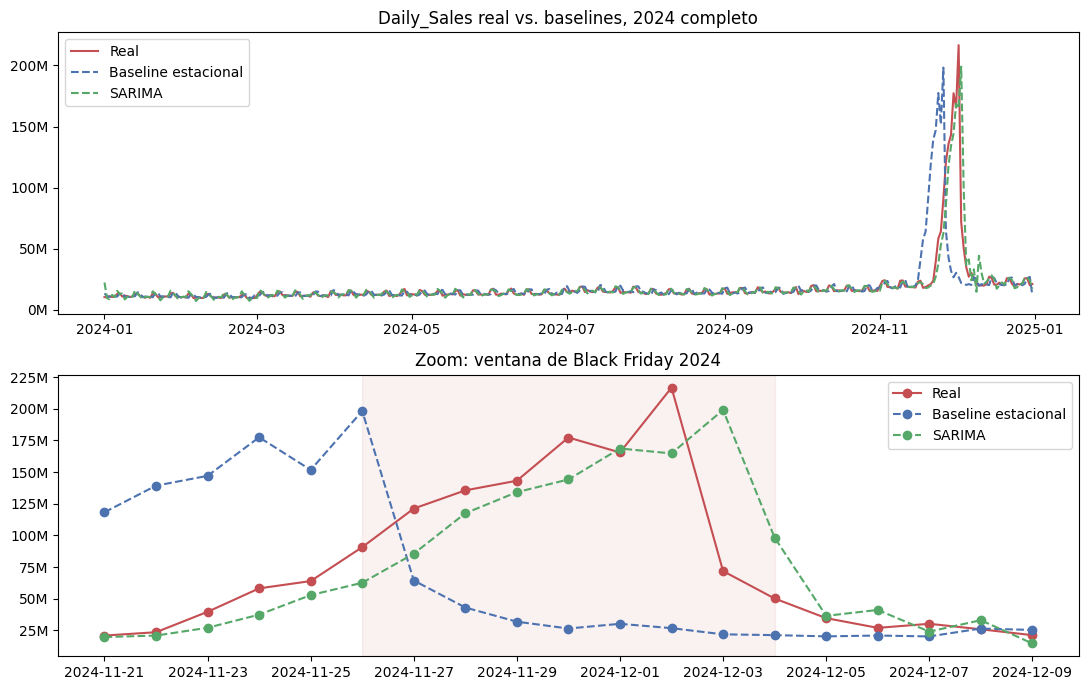

In [17]:
# Celda: gráfico comparativo, real vs. los dos baselines (2024)

test_plot = daily.loc[es_2024, ["Purchase_Date", "Daily_Sales", "Baseline_Estacional", "Baseline_SARIMA", "En_Ventana_BF"]]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

# Panel 1: todo 2024
ax = axes[0]
ax.plot(test_plot["Purchase_Date"], test_plot["Daily_Sales"], label="Real", color=PALETA[3], linewidth=1.5)
ax.plot(test_plot["Purchase_Date"], test_plot["Baseline_Estacional"], label="Baseline estacional", color=PALETA[0], linestyle="--")
ax.plot(test_plot["Purchase_Date"], test_plot["Baseline_SARIMA"], label="SARIMA", color=PALETA[2], linestyle="--")
ax.set_title("Daily_Sales real vs. baselines, 2024 completo")
millones(ax)
ax.legend()

# Panel 2: zoom en la ventana de Black Friday
ventana = test_plot[test_plot["En_Ventana_BF"] == 1]
margen = pd.Timedelta(days=5)
zoom = test_plot[
    (test_plot["Purchase_Date"] >= ventana["Purchase_Date"].min() - margen) &
    (test_plot["Purchase_Date"] <= ventana["Purchase_Date"].max() + margen)
]

ax = axes[1]
ax.plot(zoom["Purchase_Date"], zoom["Daily_Sales"], label="Real", color=PALETA[3], linewidth=1.5, marker="o")
ax.plot(zoom["Purchase_Date"], zoom["Baseline_Estacional"], label="Baseline estacional", color=PALETA[0], linestyle="--", marker="o")
ax.plot(zoom["Purchase_Date"], zoom["Baseline_SARIMA"], label="SARIMA", color=PALETA[2], linestyle="--", marker="o")
ax.axvspan(ventana["Purchase_Date"].min(), ventana["Purchase_Date"].max(), color=PALETA[3], alpha=0.08)
ax.set_title("Zoom: ventana de Black Friday 2024")
millones(ax)
ax.legend()

plt.tight_layout()
plt.show()

### Cierre del punto b)

El gráfico compara la venta real de 2024 contra los dos baselines. A simple vista el baseline
estacional replica razonablemente el nivel general pero no anticipa bien el pico de Black Friday
(la fecha de BF se mueve entre años, así que "el mismo día un año atrás" no queda alineado con el
evento). El SARIMA sigue mejor la forma de la serie porque se ajusta a la estacionalidad semanal,
aunque tampoco ve nada del evento BF en sí, porque no usa ninguna variable de calendario ni de
cercanía al evento. Las métricas de ambos se retoman y comparan con los modelos supervisados en el
punto e).

## c) Partición y estrategia de validación

Usamos **2024 como test final**, que no se toca hasta el punto e). Para entrenar y elegir
hiperparámetros usamos **2022 y 2023**.

Dentro de ese train, en vez de un único holdout o un k-fold aleatorio, usamos `TimeSeriesSplit`
(validación cruzada temporal, con ventana expansiva): cada fold entrena con todo lo anterior a una
fecha de corte y valida con el tramo siguiente, respetando el orden cronológico. Un k-fold
aleatorio mezclaría pasado y futuro dentro de la selección de modelos, lo que daría una estimación
del error optimista y poco realista (el modelo "vería" datos del futuro para predecir el pasado).

También evaluamos una ventana móvil de tamaño fijo (en vez de expansiva) y la descartamos: no hay
indicios de que el negocio haya cambiado de régimen ni de que la historia vieja moleste, así que
no hace falta olvidarla.

Usamos `n_splits=6`. La celda siguiente muestra los folds resultantes: como el lag de 365 días
recién tiene historia real completa a partir de 2023, los primeros folds (que tocan 2022) todavía
tienen `NaN` en esa columna, algo esperable dado cómo se construyó la variable, y que se trata
explícitamente en el punto d).

In [18]:
# Celda: partición train+validación (2022-2023) vs. test final (2024)

es_2024 = daily["Purchase_Date"].dt.year == 2024

train_val = daily.loc[~es_2024].sort_values("Purchase_Date").reset_index(drop=True)
test = daily.loc[es_2024].sort_values("Purchase_Date").reset_index(drop=True)

print(f"train+validación: {train_val['Purchase_Date'].min().date()} a {train_val['Purchase_Date'].max().date()} ({len(train_val)} filas)")
print(f"test (holdout final, no se toca hasta el punto e): {test['Purchase_Date'].min().date()} a {test['Purchase_Date'].max().date()} ({len(test)} filas)")

# n_splits=5: cada fold de validación queda con ~120 días, un balance razonable entre
# tener varios folds (estimación más robusta del error) y que cada uno cubra un tramo
# largo del año (para no evaluar solo sobre una estación particular).
tscv = TimeSeriesSplit(n_splits=6)

# Chequeo rápido de que los folds respetan el orden temporal y no se solapan
for i, (tr_idx, val_idx) in enumerate(tscv.split(train_val), 1):
    fechas_tr = train_val.loc[tr_idx, "Purchase_Date"]
    fechas_val = train_val.loc[val_idx, "Purchase_Date"]
    print(f"Fold {i}: train hasta {fechas_tr.max().date()} ({len(tr_idx)} filas)"
          f"  |  val {fechas_val.min().date()} a {fechas_val.max().date()} ({len(val_idx)} filas)"
          f"  |  NaN en Lag365 (val): {train_val.loc[val_idx, 'Daily_Sales_Lag365'].isna().sum()}")

train+validación: 2022-01-01 a 2023-12-31 (730 filas)
test (holdout final, no se toca hasta el punto e): 2024-01-01 a 2024-12-31 (366 filas)
Fold 1: train hasta 2022-04-16 (106 filas)  |  val 2022-04-17 a 2022-07-29 (104 filas)  |  NaN en Lag365 (val): 104
Fold 2: train hasta 2022-07-29 (210 filas)  |  val 2022-07-30 a 2022-11-10 (104 filas)  |  NaN en Lag365 (val): 104
Fold 3: train hasta 2022-11-10 (314 filas)  |  val 2022-11-11 a 2023-02-22 (104 filas)  |  NaN en Lag365 (val): 51
Fold 4: train hasta 2023-02-22 (418 filas)  |  val 2023-02-23 a 2023-06-06 (104 filas)  |  NaN en Lag365 (val): 0
Fold 5: train hasta 2023-06-06 (522 filas)  |  val 2023-06-07 a 2023-09-18 (104 filas)  |  NaN en Lag365 (val): 0
Fold 6: train hasta 2023-09-18 (626 filas)  |  val 2023-09-19 a 2023-12-31 (104 filas)  |  NaN en Lag365 (val): 0


## d) Modelos supervisados

Entrenamos dos modelos de familias distintas:
- **Ridge**: regresión lineal con regularización L2 (penaliza coeficientes grandes). Es
  interpretable y rápido, y sirve de punto de comparación directo con el baseline estacional.
- **LightGBM**: un ensamble de árboles con boosting. A diferencia de un modelo lineal, puede
  capturar no linealidades e interacciones entre variables (por ejemplo, entre `En_Ventana_BF` y
  el día de la semana) sin que haya que especificarlas a mano.

Se evaluaron como alternativas ElasticNet, XGBoost, Random Forest y SVR, pero se optó por esta
combinación por ser la comparación más informativa: lineal regularizado contra no lineal, que
cubre bien el espectro de complejidad sin duplicar familias parecidas.

### El problema del NaN en Lag365

Como vimos en el punto a), la columna `Daily_Sales_Lag365` (y las demás autorregresivas) tienen
`NaN` en las filas sin suficiente historia. LightGBM tolera `NaN` de forma nativa (decide en cada
split si mandar esas filas para un lado o el otro del árbol), pero Ridge no admite `NaN` en
absoluto.

Para poder comparar ambos modelos de forma justa, y para medir cuánto importa la forma de tratar
el `NaN`, corrimos tres configuraciones:
1. **LightGBM con NaN nativo**: sin tocar nada.
2. **LightGBM con flag + imputación**: se agrega una columna `*_Disponible` (1 si el dato existía,
   0 si se imputó) y se rellena el `NaN` con la mediana de train, para poder comparar contra la
   corrida 1 y aislar el efecto de tratar el NaN.
3. **Ridge con flag + imputación**: mismo tratamiento que 2, porque Ridge no tiene alternativa.

La mediana usada para imputar se calcula solo con datos de train, nunca con test, para no filtrar
información del período de evaluación hacia el entrenamiento.

### Armado de las variables predictoras

De las 42 columnas de `daily`, se excluyen de las variables predictoras: la fecha y el target, las
variables de actividad del propio día (`Transactions`, `Clientes_Unicos`, `Productos_Unicos`,
`Prop_Online`/`Store`, `Prop_Categoria_Top`, `Categorias_Distintas`), porque son descriptivas del
punto a) pero no se conocen de antemano el día que se quiere predecir, y las predicciones de los
baselines del punto b) (`Baseline_Estacional`, `Baseline_SARIMA`, `CPI_Index_Lag365`), que son
resultados, no insumos.

In [19]:
# Celda: armado de X, y y las dos versiones del dataset (NaN nativo vs. flag+imputación)
COLUMNAS_EXCLUIR = [
    "Purchase_Date", "Daily_Sales",              # target y su llave temporal
    "Transactions", "Clientes_Unicos", "Productos_Unicos",
    "Prop_Online", "Prop_Store", "Prop_Categoria_Top", "Categorias_Distintas",  # mismo día, leakage
    "Baseline_Estacional", "Baseline_SARIMA", "CPI_Index_Lag365",              # benchmarks del punto b
]
FEATURES = [c for c in daily.columns if c not in COLUMNAS_EXCLUIR]
print(f"{len(FEATURES)} features:", FEATURES)

X_train_val = train_val[FEATURES].copy()
y_train_val = train_val["Daily_Sales"].copy()
X_test = test[FEATURES].copy()
y_test = test["Daily_Sales"].copy()

# --- Versión con NaN nativo (para boosting, opción 4) ---
X_train_val_nan = X_train_val.copy()
X_test_nan = X_test.copy()

# --- Versión con flag + imputación neutra (para Ridge y para el boosting de comparación, opción 5) ---
COLUMNAS_CON_HISTORIA_INCOMPLETA = [c for c in FEATURES if X_train_val[c].isna().any()]
print("Columnas con NaN a tratar:", COLUMNAS_CON_HISTORIA_INCOMPLETA)

X_train_val_imp = X_train_val.copy()
X_test_imp = X_test.copy()
for col in COLUMNAS_CON_HISTORIA_INCOMPLETA:
    mediana_train = X_train_val[col].median()  # mediana calculada SOLO con train, nunca con test
    X_train_val_imp[f"{col}_Disponible"] = X_train_val[col].notna().astype(int)
    X_test_imp[f"{col}_Disponible"] = X_test[col].notna().astype(int)
    X_train_val_imp[col] = X_train_val[col].fillna(mediana_train)
    X_test_imp[col] = X_test[col].fillna(mediana_train)

33 features: ['Dow', 'Month', 'Quarter', 'Is_Weekend', 'Dow_Sin', 'Dow_Cos', 'Month_Sin', 'Month_Cos', 'Days_To_Black_Friday', 'Dias_Abs_BF', 'En_Ventana_BF', 'CPI_Index', 'Monthly_Inflation_Rate', 'Consumer_Confidence_Index', 'Retail_Activity_Index', 'Daily_Sales_Lag1', 'Daily_Sales_Lag7', 'Daily_Sales_Lag14', 'Daily_Sales_Lag28', 'Daily_Sales_Lag365', 'Daily_Sales_Media7', 'Daily_Sales_Desvio7', 'Daily_Sales_Media28', 'Daily_Sales_Desvio28', 'Transactions_Lag1', 'Transactions_Lag7', 'Transactions_Lag14', 'Transactions_Lag28', 'Transactions_Lag365', 'Transactions_Media7', 'Transactions_Desvio7', 'Transactions_Media28', 'Transactions_Desvio28']
Columnas con NaN a tratar: ['Daily_Sales_Lag1', 'Daily_Sales_Lag7', 'Daily_Sales_Lag14', 'Daily_Sales_Lag28', 'Daily_Sales_Lag365', 'Daily_Sales_Media7', 'Daily_Sales_Desvio7', 'Daily_Sales_Media28', 'Daily_Sales_Desvio28', 'Transactions_Lag1', 'Transactions_Lag7', 'Transactions_Lag14', 'Transactions_Lag28', 'Transactions_Lag365', 'Transactions_

### Búsqueda de hiperparámetros

Para las tres corridas usamos `GridSearchCV` con `cv=tscv` (el `TimeSeriesSplit` del punto c) y
`scoring="neg_root_mean_squared_error"`, así la selección de hiperparámetros respeta el orden
temporal igual que la validación.

En LightGBM exploramos cantidad de árboles (`n_estimators`), profundidad (`max_depth`) y
velocidad de aprendizaje (`learning_rate`). En Ridge, la fuerza de la regularización (`alpha`).
Antes de Ridge hace falta escalar las variables con `StandardScaler`, porque penaliza los
coeficientes según su magnitud: sin escalar, una variable en millones (como `Daily_Sales_Lag1`)
pesaría artificialmente más que una en unidades chicas.

In [20]:
# Celda: corrida 1, LightGBM con NaN nativo (opción 4)
grid_lgbm = {
    "n_estimators": [300 ,500, 800, 1200],
    "max_depth": [2, 3, 5, -1],
    "learning_rate": [ 0.1, 0.15, 0.2, 0.25],
}

lgbm_nan = GridSearchCV(
    LGBMRegressor(random_state=42),
    grid_lgbm, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
lgbm_nan.fit(X_train_val_nan, y_train_val)
print("Mejor combinación (NaN nativo):", lgbm_nan.best_params_)
print("RMSE promedio en CV:", -lgbm_nan.best_score_)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000119 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4739
[LightGBM] [Info] Number of data points in the train set: 730, number of used features: 32
[LightGBM] [Info] Start training from score 15222860.575342
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [21]:
# Celda: corrida 2, LightGBM con flag+imputación (opción 5), mismo grid, para comparar contra la corrida 1
lgbm_imp = GridSearchCV(
    LGBMRegressor(random_state=42),
    grid_lgbm, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
lgbm_imp.fit(X_train_val_imp, y_train_val)
print("Mejor combinación (flag+imputación):", lgbm_imp.best_params_)
print("RMSE promedio en CV:", -lgbm_imp.best_score_)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000280 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5037
[LightGBM] [Info] Number of data points in the train set: 730, number of used features: 40
[LightGBM] [Info] Start training from score 15222860.575342
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [22]:
# Celda: corrida 3, Ridge con flag+imputación (opción 5)

# StandardScaler es necesario acá porque Ridge penaliza los coeficientes según su
# magnitud: sin escalar, una variable en millones (Daily_Sales_Lag1) pesaría distinto
# que una en el rango 0-1 (Is_Weekend) solo por la escala, no por su importancia real.
# LightGBM no lo necesita porque decide splits comparando valores dentro de cada
# variable, no entre variables.
grid_ridge = {"ridge__alpha": [0.001, 0.005, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]}

ridge = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge(random_state=42)),
    grid_ridge, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
ridge.fit(X_train_val_imp, y_train_val)
print("Mejor alpha:", ridge.best_params_)
print("RMSE promedio en CV:", -ridge.best_score_)

Mejor alpha: {'ridge__alpha': 10.0}
RMSE promedio en CV: 6555710.278876762


### Resultados de las tres corridas

El mejor `alpha` de Ridge fue 10 (ver salida de la celda anterior), con un RMSE promedio en la
validación cruzada de 6,56 millones. Antes de comparar los tres, vale aclarar una decisión sobre
la cantidad de folds: se probó también con menos folds y el resultado cambiaba bastante, porque
los folds que contienen a Black Friday concentran la enorme mayoría del error (como se ve en la
tabla siguiente, el Fold 3 es un orden de magnitud peor que el resto) y son pocos folds los que
tienen un BF adentro. Con `n_splits=6` esos folds pesan menos en el promedio general que con menos
folds, y el resultado quedó más estable. Se decidió no seguir ajustando esto después de fijar los
6 folds.

La siguiente tabla muestra el RMSE de cada modelo en cada uno de los 6 folds:

In [23]:
# Celda: RMSE por fold de los tres modelos ganadores (en millones)
def rmse_por_fold(gs):
    i = gs.best_index_
    return {f"Fold {k+1}": -gs.cv_results_[f"split{k}_test_score"][i] / 1e6 for k in range(6)}

pd.DataFrame({
    "LGBM NaN nativo": rmse_por_fold(lgbm_nan),
    "LGBM flag+imputación": rmse_por_fold(lgbm_imp),
    "Ridge flag+imputación": rmse_por_fold(ridge),
}).round(2)

,LGBM NaN nativo,LGBM flag+imputación,Ridge flag+imputación
Fold 1,1.28,1.33,0.78
Fold 2,1.26,1.31,0.70
Fold 3,27.98,27.65,25.04
Fold 4,0.60,0.82,0.93
Fold 5,1.32,2.25,1.15
Fold 6,8.92,12.01,10.74


In [24]:
# Celda: RMSE de referencia sobre los mismos folds (reglas triviales, en millones)
def rmse(y, p):
    return np.sqrt(np.mean((y - p) ** 2))

filas = []
for i, (tr, val) in enumerate(tscv.split(train_val), 1):
    v = train_val.iloc[val]
    fila = {"Fold": i}
    for nombre, col in [("Igual que ayer (Lag1)", "Daily_Sales_Lag1"),
                        ("Igual que hace 7 días (Lag7)", "Daily_Sales_Lag7"),
                        ("Baseline estacional", "Baseline_Estacional")]:
        ok = v[col].notna()
        fila[nombre] = rmse(v.loc[ok, "Daily_Sales"], v.loc[ok, col]) / 1e6 if ok.any() else np.nan
    filas.append(fila)

pd.DataFrame(filas).set_index("Fold").round(2)

,Igual que ayer (Lag1),Igual que hace 7 días (Lag7),Baseline estacional
Fold,,,
1,1.68,0.69,NaN
2,2.02,1.01,NaN
3,12.41,35.04,1.44
4,1.63,0.68,1.66
5,2.02,0.88,1.95
6,13.80,38.33,13.74


La tabla de arriba compara contra dos reglas triviales ("la venta de ayer", "la venta de hace 7
días") y contra el baseline estacional del punto b), calculados sobre los mismos folds. El Fold 3
es el más difícil para todos, real o trivial: ahí cae un Black Friday (el de 2022) que el modelo
entrena sin haber visto ningún otro antes, así que hasta la regla más simple se equivoca mucho
(35,04 millones de RMSE para "hace 7 días"). Fuera de ese fold, los tres modelos superan
claramente a las reglas triviales.

## e) Evaluación

Elegimos tres métricas, cada una mirando el error desde un ángulo distinto:
- **RMSE** (raíz del error cuadrático medio): penaliza fuerte los errores grandes, relevante
  porque Black Friday genera picos que un buen modelo debería anticipar.
- **MAE** (error absoluto medio): más robusta a outliers, da una noción del error "típico" de un
  día cualquiera, en las mismas unidades que `Daily_Sales`.
- **sMAPE** (error porcentual absoluto simétrico): como la venta diaria varía mucho entre
  temporada baja y Black Friday, esta métrica relativa evita que el MAPE tradicional (que también
  existe, pero se vuelve inestable con valores chicos en el denominador) explote.

Con los modelos ya entrenados (usando todo 2022-2023, la configuración ganadora de cada
`GridSearchCV`), predecimos sobre 2024 y calculamos las tres métricas.

In [25]:
# Celda: predicciones sobre test 2024 y métricas
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Chequeo de que los objetos en memoria son los de 6 folds
print("Folds usados:", lgbm_nan.n_splits_, lgbm_imp.n_splits_, ridge.n_splits_)

pred_test = pd.DataFrame({
    "Purchase_Date": test["Purchase_Date"].values,
    "Real": y_test.values,
    "En_Ventana_BF": test["En_Ventana_BF"].values,
})
pred_test["LGBM_NaN"] = lgbm_nan.predict(X_test_nan)
pred_test["LGBM_Imp"] = lgbm_imp.predict(X_test_imp)
pred_test["Ridge"] = ridge.predict(X_test_imp)
pred_test["Baseline_Estacional"] = test["Baseline_Estacional"].values
pred_test["Baseline_SARIMA"] = test["Baseline_SARIMA"].values
pred_test["Lag7"] = test["Daily_Sales_Lag7"].values

modelos = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_Estacional", "Baseline_SARIMA", "Lag7"]
print("NaN en predicciones (se espera 0):", pred_test[modelos].isna().sum().sum())

def metricas(real, pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "MAE": mean_absolute_error(real, pred),
        "sMAPE (%)": 100 * np.mean(2 * np.abs(real - pred) / (np.abs(real) + np.abs(pred))),
    }

tabla = pd.DataFrame({m: metricas(pred_test["Real"], pred_test[m]) for m in modelos}).T
tabla["RMSE"] /= 1e6
tabla["MAE"] /= 1e6
tabla = tabla.rename(columns={"RMSE": "RMSE (M)", "MAE": "MAE (M)"}).sort_values("RMSE (M)").round(2)
tabla

Folds usados: 6 6 6
NaN en predicciones (se espera 0): 0


,RMSE (M),MAE (M),sMAPE (%)
LGBM_NaN,5.94,2.07,11.14
Ridge,6.85,2.07,9.44
LGBM_Imp,7.50,2.83,15.97
Baseline_SARIMA,8.63,2.24,8.66
Baseline_Estacional,22.39,5.92,15.06
Lag7,24.15,5.76,12.00


LightGBM con NaN nativo tiene el mejor RMSE y MAE (5,94M y 2,07M), Ridge queda muy cerca en MAE
(también 2,07M) y tiene el mejor sMAPE (9,44%). LightGBM con imputación queda peor que su versión
con NaN nativo en las tres métricas: tratar el NaN explícitamente no ayudó acá. Los dos modelos
supervisados le ganan claramente a los dos baselines del punto b) y a las reglas triviales, lo que
confirma que valió la pena construir variables autorregresivas y no quedarse con una regla simple.

### Observado vs. predicho

Graficamos las predicciones de los cuatro modelos contra la venta real, para todo 2024 y con zoom
en la ventana de Black Friday.

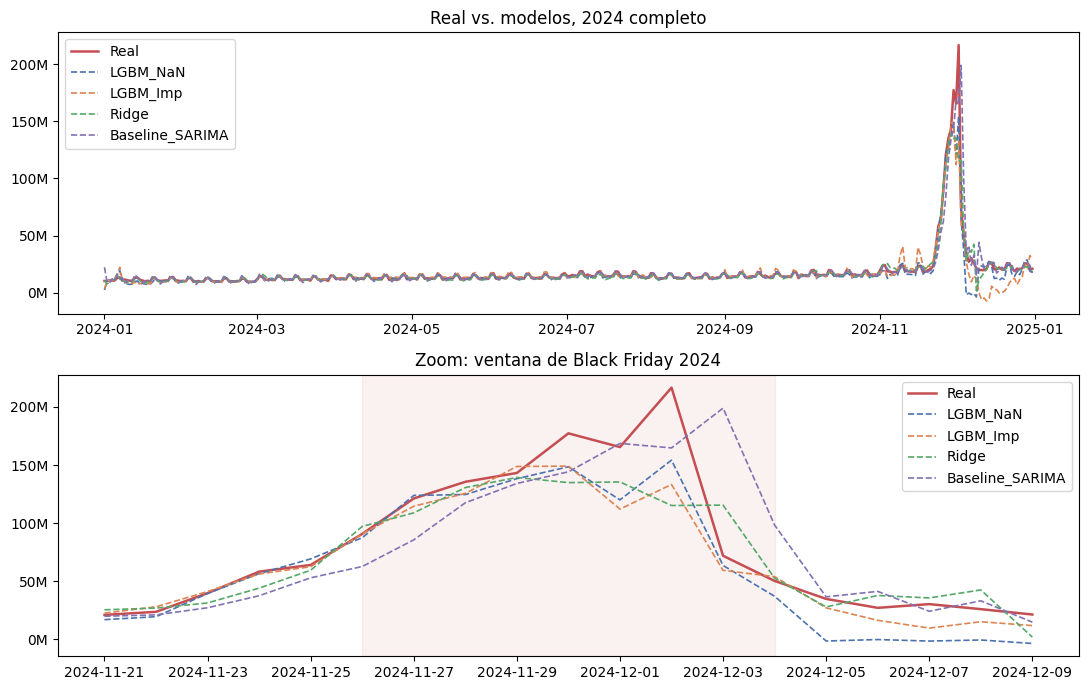

In [26]:
# Celda: observado vs. predicho en 2024 (año completo y zoom en la ventana de Black Friday)
import matplotlib.pyplot as plt

colores = {"LGBM_NaN": PALETA[0], "LGBM_Imp": PALETA[1], "Ridge": PALETA[2], "Baseline_SARIMA":PALETA[4]}

ventana = pred_test[pred_test["En_Ventana_BF"] == 1]
margen = pd.Timedelta(days=5)
zoom = pred_test[
    (pred_test["Purchase_Date"] >= ventana["Purchase_Date"].min() - margen) &
    (pred_test["Purchase_Date"] <= ventana["Purchase_Date"].max() + margen)
]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, datos, titulo in [(axes[0], pred_test, "Real vs. modelos, 2024 completo"),
                          (axes[1], zoom, "Zoom: ventana de Black Friday 2024")]:
    ax.plot(datos["Purchase_Date"], datos["Real"], label="Real", color=PALETA[3], linewidth=1.8)
    for m, c in colores.items():
        ax.plot(datos["Purchase_Date"], datos[m], label=m, color=c, linestyle="--", linewidth=1.2)
    ax.set_title(titulo)
    millones(ax)
    ax.legend()
axes[1].axvspan(ventana["Purchase_Date"].min(), ventana["Purchase_Date"].max(), color=PALETA[3], alpha=0.08)
plt.tight_layout()
plt.show()

En el año completo las cuatro curvas siguen de cerca a la real. El zoom en la ventana de BF
muestra que todas subestiman el pico en algún grado (se retoma con números en el punto f).

### Dispersión y sesgo de los residuos

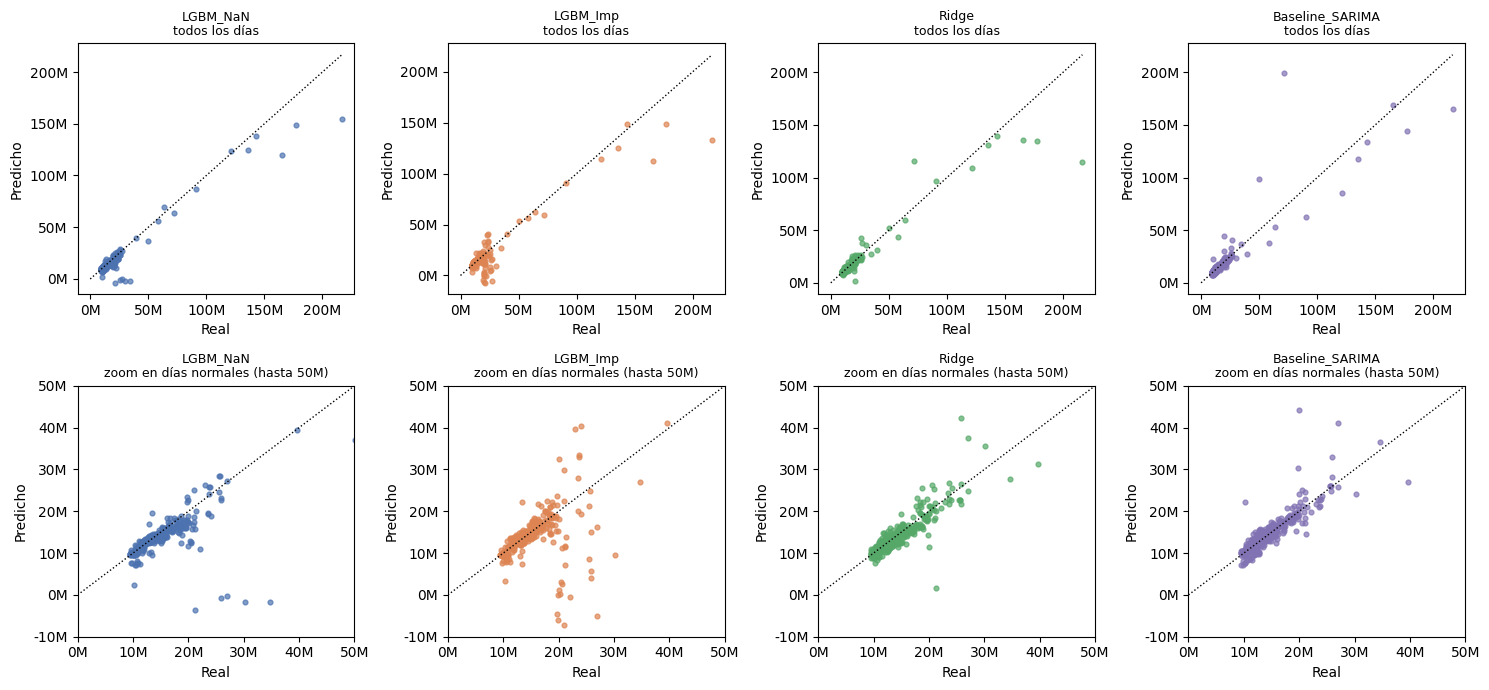

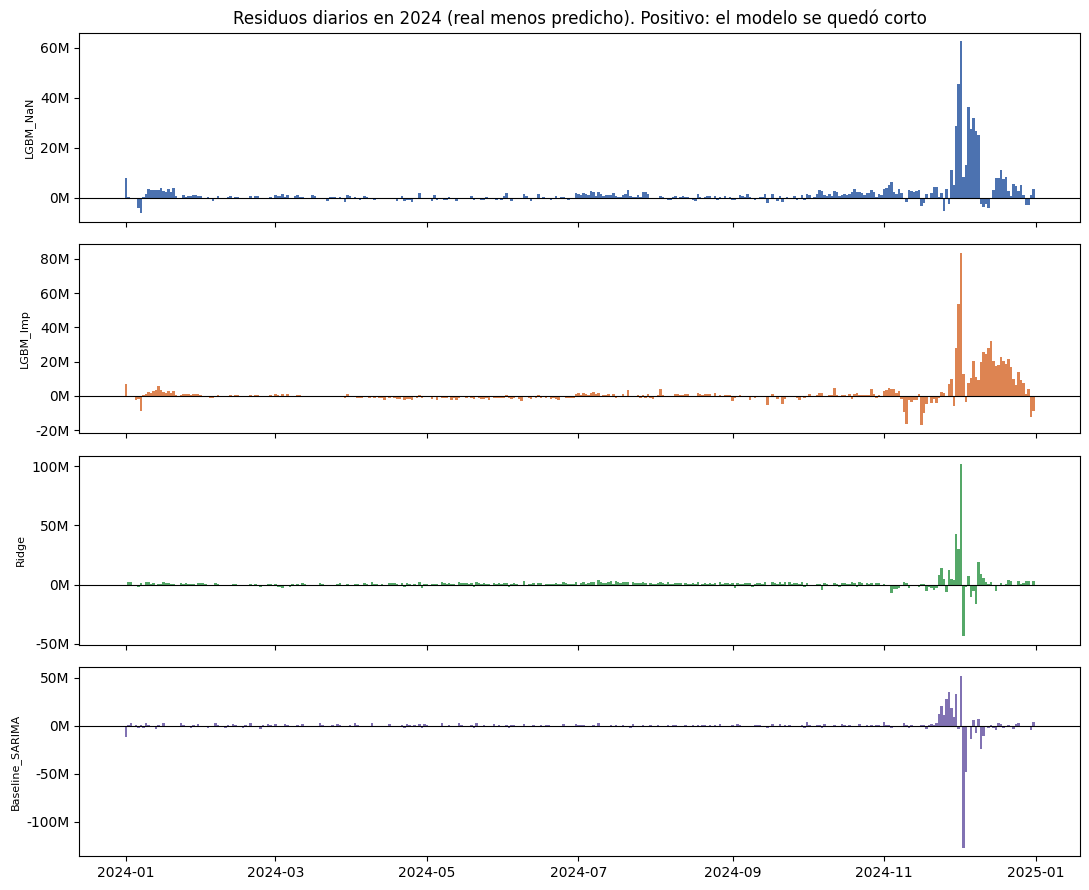

,Sesgo medio (M),Mediana del residuo (M),Días en que se quedó corto (%)
LGBM_NaN,1.43,0.32,59.02
LGBM_Imp,1.28,-0.04,48.09
Ridge,0.82,0.69,67.21
Baseline_SARIMA,-0.05,-0.05,47.81


In [27]:
# Celda: dispersión observado vs. predicho y residuos diarios
modelos_4 = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_SARIMA"]
COL = {"LGBM_NaN": PALETA[0], "LGBM_Imp": PALETA[1], "Ridge": PALETA[2], "Baseline_SARIMA": PALETA[4],
       "Baseline_Estacional": PALETA[5], "Lag7": PALETA[6]}
pred_test["Mes"] = pred_test["Purchase_Date"].dt.month
for m in modelos_4:
    pred_test[f"res_{m}"] = pred_test["Real"] - pred_test[m]

# Arriba: todos los días. Abajo: zoom en días normales. La línea punteada es la predicción perfecta.
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for j, m in enumerate(modelos_4):
    for i, titulo in enumerate(["todos los días", "zoom en días normales (hasta 50M)"]):
        ax = axes[i, j]
        ax.scatter(pred_test["Real"], pred_test[m], s=12, color=COL[m], alpha=0.7)
        tope = pred_test["Real"].max() if i == 0 else 50e6
        ax.plot([0, tope], [0, tope], color="black", linewidth=1, linestyle=":")
        if i == 1:
            ax.set_xlim(0, 50e6); ax.set_ylim(-10e6, 50e6)
        ax.set_title(f"{m}\n{titulo}", fontsize=9)
        ax.set_xlabel("Real"); ax.set_ylabel("Predicho")
        millones(ax, "x"); millones(ax, "y")
plt.tight_layout(); plt.show()

# Residuos diarios
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, m in zip(axes, modelos_4):
    ax.bar(pred_test["Purchase_Date"], pred_test[f"res_{m}"], color=COL[m], width=1.0)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel(m, fontsize=8)
    millones(ax)
axes[0].set_title("Residuos diarios en 2024 (real menos predicho). Positivo: el modelo se quedó corto")
plt.tight_layout(); plt.show()

# ¿Se equivocan sistemáticamente para un lado?
res = pred_test[[f"res_{m}" for m in modelos_4]].copy()
res.columns = modelos_4
pd.DataFrame({
    "Sesgo medio (M)": res.mean() / 1e6,
    "Mediana del residuo (M)": res.median() / 1e6,
    "Días en que se quedó corto (%)": (res > 0).mean() * 100,
}).round(2)

Los cuatro modelos tienen sesgo positivo (predicen, en promedio, por debajo de lo real): entre
0,82M (Ridge) y 1,43M (LGBM_NaN) de sesgo medio, salvo el SARIMA que está casi sin sesgo (-0,05M).
Coherente con eso, Ridge se queda corto el 67,21% de los días, más que los demás. Este sesgo se
entiende mejor mirando dónde se concentra el error (siguiente celda) y qué pasa específicamente en
Black Friday (punto f).

### Dónde se concentra el error

,% del error cuadrático en sus 10 peores días,5 peores días
Modelo,,
LGBM_NaN,89.1,"02-Dec, 01-Dec, 05-Dec, 07-Dec, 30-Nov"
LGBM_Imp,73.3,"02-Dec, 01-Dec, 14-Dec, 13-Dec, 30-Nov"
Ridge,93.8,"02-Dec, 03-Dec, 30-Nov, 01-Dec, 09-Dec"
Baseline_SARIMA,95.0,"03-Dec, 02-Dec, 04-Dec, 27-Nov, 30-Nov"


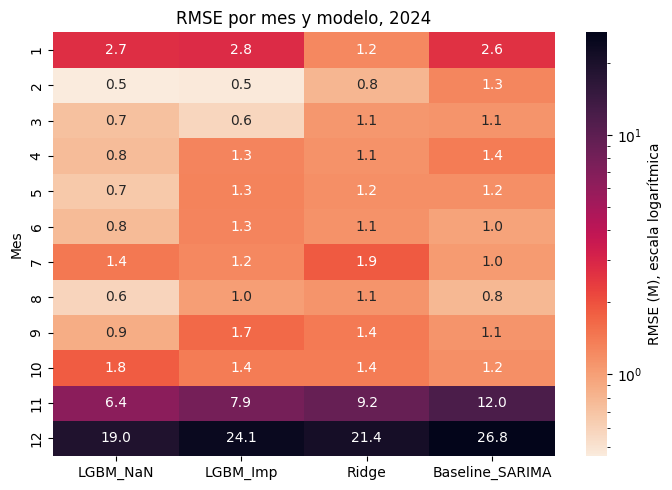

In [28]:
# Celda: dónde se concentra el error
from matplotlib.colors import LogNorm

filas = []
for m in modelos_4:
    e2 = pred_test[f"res_{m}"] ** 2
    filas.append({
        "Modelo": m,
        "% del error cuadrático en sus 10 peores días": round(100 * e2.nlargest(10).sum() / e2.sum(), 1),
        "5 peores días": ", ".join(pred_test.loc[e2.nlargest(5).index, "Purchase_Date"].dt.strftime("%d-%b")),
    })
display(pd.DataFrame(filas).set_index("Modelo"))

rmse_mes = pd.DataFrame({
    m: pred_test.groupby("Mes")[f"res_{m}"].apply(lambda s: np.sqrt((s ** 2).mean())) for m in modelos_4
}) / 1e6

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(rmse_mes, annot=True, fmt=".1f", cmap="rocket_r", norm=LogNorm(),
            cbar_kws={"label": "RMSE (M), escala logarítmica"}, ax=ax)
ax.set_title("RMSE por mes y modelo, 2024")
plt.tight_layout(); plt.show()

Muy poca cantidad de días explica casi todo el error cuadrático: los 10 peores días concentran
entre 73,3% (LGBM_Imp) y 95,0% (SARIMA) del error total. Esta concentración alta no es
necesariamente mala: quiere decir que en el resto del año los modelos son muy precisos, y que el
desafío real está en un puñado de fechas de fin de noviembre y principios de diciembre, todas
cerca de Black Friday (ver el listado de peores días de cada modelo arriba).

### Autocorrelación de los residuos

Si los residuos (real menos predicho) están correlacionados entre sí día a día, quiere decir que
al modelo se le está escapando un patrón sistemático que todavía podría explotar.

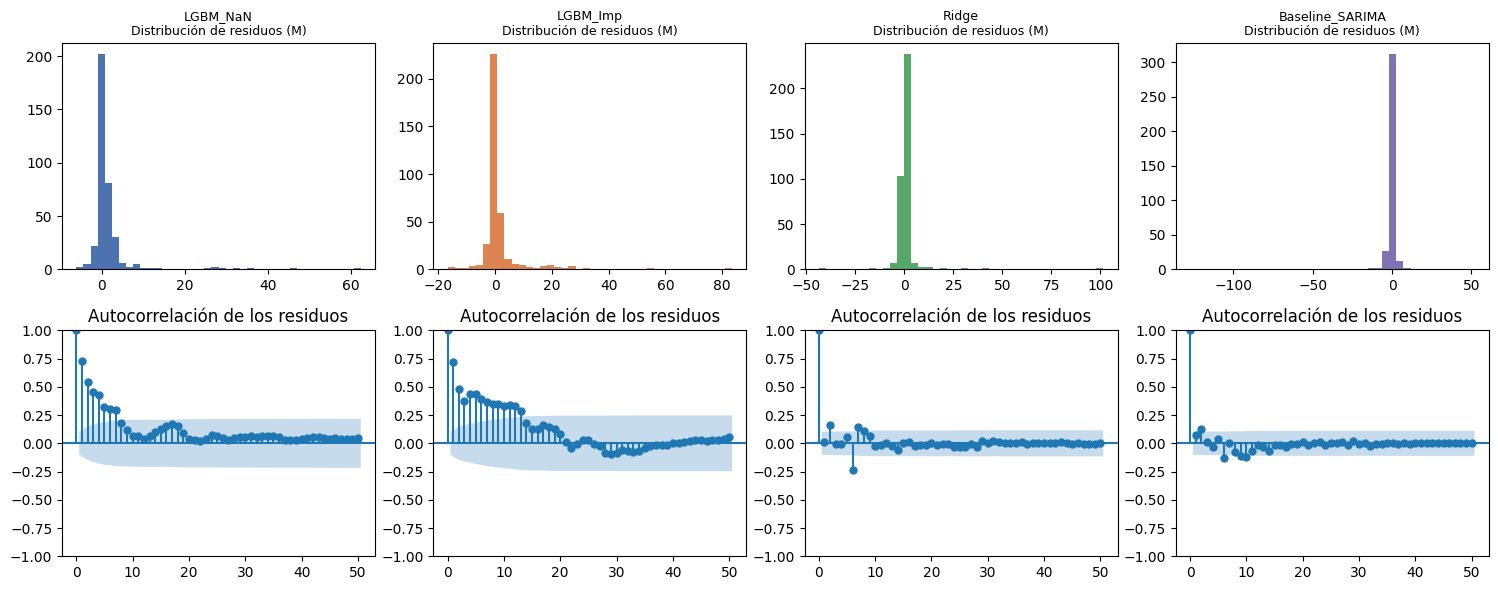

In [29]:
# Celda: distribución y autocorrelación de los residuos
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, m in enumerate(modelos_4):
    axes[0, j].hist(pred_test[f"res_{m}"] / 1e6, bins=40, color=COL[m])
    axes[0, j].set_title(f"{m}\nDistribución de residuos (M)", fontsize=9)
    plot_acf(pred_test[f"res_{m}"], lags=50, ax=axes[1, j], title="Autocorrelación de los residuos")
plt.tight_layout(); plt.show()

Los dos modelos de LightGBM muestran autocorrelación alta en los primeros lags (rachas de
residuos del mismo signo seguidos), mientras que Ridge y el SARIMA quedan dentro de la banda de
ruido esperable. Es un indicio de que LightGBM tiene un sesgo que persiste varios días seguidos,
probablemente ligado al comportamiento después del pico de Black Friday (se retoma en el punto f).

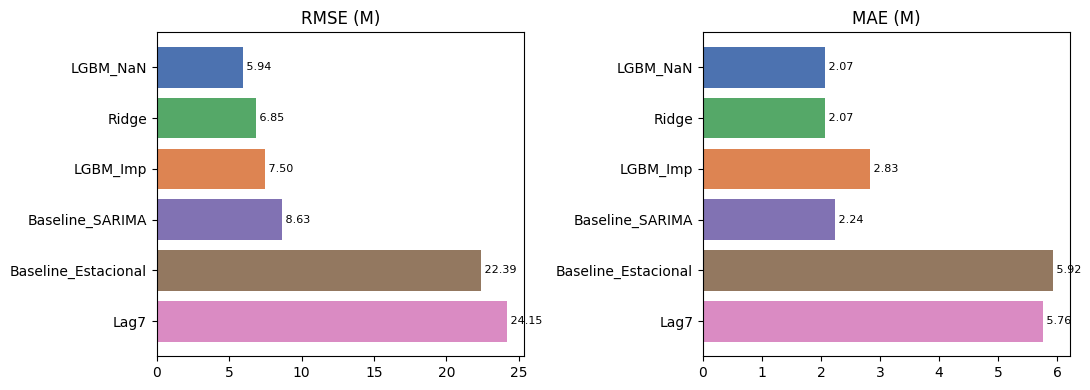

In [30]:
# Celda: modelos contra referencias, RMSE y MAE
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orden = tabla.index.tolist()
for ax, col in zip(axes, ["RMSE (M)", "MAE (M)"]):
    ax.barh(orden, tabla[col], color=[COL[m] for m in orden])
    ax.invert_yaxis()
    ax.set_title(col)
    for y, v in enumerate(tabla[col]):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

El gráfico resume el ranking de RMSE y MAE ya visto en la tabla de arriba: LightGBM NaN nativo
primero, Ridge segundo y muy cerca, LightGBM con imputación y SARIMA detrás, y los dos baselines
simples muy por debajo de los cuatro modelos anteriores.

## f) Black Friday

Black Friday es el evento de mayor interés de negocio y el más difícil de predecir: un modelo
puede tener buen desempeño promedio y aun así fallar justo donde más importa. Para analizarlo por
separado dividimos el año en tres zonas:
- **Ventana BF**: los 9 días que van del 26 de noviembre al 4 de diciembre de 2024
  (`Days_To_Black_Friday` entre -3 y +5), definidos por la bandera `En_Ventana_BF` ya calculada en
  el TP2.
- **Después de la ventana**: del 5 al 31 de diciembre (27 días). Se separa del resto del año a
  propósito, porque ahí es donde se concentran los residuos con racha que vimos en el punto e);
  mezclarla con el resto del año escondería ese problema dentro del promedio general.
- **Resto del año**: los 330 días restantes.

Recalculamos RMSE y MAE del punto e) pero separados por zona, y además un RMSE relativo (como
porcentaje de la venta media de cada zona), porque las tres zonas tienen niveles de venta muy
distintos y comparar el error en valores absolutos entre ellas sería engañoso.

In [31]:
# Celda: desempeño por zona (ventana de BF, después de la ventana y resto del año)
pred_test["Dias_BF"] = test["Days_To_Black_Friday"].values
pred_test["Zona"] = np.select(
    [pred_test["En_Ventana_BF"] == 1, pred_test["Dias_BF"] > 5],
    ["Ventana BF", "Después de la ventana"],
    default="Resto del año",
)
print(pred_test["Zona"].value_counts())

modelos_6 = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_SARIMA", "Baseline_Estacional", "Lag7"]
zonas = ["Ventana BF", "Después de la ventana", "Resto del año"]

def por_zona(f):
    filas = {"Global": {m: f(pred_test["Real"], pred_test[m]) for m in modelos_6}}
    for z in zonas:
        g = pred_test[pred_test["Zona"] == z]
        filas[z] = {m: f(g["Real"], g[m]) for m in modelos_6}
    return pd.DataFrame(filas)

rmse = lambda r, p: np.sqrt(np.mean((r - p) ** 2)) / 1e6
mae = lambda r, p: np.mean(np.abs(r - p)) / 1e6

medias = {"Global": pred_test["Real"].mean(),
          **{z: pred_test.loc[pred_test["Zona"] == z, "Real"].mean() for z in zonas}}
print("Venta media diaria real por zona (M)"); display((pd.Series(medias) / 1e6).round(1))
print("RMSE (M)"); display(por_zona(rmse).round(2))
print("MAE (M)"); display(por_zona(mae).round(2))
print("RMSE relativo (% de la venta media de la zona)")
display((por_zona(rmse) * 1e6 / pd.Series(medias) * 100).round(1))

Zona
Resto del año            330
Después de la ventana     27
Ventana BF                 9
Name: count, dtype: int64
Venta media diaria real por zona (M)


,0
Global,17.9
Ventana BF,130.2
Después de la ventana,23.1
Resto del año,14.4


RMSE (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_NaN,5.94,28.30,13.54,1.51
LGBM_Imp,7.50,34.90,17.29,2.17
Ridge,6.85,41.04,6.24,1.72
Baseline_SARIMA,8.63,52.46,6.50,2.01
Baseline_Estacional,22.39,113.62,4.94,14.21
Lag7,24.15,106.53,62.93,3.67


MAE (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_NaN,2.07,20.02,8.82,1.03
LGBM_Imp,2.83,22.62,15.51,1.26
Ridge,2.07,27.52,4.07,1.21
Baseline_SARIMA,2.24,39.37,4.02,1.08
Baseline_Estacional,5.92,102.56,3.33,3.50
Lag7,5.76,99.49,30.39,1.19


RMSE relativo (% de la venta media de la zona)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_NaN,33.3,21.7,58.7,10.5
LGBM_Imp,42.0,26.8,75.0,15.1
Ridge,38.4,31.5,27.1,11.9
Baseline_SARIMA,48.3,40.3,28.2,14.0
Baseline_Estacional,125.4,87.2,21.4,99.0
Lag7,135.3,81.8,273.0,25.6


En términos relativos (que es la comparación justa entre zonas), LightGBM NaN nativo es el mejor
dentro de la ventana de BF (21,7% de la venta media de la zona) y en el resto del año (10,5%),
pero el peor después de la ventana (58,7%), justo donde detectamos las rachas de residuos. Ridge
tiene el patrón inverso: peor en la ventana (31,5%) pero mejor después (27,1%). El baseline
estacional, que en el punto e) parecía claramente inferior, gana después de la ventana (21,4%)
porque no usa lags recientes contaminados por el pico; en cambio es el peor de todos en la ventana
misma (87,2%) y en el resto del año (99,0%), por la desalineación del BF entre años que ya se
discutió en el punto b).

### La dinámica dentro de la ventana de Black Friday

Miramos específicamente cómo cada modelo representa la forma del pico: si acierta el día, la
magnitud y el total vendido en la ventana.

In [32]:
# Celda: dinámica dentro de la ventana de BF (pico, momento del pico, forma y total vendido)
v = pred_test[pred_test["Zona"] == "Ventana BF"].reset_index(drop=True)
i_pico = v["Real"].idxmax()
pico_real = v.loc[i_pico, "Real"]
fecha_pico_real = v.loc[i_pico, "Purchase_Date"]
print(f"Pico real: {pico_real/1e6:.1f}M el {fecha_pico_real.strftime('%d-%b')}")

filas = []
for m in modelos_6:
    fecha_pico_m = v.loc[v[m].idxmax(), "Purchase_Date"]
    filas.append({
        "Modelo": m,
        "Predicho el día del pico (% del real)": 100 * v.loc[i_pico, m] / pico_real,
        "Día del pico predicho": fecha_pico_m.strftime("%d-%b"),
        "Desfase del pico (días)": (fecha_pico_m - fecha_pico_real).days,
        "Correlación con lo real": v["Real"].corr(v[m]),
        "Error en el total vendido (%)": 100 * (v[m].sum() / v["Real"].sum() - 1),
    })
pd.DataFrame(filas).set_index("Modelo").round(1)

Pico real: 216.7M el 02-Dec


,Predicho el día del pico (% del real),Día del pico predicho,Desfase del pico (días),Correlación con lo real,Error en el total vendido (%)
Modelo,,,,,
LGBM_NaN,71.2,02-Dec,0,0.9,-14.9
LGBM_Imp,61.5,30-Nov,-2,0.8,-15.8
Ridge,53.1,29-Nov,-3,0.7,-12.2
Baseline_SARIMA,76.0,03-Dec,1,0.4,0.2
Baseline_Estacional,12.3,26-Nov,-6,-0.3,-60.4
Lag7,29.5,04-Dec,2,-0.4,-61.1


El pico real fue de 216,7 millones el 2 de diciembre. LightGBM NaN nativo es el único modelo que
ubica el pico exactamente en el día correcto y el que tiene mayor correlación con la serie real
(0,9), aunque solo llega al 71,2% del valor del pico y subestima el total vendido de la ventana en
14,9%. El SARIMA acierta el día siguiente (un día de desfase) y con menor correlación (0,4), lo
que sugiere que su buen desempeño relativo en el total vendido viene más de una compensación de
errores que de representar bien la dinámica. Ridge pone el pico tres días antes de lo real (el
viernes de Black Friday, día 0): una suma lineal de variables no puede reproducir bien un pico que
llega corrido, tiene que "adelantarlo" hacia donde ya tiene señal fuerte (el día del evento en sí).

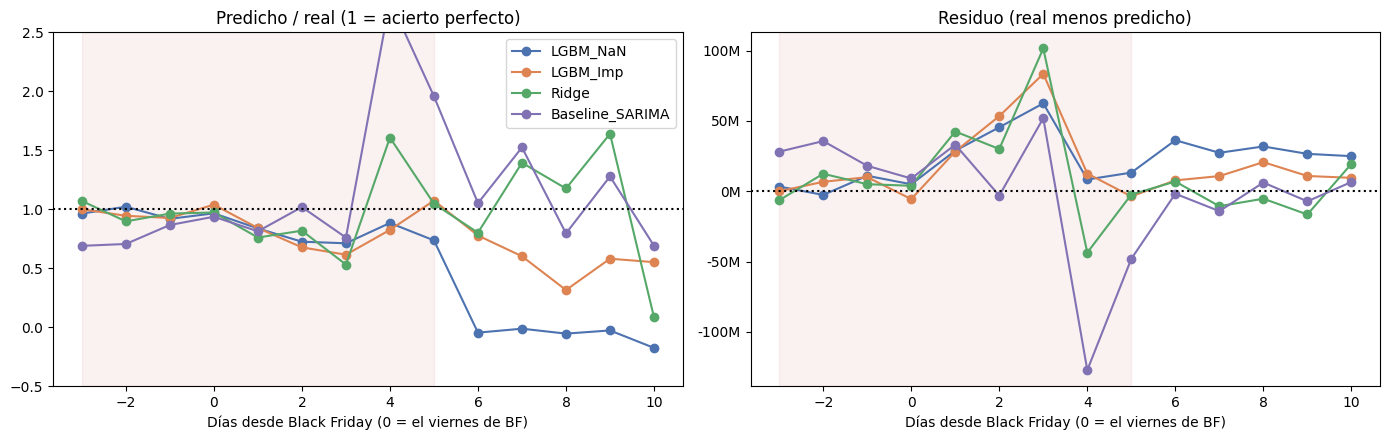

In [33]:
# Celda: día a día alrededor de Black Friday (predicho / real, y residuo)
zoom = pred_test[(pred_test["Dias_BF"] >= -3) & (pred_test["Dias_BF"] <= 10)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for m in modelos_4:
    axes[0].plot(zoom["Dias_BF"], zoom[m] / zoom["Real"], marker="o", label=m, color=COL[m])
    axes[1].plot(zoom["Dias_BF"], zoom[f"res_{m}"], marker="o", label=m, color=COL[m])
axes[0].axhline(1, color="black", linestyle=":")
axes[1].axhline(0, color="black", linestyle=":")
axes[0].set_ylim(-0.5, 2.5)
axes[0].set_title("Predicho / real (1 = acierto perfecto)")
axes[1].set_title("Residuo (real menos predicho)")
millones(axes[1])
for ax in axes:
    ax.axvspan(-3, 5, color=PALETA[3], alpha=0.08)
    ax.set_xlabel("Días desde Black Friday (0 = el viernes de BF)")
axes[0].legend()
plt.tight_layout(); plt.show()

El gráfico día a día confirma lo anterior: LightGBM sigue de cerca la forma del pico pero se queda
corto en la magnitud, Ridge llega tarde a reaccionar y adelanta el máximo, y los residuos de todos
los modelos se agrandan justo en el entorno del pico.

### Cierre del punto f)

No hay un modelo que gane en las tres zonas. LightGBM NaN nativo es el que mejor representa el
evento de Black Friday en sí, pero es el que peor se comporta en las semanas siguientes. Ridge y
el SARIMA son más conservadores durante el pico pero más confiables después. Conviene tener
presente que el test tiene un único Black Friday (9 días), así que estas conclusiones son sobre un
solo evento y conviene tomarlas como una primera lectura, no como algo definitivo.

### Detalle adicional del punto f): desglose mensual y diagnóstico de las predicciones negativas

Quedaba pendiente cerrar dos cosas sobre los modelos del esquema de un paso (puntos e y f): cómo
se reparte el error mes a mes, y por qué algunos modelos llegan a predecir valores negativos, algo
que no tiene sentido para una venta, que nunca puede ser menor a cero.

In [34]:
# Celda: desglose por mes y chequeo de las predicciones post Black Friday
modelos_4 = ["LGBM_NaN", "LGBM_Imp", "Ridge", "Baseline_SARIMA"]
pred_test["Mes"] = pred_test["Purchase_Date"].dt.month
for m in modelos_4:
    pred_test[f"err_{m}"] = pred_test["Real"] - pred_test[m]
cols_err = [f"err_{m}" for m in modelos_4]

rmse_mes = (pred_test.groupby("Mes")[cols_err].apply(lambda g: np.sqrt((g ** 2).mean())) / 1e6).round(2)
mae_mes = (pred_test.groupby("Mes")[cols_err].apply(lambda g: g.abs().mean()) / 1e6).round(2)
rmse_mes.columns = mae_mes.columns = modelos_4
print("RMSE por mes (M)"); display(rmse_mes)
print("MAE por mes (M)"); display(mae_mes)

print("Predicciones negativas por modelo:")
print((pred_test[["LGBM_NaN", "LGBM_Imp", "Ridge"]] < 0).sum())

post = pred_test.loc[pred_test["Purchase_Date"] >= "2024-12-04",
                     ["Purchase_Date", "Real", "LGBM_NaN", "LGBM_Imp", "Ridge"]].copy()
post.iloc[:, 1:] = (post.iloc[:, 1:] / 1e6).round(1)
post.head(12)

RMSE por mes (M)


,LGBM_NaN,LGBM_Imp,Ridge,Baseline_SARIMA
Mes,,,,
1,2.75,2.84,1.25,2.64
2,0.46,0.47,0.81,1.28
3,0.72,0.58,1.08,1.12
4,0.75,1.29,1.13,1.41
5,0.66,1.31,1.17,1.17
6,0.77,1.29,1.14,0.98
7,1.44,1.25,1.87,1.05
8,0.58,1.02,1.12,0.78
9,0.88,1.65,1.42,1.13


MAE por mes (M)


,LGBM_NaN,LGBM_Imp,Ridge,Baseline_SARIMA
Mes,,,,
1,2.03,2.04,1.03,1.51
2,0.36,0.36,0.67,0.93
3,0.60,0.44,0.83,0.93
4,0.59,1.17,0.90,1.12
5,0.56,1.17,1.03,0.87
6,0.57,1.11,0.94,0.77
7,1.22,1.00,1.65,0.83
8,0.50,0.70,1.02,0.64
9,0.72,1.03,1.24,0.88


Predicciones negativas por modelo:
LGBM_NaN    5
LGBM_Imp    6
Ridge       0
dtype: int64


/tmp/ipykernel_766/3478022039.py:19: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '338    50.2
339    34.7
340    27.0
341    30.2
342    25.9
343    21.2
344    19.9
345    19.8
346    19.7
347    21.0
348    27.0
349    25.9
350    20.5
351    20.5
352    22.1
353    20.2
354    20.0
355    25.8
356    25.5
357    21.1
358    18.9
359    21.1
360    20.6
361    21.4
362    25.7
363    25.5
364    20.0
365    21.0
Name: Real, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  post.iloc[:, 1:] = (post.iloc[:, 1:] / 1e6).round(1)


,Purchase_Date,Real,LGBM_NaN,LGBM_Imp,Ridge
338,2024-12-04,50.2,36.9,53.9,52.5
339,2024-12-05,34.7,-1.6,27.0,27.8
340,2024-12-06,27.0,-0.3,16.2,37.6
341,2024-12-07,30.2,-1.6,9.5,35.5
342,2024-12-08,25.9,-0.7,15.0,42.4
343,2024-12-09,21.2,-3.7,11.7,1.8
344,2024-12-10,19.9,22.7,-0.1,11.4
345,2024-12-11,19.8,23.5,-6.1,14.3
346,2024-12-12,19.7,22.1,-4.6,17.6
347,2024-12-13,21.0,25.1,-7.2,20.3


El desglose mensual confirma lo que ya se había visto por zona: noviembre y diciembre concentran
el grueso del error de los cuatro modelos, y el resto de los meses tiene errores chicos y parejos.

Los dos LightGBM llegan a predecir valores negativos: 5 veces el de NaN nativo (entre el 5 y el 9
de diciembre) y 6 veces el de imputación (entre el 10 y el 14 de diciembre). Ridge nunca predice
negativo. Se decidió no recortar esos valores a cero y dejarlos así, mostrados tal cual, para que
el problema quede visible en vez de disimulado.

In [35]:
# Celda: qué variables empujan la predicción a negativo (LightGBM NaN nativo)
X_todo = pd.concat([X_train_val_nan, X_test_nan], ignore_index=True)
fechas_todo = pd.concat([train_val["Purchase_Date"], test["Purchase_Date"]], ignore_index=True)

# 2023-11-30 es el mismo punto del ciclo que 2024-12-05 (+6 días), pero con predicción sana
elegidas = pd.to_datetime(["2023-11-30", "2024-12-05", "2024-12-09"])
idx = fechas_todo[fechas_todo.isin(elegidas)].index

contrib = lgbm_nan.best_estimator_.predict(X_todo.loc[idx], pred_contrib=True)
contrib = pd.DataFrame(contrib, index=fechas_todo.loc[idx].dt.date,
                       columns=list(X_todo.columns) + ["Base"]) / 1e6

tabla_c = contrib.round(1).T
tabla_c["abs_total"] = tabla_c.abs().sum(axis=1)
tabla_c.sort_values("abs_total", ascending=False).drop(columns="abs_total").head(10)

Purchase_Date,2023-11-30,2024-12-05,2024-12-09
Transactions_Lag7,-24.9,-24.6,-19.8
Transactions_Desvio28,-8.0,-20.7,-20.6
Base,15.2,15.2,15.2
Daily_Sales_Media7,12.1,9.0,8.9
Transactions_Media7,13.8,9.5,5.9
Daily_Sales_Lag7,8.6,7.0,6.4
Transactions_Desvio7,-7.8,-7.3,-4.7
Dias_Abs_BF,6.5,6.4,0.1
Daily_Sales_Desvio7,4.3,2.2,3.1
Daily_Sales_Desvio28,-2.9,-2.5,-2.8


La variable que más empuja hacia abajo es `Transactions_Desvio28` (el desvío estándar móvil de 28
días de la cantidad de transacciones): aporta -8,0M en el día sano de 2023 contra -20,7M y -20,6M
en las fechas problemáticas de 2024. La causa es que el Black Friday de 2024 fue más grande que
los anteriores (17.614 transacciones en el día pico, contra unas 16.200 en 2022 y 2023), así que
esa variable supera el máximo que el modelo vio durante el entrenamiento. Un árbol no extrapola:
cuando un valor rompe el rango conocido, cae en la hoja más parecida que aprendió, que en este
caso son los pocos días posteriores a un pico con ventas muy bajas, y termina empujando la
predicción por debajo de cero.

Se probó sacar esa variable (o todos los desvíos móviles) para evitar el problema, pero empeoró el
error de validación cruzada del punto d) (de 6,89M a 7,18M o 7,30M según la variante), así que se
optó por dejarla y documentar el hallazgo en vez de sacrificar desempeño general para evitar un
síntoma acotado a pocos días.

**Ideas para un proyecto real** (no implementadas acá, pero vale dejarlas planteadas): modelar
`log(Daily_Sales)` en vez de la venta directa (al deshacer la transformación con la exponencial, es
matemáticamente imposible que dé un valor negativo), o usar una función de pérdida de LightGBM
pensada para variables siempre positivas. Ninguna de las dos resuelve la causa de fondo (que el
modelo se queda sin referencia frente a un valor que rompe el récord de entrenamiento), pero
evitan que el síntoma sea tan visible. Para atacar la causa de fondo hace falta más historia (con
solo dos Black Friday en el entrenamiento, el modelo prácticamente los memoriza en vez de
generalizar) o variables relativas en vez de absolutas (por ejemplo, un desvío dividido por el
promedio del mes, en vez de un conteo crudo que va a seguir rompiendo récords a medida que el
negocio crece).

## g) Interpretación

Miramos qué variables pesan más en cada modelo, y las cruzamos con lo que el TP2 ya había
encontrado en el análisis exploratorio.

Para Ridge miramos los coeficientes sobre las variables ya escaladas con `StandardScaler` (así son
comparables entre sí). Para LightGBM miramos la importancia de variables del booster, en dos
versiones: `gain` (cuánto reduce el error cada variable cuando se usa en un split) y `split`
(cuántas veces se usa la variable en algún split).

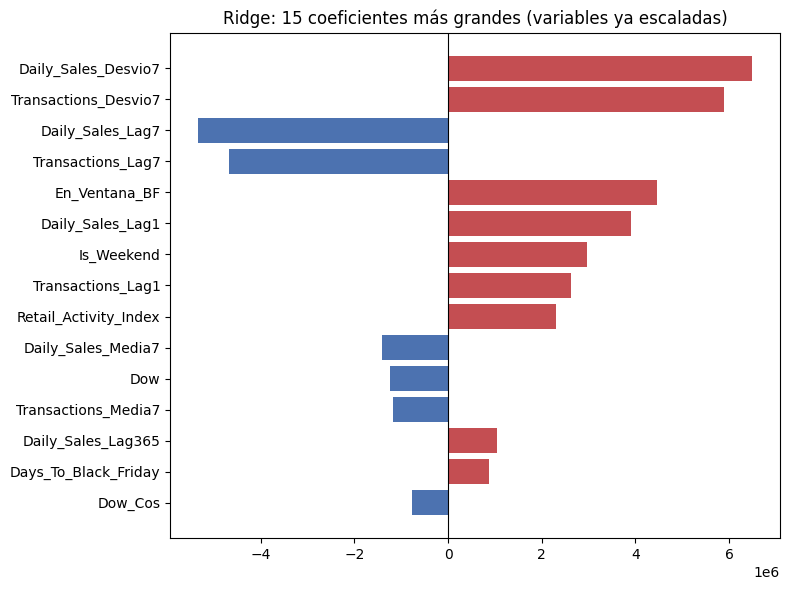

,0
Daily_Sales_Desvio7,6.494934e+06
Transactions_Desvio7,5.880560e+06
Daily_Sales_Lag7,-5.338607e+06
Transactions_Lag7,-4.672051e+06
En_Ventana_BF,4.463415e+06
Daily_Sales_Lag1,3.908787e+06
Is_Weekend,2.960327e+06
Transactions_Lag1,2.618133e+06
Retail_Activity_Index,2.311771e+06
Daily_Sales_Media7,-1.409775e+06


In [36]:
# Celda: coeficientes de Ridge
modelo_ridge = ridge.best_estimator_.named_steps["ridge"]
coef_ridge = pd.Series(modelo_ridge.coef_, index=X_train_val_imp.columns)
coef_ridge = coef_ridge.reindex(coef_ridge.abs().sort_values(ascending=False).index)

top_n = 15
fig, ax = plt.subplots(figsize=(8, 6))
top = coef_ridge.head(top_n)[::-1]
colores_coef = [PALETA[3] if v > 0 else PALETA[0] for v in top]
ax.barh(top.index, top.values, color=colores_coef)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"Ridge: {top_n} coeficientes más grandes (variables ya escaladas)")
plt.tight_layout()
plt.show()

coef_ridge.head(top_n)

Los coeficientes más grandes de Ridge son variables autorregresivas de corto plazo
(`Daily_Sales_Desvio7`, `Transactions_Desvio7`, `Daily_Sales_Lag7`, `Daily_Sales_Lag1`) y la
cercanía a Black Friday (`En_Ventana_BF`, `Days_To_Black_Friday`), además de `Is_Weekend` y `Dow`,
que reflejan la estacionalidad semanal ya vista en el TP2.

Los signos de coeficientes individuales acá no se pueden leer de forma aislada: hay bastante
multicolinealidad entre lags y medias móviles de la misma serie (por ejemplo `Daily_Sales_Lag7` da
negativo pese a que uno esperaría que más venta hace 7 días se asocie con más venta hoy). Eso pasa
porque varias variables correlacionadas entre sí se reparten un efecto que en conjunto sí tiene
sentido, y Ridge no tiene forma de elegir cuál se queda con el peso.

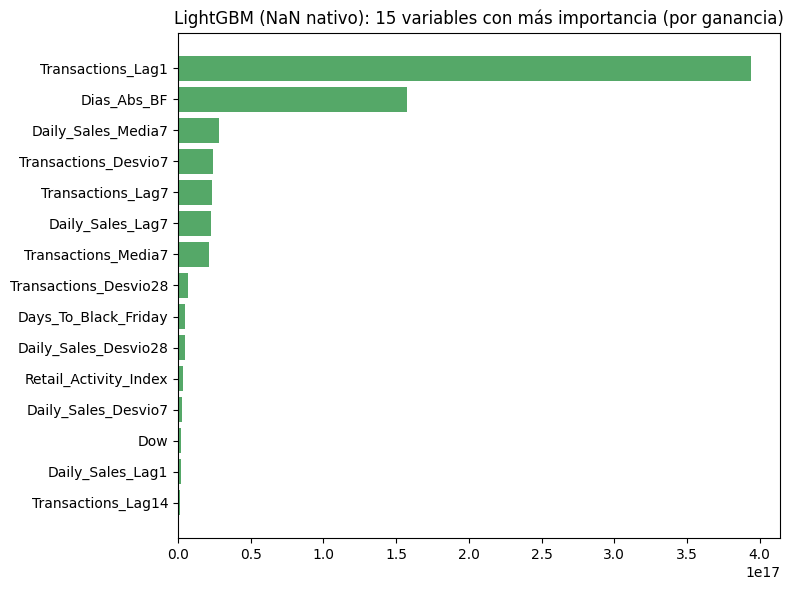

,gain,split
Transactions_Lag1,3.942958e+17,269
Dias_Abs_BF,1.576100e+17,135
Daily_Sales_Media7,2.838472e+16,147
Transactions_Desvio7,2.433389e+16,193
Transactions_Lag7,2.361829e+16,211
Daily_Sales_Lag7,2.260360e+16,260
Transactions_Media7,2.111815e+16,150
Transactions_Desvio28,7.076840e+15,154
Days_To_Black_Friday,5.045870e+15,49
Daily_Sales_Desvio28,4.920909e+15,200


In [37]:
# Celda: importancia de variables en LightGBM (NaN nativo)
modelo_lgbm = lgbm_nan.best_estimator_

imp_split = pd.Series(modelo_lgbm.booster_.feature_importance(importance_type="split"),
                      index=X_train_val_nan.columns)
imp_gain = pd.Series(modelo_lgbm.booster_.feature_importance(importance_type="gain"),
                     index=X_train_val_nan.columns)

top_n = 15
top_gain = imp_gain.sort_values(ascending=False).head(top_n)[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_gain.index, top_gain.values, color=PALETA[2])
ax.set_title(f"LightGBM (NaN nativo): {top_n} variables con más importancia (por ganancia)")
plt.tight_layout()
plt.show()

pd.DataFrame({"gain": imp_gain, "split": imp_split}).sort_values("gain", ascending=False).head(top_n)

En LightGBM la importancia está mucho más concentrada: `Transactions_Lag1` y `Dias_Abs_BF`
(distancia absoluta a Black Friday, sin signo) juntas superan por lejos al resto de las variables,
tanto en `gain` como en `split`. Es una diferencia de fondo con Ridge: un árbol puede capturar de
un solo corte una combinación de variables correlacionadas, mientras que un modelo lineal tiene
que repartir ese mismo efecto entre varias.

También llama la atención que LightGBM prefiera la distancia absoluta a BF (`Dias_Abs_BF`, forma
de "V": el error es simétrico antes y después del evento) mientras Ridge usa la distancia con
signo más el flag `En_Ventana_BF`, porque una suma lineal no puede replicar bien una forma en V con
una sola variable numérica sin combinarla con otra.

### Cierre del punto g)

Ambos modelos coinciden entre sí y con los hallazgos del TP2: se apoyan fuerte en variables
autorregresivas de corto plazo y en la cercanía a Black Friday. `Retail_Activity_Index` aparece
con peso relevante en los dos, pero conviene aclarar la diferencia entre importancia predictiva y
causalidad: como ya se advirtió en el TP2, es una variable que se mueve con el paso del tiempo
junto con las ventas (ambas crecen con la tendencia del negocio), no hay evidencia de que el
índice cause las ventas. Que una variable sea importante para predecir no significa que el negocio
pueda intervenir sobre ella para cambiar el resultado.

## h) Predicción desde un único origen

Hasta acá, cada predicción de 2024 usaba información real de días anteriores (esquema "un paso
adelante"): para predecir el 5 de julio, el modelo tiene el dato real del 4 de julio, de hace una
semana, de hace un año, etc. Es razonable si todos los días se reciben datos frescos.

Este punto plantea un escenario distinto: solo se sabe lo que pasó hasta el 31 de diciembre de
2023, y hay que proyectar los 366 días de 2024 de una sola vez, sin recibir datos reales en el
medio. Es el escenario típico de un presupuesto anual armado con anticipación.

La diferencia clave es qué pasa con los lags de corto plazo: al predecir el 2 de enero de 2024, el
lag de 1 día (1 de enero) es un dato real. Pero al predecir, digamos, el 15 de marzo, el lag de 1
día ya cae dentro de 2024 y no hay dato real: hay que usar la predicción que el propio modelo hizo
para ese día. Esto se llama predicción **recursiva**: cada predicción se retroalimenta con
predicciones anteriores del mismo modelo, en vez de con datos reales, y los errores se pueden ir
acumulando de un día al siguiente.

El lag de 365 días es la excepción: como siempre apunta a un año antes, durante todo 2024 sigue
disponible como dato real (apunta a 2023).

### Por qué se sacan las variables de Transactions

En el esquema recursivo, no solo `Daily_Sales` es desconocida hacia adelante: `Transactions`
también lo es, y no hay ningún modelo entrenado para pronosticarla. Antes de decidir qué hacer,
chequeamos qué tan parecida es a `Daily_Sales`.

In [38]:
# Celda: correlación entre Daily_Sales y Transactions, para justificar sacar
# las columnas de Transactions del modelo del punto h
print("Correlación de Pearson:", daily["Daily_Sales"].corr(daily["Transactions"]))
print("Correlación de Spearman:", daily["Daily_Sales"].corr(daily["Transactions"], method="spearman"))

Correlación de Pearson: 0.9924393063059527
Correlación de Spearman: 0.9293139821922982


In [39]:
# Celda: correlación entre cada lag/rolling de Daily_Sales y su equivalente de Transactions,
# para confirmar que sacar las columnas de Transactions del modelo del punto h no pierde
# información relevante (cada una tiene una "gemela" casi idéntica en Daily_Sales)
pares = ["Lag1", "Lag7", "Lag14", "Lag28", "Lag365", "Media7", "Desvio7", "Media28", "Desvio28"]

correlaciones = pd.Series({
    p: daily[f"Daily_Sales_{p}"].corr(daily[f"Transactions_{p}"]) for p in pares
})
correlaciones.round(3)

,0
Lag1,0.992
Lag7,0.993
Lag14,0.993
Lag28,0.993
Lag365,0.998
Media7,0.992
Desvio7,0.995
Media28,0.987
Desvio28,0.995


La correlación entre `Daily_Sales` y `Transactions` es prácticamente perfecta (Pearson 0,992,
Spearman 0,929), y lo mismo pasa entre cada lag o rolling de una y su equivalente de la otra
(entre 0,987 y 0,998). Es decir, casi toda la información que aportarían las variables de
`Transactions` ya está contenida en las de `Daily_Sales`.

Con esto, se descartan dos alternativas más costosas (congelar `Transactions` en su último valor
real de 2023, o armar un mini-pronóstico aparte solo para esa variable) y se opta por la más
simple: sacar directamente las 9 columnas de `Transactions_*` del modelo de este punto, confiando
en que `Daily_Sales_*` ya trae casi la misma señal.

Reentrenamos LightGBM (NaN nativo) y Ridge (flag + imputación) sobre este nuevo conjunto de 24
variables (`FEATURES_H`), usando los mismos hiperparámetros ya elegidos en el punto d): no hace
falta correr de nuevo el `GridSearchCV`, alcanza con reentrenar sobre las columnas nuevas.

In [40]:
# Celda: variables y modelos para el punto h (sin Transactions_*)
COLUMNAS_TRANSACTIONS = [c for c in FEATURES if c.startswith("Transactions_")]
FEATURES_H = [c for c in FEATURES if c not in COLUMNAS_TRANSACTIONS]
print(f"Se sacan {len(COLUMNAS_TRANSACTIONS)} columnas de Transactions. Quedan {len(FEATURES_H)} features.")

X_train_val_h_nan = X_train_val_nan[FEATURES_H].copy()

COLUMNAS_CON_HISTORIA_INCOMPLETA_H = [c for c in FEATURES_H if X_train_val_h_nan[c].isna().any()]
X_train_val_h_imp = X_train_val_h_nan.copy()
medianas_h = {}
for col in COLUMNAS_CON_HISTORIA_INCOMPLETA_H:
    medianas_h[col] = X_train_val_h_nan[col].median()
    X_train_val_h_imp[f"{col}_Disponible"] = X_train_val_h_nan[col].notna().astype(int)
    X_train_val_h_imp[col] = X_train_val_h_nan[col].fillna(medianas_h[col])

# Mismos hiperparametros ya elegidos en el punto d, solo cambia el conjunto de variables
lgbm_h = LGBMRegressor(random_state=42, verbose=-1, **lgbm_nan.best_params_)
lgbm_h.fit(X_train_val_h_nan, y_train_val)

ridge_h = make_pipeline(StandardScaler(), Ridge(random_state=42, alpha=ridge.best_params_["ridge__alpha"]))
ridge_h.fit(X_train_val_h_imp, y_train_val)

Se sacan 9 columnas de Transactions. Quedan 24 features.


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('ridge', Ridge(alpha=10.0, random_state=42))])

### El bucle recursivo

Para cada una de las 366 fechas de 2024, en orden: tomamos las variables que se conocen de
antemano (calendario, cercanía a BF, contexto económico) directo de la tabla de test, recalculamos
las variables autorregresivas a partir de una "historia" que se va actualizando con cada
predicción nueva, y guardamos la predicción.

Cada modelo tiene su propia historia, independiente del otro: LightGBM se retroalimenta solo con
sus propias predicciones, y Ridge con las suyas, para que un modelo no termine ayudando (o
perjudicando) al otro.

In [41]:
# Celda: prediccion recursiva de los 366 dias de 2024, un dia a la vez
CONOCIDAS_H = [c for c in FEATURES_H if not c.startswith("Daily_Sales_")]

def features_autoregresivas(historia, fecha):
    fila = {}
    for lag in [1, 7, 14, 28, 365]:
        fila[f"Daily_Sales_Lag{lag}"] = historia.loc[fecha - pd.Timedelta(days=lag)]
    fila["Daily_Sales_Media7"] = historia.iloc[-7:].mean()
    fila["Daily_Sales_Desvio7"] = historia.iloc[-7:].std()
    fila["Daily_Sales_Media28"] = historia.iloc[-28:].mean()
    fila["Daily_Sales_Desvio28"] = historia.iloc[-28:].std()
    return fila

historia_lgbm = daily.set_index("Purchase_Date")["Daily_Sales"].loc[:"2023-12-31"].copy()
historia_ridge = historia_lgbm.copy()

pred_lgbm_h, pred_ridge_h = [], []

for fecha in test["Purchase_Date"]:
    conocidas = test.loc[test["Purchase_Date"] == fecha, CONOCIDAS_H].iloc[0].to_dict()

    fila_lgbm = {**conocidas, **features_autoregresivas(historia_lgbm, fecha)}
    x_nan = pd.DataFrame([fila_lgbm])[FEATURES_H]
    p_lgbm = lgbm_h.predict(x_nan)[0]

    fila_ridge = {**conocidas, **features_autoregresivas(historia_ridge, fecha)}
    x_imp = pd.DataFrame([fila_ridge])[FEATURES_H]
    for col in COLUMNAS_CON_HISTORIA_INCOMPLETA_H:
        x_imp[f"{col}_Disponible"] = 1
    x_imp = x_imp[X_train_val_h_imp.columns]
    p_ridge = ridge_h.predict(x_imp)[0]

    historia_lgbm.loc[fecha] = p_lgbm
    historia_ridge.loc[fecha] = p_ridge
    pred_lgbm_h.append(p_lgbm)
    pred_ridge_h.append(p_ridge)

pred_h = pd.DataFrame({
    "Purchase_Date": test["Purchase_Date"].values,
    "Real": y_test.values,
    "LGBM_h": pred_lgbm_h,
    "Ridge_h": pred_ridge_h,
})
pred_h.head()

,Purchase_Date,Real,LGBM_h,Ridge_h
0,2024-01-01,10264703,4.133888e+06,1.129663e+07
1,2024-01-02,10198877,1.349432e+07,7.465335e+06
2,2024-01-03,11022144,1.129501e+07,8.463947e+06
3,2024-01-04,10355256,1.047521e+07,1.159117e+07
4,2024-01-05,10705226,1.138459e+07,1.258635e+07


La tabla muestra las primeras predicciones de enero de 2024: como recién arranca el esquema
recursivo, todavía coinciden casi en su totalidad con lo que haría el esquema de un paso (los lags
cortos siguen siendo datos reales de fines de 2023).

### Real vs. predicción recursiva

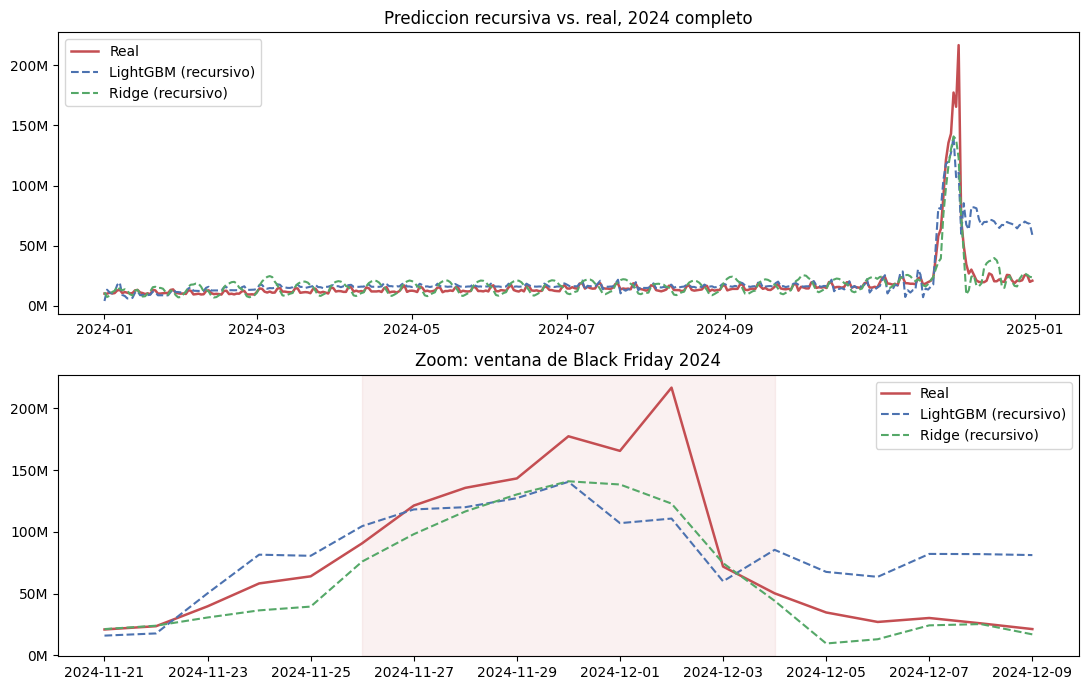

In [42]:
# Celda: real vs. predicciones recursivas (2024 completo y zoom en Black Friday)
pred_h["En_Ventana_BF"] = test["En_Ventana_BF"].values

ventana_h = pred_h[pred_h["En_Ventana_BF"] == 1]
margen = pd.Timedelta(days=5)
zoom_h = pred_h[
    (pred_h["Purchase_Date"] >= ventana_h["Purchase_Date"].min() - margen) &
    (pred_h["Purchase_Date"] <= ventana_h["Purchase_Date"].max() + margen)
]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, datos, titulo in [(axes[0], pred_h, "Prediccion recursiva vs. real, 2024 completo"),
                          (axes[1], zoom_h, "Zoom: ventana de Black Friday 2024")]:
    ax.plot(datos["Purchase_Date"], datos["Real"], label="Real", color=PALETA[3], linewidth=1.8)
    ax.plot(datos["Purchase_Date"], datos["LGBM_h"], label="LightGBM (recursivo)", color=PALETA[0], linestyle="--")
    ax.plot(datos["Purchase_Date"], datos["Ridge_h"], label="Ridge (recursivo)", color=PALETA[2], linestyle="--")
    ax.set_title(titulo)
    millones(ax)
    ax.legend()
axes[1].axvspan(ventana_h["Purchase_Date"].min(), ventana_h["Purchase_Date"].max(), color=PALETA[3], alpha=0.08)
plt.tight_layout()
plt.show()

En el gráfico se nota que LightGBM empieza a subir antes de tiempo a comienzos de noviembre, y que
después del pico de Black Friday se queda pegado en valores altos (65 a 80 millones) durante
varias semanas, mientras la venta real ya volvió a niveles de 20 a 30 millones. Ridge reacciona
más despacio al pico pero se recupera más rápido después.

### Cómo crece el error con el horizonte

Miramos el error (con una ventana móvil de 14 días, para suavizar el ruido día a día) en función
de cuántos días pasaron desde el origen de la predicción, el 31 de diciembre de 2023.

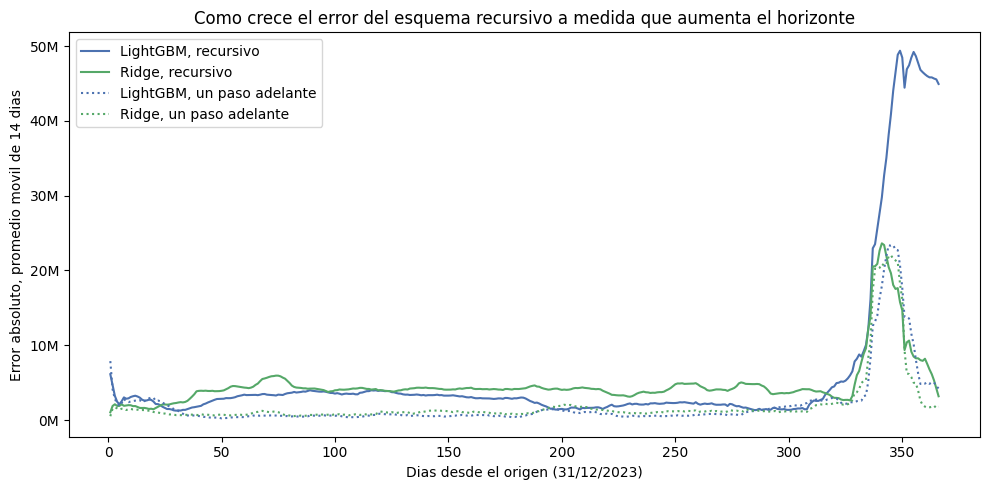

In [43]:
# Celda: como crece el error a medida que aumenta el horizonte (dias desde el 31/12/2023)
pred_h["Horizonte"] = (pred_h["Purchase_Date"] - pd.Timestamp("2023-12-31")).dt.days
pred_h["Real_LGBM_onestep"] = pred_test["LGBM_NaN"].values  # el de "un paso" del punto e, misma fecha
pred_h["Real_Ridge_onestep"] = pred_test["Ridge"].values

def error_movil_por_horizonte(real, pred, ventana=14):
    err = (real - pred).abs()
    return err.rolling(ventana, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["LGBM_h"]),
        label="LightGBM, recursivo", color=PALETA[0])
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["Ridge_h"]),
        label="Ridge, recursivo", color=PALETA[2])
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["Real_LGBM_onestep"]),
        label="LightGBM, un paso adelante", color=PALETA[0], linestyle=":")
ax.plot(pred_h["Horizonte"], error_movil_por_horizonte(pred_h["Real"], pred_h["Real_Ridge_onestep"]),
        label="Ridge, un paso adelante", color=PALETA[2], linestyle=":")
ax.set_xlabel("Dias desde el origen (31/12/2023)")
ax.set_ylabel("Error absoluto, promedio movil de 14 dias")
ax.set_title("Como crece el error del esquema recursivo a medida que aumenta el horizonte")
millones(ax)
ax.legend()
plt.tight_layout()
plt.show()

Las cuatro curvas (LightGBM y Ridge, recursivo y un paso) se mantienen bajas y parejas durante
casi todo el año, hasta cerca del día 320 (fines de octubre), y recién ahí se disparan todas
juntas cerca de Black Friday. Esto es importante: el error **no** se acumula de forma gradual a lo
largo del año por el solo hecho de ser recursivo, es un fenómeno concentrado en el evento.
LightGBM recursivo llega a un pico de error móvil de alrededor de 50 millones y tarda varios días
en bajar de 45 millones, mientras que Ridge recursivo y las dos curvas de un paso llegan a un pico
menor (alrededor de 23 millones) y bajan más rápido.

In [44]:
# Celda: metricas globales, recursivo vs. un paso adelante
def metricas_h(real, pred):
    return {
        "RMSE (M)": np.sqrt(np.mean((real - pred) ** 2)) / 1e6,
        "MAE (M)": np.mean(np.abs(real - pred)) / 1e6,
    }

pd.DataFrame({
    "LGBM recursivo": metricas_h(pred_h["Real"], pred_h["LGBM_h"]),
    "LGBM un paso": metricas_h(pred_h["Real"], pred_h["Real_LGBM_onestep"]),
    "Ridge recursivo": metricas_h(pred_h["Real"], pred_h["Ridge_h"]),
    "Ridge un paso": metricas_h(pred_h["Real"], pred_h["Real_Ridge_onestep"]),
}).round(2)

,LGBM recursivo,LGBM un paso,Ridge recursivo,Ridge un paso
RMSE (M),14.88,5.94,8.01,6.85
MAE (M),6.81,2.07,4.79,2.07


Comparando el error global de los dos esquemas: LightGBM empeora fuerte al pasar a recursivo
(RMSE de 5,94M a 14,88M, +150%), mientras que Ridge se degrada mucho menos (de 6,85M a 8,01M,
+17%). El ranking se invierte respecto del punto e), donde LightGBM ganaba: acá gana Ridge, y por
margen amplio.

Por qué le cuesta más a LightGBM: un árbol de decisión no extrapola, solo puede predecir valores
que ya vio en el entrenamiento repartidos entre sus hojas. Cuando el esquema recursivo empieza a
alimentar al modelo con sus propias predicciones (que pueden salirse del rango que el árbol
conoce, sobre todo alrededor de un evento tan grande como Black Friday), LightGBM cae en la hoja
más parecida que tiene disponible, que no necesariamente es la correcta. Ridge, al ser una suma
lineal, extrapola de forma más suave aunque tampoco sea perfecta.

In [45]:
# Celda: desempeño por zona del esquema recursivo (mismas zonas del punto f)
pred_h["Dias_BF"] = test["Days_To_Black_Friday"].values
pred_h["Zona"] = np.select(
    [pred_h["En_Ventana_BF"] == 1, pred_h["Dias_BF"] > 5],
    ["Ventana BF", "Después de la ventana"],
    default="Resto del año",
)

modelos_h = ["LGBM_h", "Ridge_h"]
zonas = ["Ventana BF", "Después de la ventana", "Resto del año"]

def por_zona_h(f):
    filas = {"Global": {m: f(pred_h["Real"], pred_h[m]) for m in modelos_h}}
    for z in zonas:
        g = pred_h[pred_h["Zona"] == z]
        filas[z] = {m: f(g["Real"], g[m]) for m in modelos_h}
    return pd.DataFrame(filas)

rmse_h = lambda r, p: np.sqrt(np.mean((r - p) ** 2)) / 1e6
mae_h = lambda r, p: np.mean(np.abs(r - p)) / 1e6

print("RMSE recursivo (M)"); display(por_zona_h(rmse_h).round(2))
print("MAE recursivo (M)"); display(por_zona_h(mae_h).round(2))

RMSE recursivo (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_h,14.88,44.85,46.64,3.55
Ridge_h,8.01,36.83,9.38,5.19


MAE recursivo (M)


,Global,Ventana BF,Después de la ventana,Resto del año
LGBM_h,6.81,33.01,46.33,2.86
Ridge_h,4.79,26.26,6.81,4.03


El desglose por zona confirma la hipótesis del gráfico: en la ventana de BF ambos modelos
empeoran de forma parecida respecto del esquema de un paso (LightGBM 28,30M a 44,85M de RMSE,
Ridge 41,04M a 36,83M, este último incluso mejora un poco), pero es **después** de la ventana
donde se abre la brecha: LightGBM pasa de 13,54M a 46,64M de RMSE (se degrada mucho), mientras
Ridge pasa de 6,24M a 9,38M (se degrada bastante menos). Es la misma cicatriz post-BF que ya se
había visto en el esquema de un paso (punto f), pero acá el efecto es mucho más fuerte porque el
modelo no tiene la oportunidad de corregirse con un dato real al día siguiente: sigue
alimentándose de sus propias predicciones equivocadas.

### Cierre del punto h)

El escenario recursivo deja un hallazgo central: Ridge, el modelo más simple, es mucho más
robusto que LightGBM cuando hay que proyectar sin recibir datos reales en el camino. La razón de
fondo es la misma en los tres fenómenos que aparecen en este punto: las variables autorregresivas
dejan de ser datos reales y pasan a ser predicciones del propio modelo, con poca práctica (solo
dos Black Friday en el entrenamiento) para saber cuánto pesarlas, y un árbol en particular no sabe
qué hacer cuando esas variables se salen del rango que conoció en el entrenamiento. Para un caso
de uso real como un presupuesto anual, esto sugiere preferir el modelo más simple, aunque pierda
contra el boosting en el esquema de un paso.

## Conclusión general de la Parte 1

Los modelos supervisados (LightGBM y Ridge) superan claramente a los dos baselines en el esquema
principal de predicción a un paso adelante, tanto en el desempeño global (punto e) como en Black
Friday específicamente (punto f), aunque ningún modelo gana en todas las zonas: LightGBM
representa mejor el pico del evento, Ridge y el SARIMA son más confiables en las semanas
posteriores.

Ambos modelos se apoyan en las mismas señales (autorregresivas de corto plazo y cercanía a Black
Friday), coincidiendo con lo que ya había mostrado el TP2, aunque LightGBM concentra esa señal en
pocas variables y Ridge la reparte entre muchas correlacionadas (punto g).

El escenario recursivo del punto h) muestra que este tipo de modelos no envejece igual: Ridge se
degrada apenas al pasar de un esquema de un paso a uno recursivo (+17% de RMSE), mientras que
LightGBM se degrada mucho más (+150%), sobre todo en las semanas posteriores a Black Friday,
porque un árbol no extrapola bien frente a valores que rompen el rango visto en el entrenamiento.
Es un hallazgo con implicancia práctica: para un uso como presupuesto anual (que necesita el
esquema recursivo), un modelo lineal más simple puede ser la opción más robusta, aunque pierda
contra el boosting en el escenario de predicción día a día con datos frescos.


---

<a id="parte-2"></a>


# TP3 — Parte 2: Segmentación de clientes

**Mentoría · Diplomatura en Ciencia de Datos (FAMAF 2026)**
**Autoría:** Sergio Santamarina
**Dataset:** `bf_dataset.csv` (el del TP1) · Problema no supervisado

---

### Qué cubre esta parte

| Punto | Contenido | Estado |
|---|---|---|
| **2.a** | Segmentación de clientes según comportamiento de compra | **acá** |
| **2.b** | Caracterización sociodemográfica de esos clusters | **acá** |
| **2.c** | Segmentación incorporando las variables sociodemográficas | **acá** |

Esta parte es **autocontenida**: carga sus datos, fija su semilla y corre de principio a fin sin
depender de las otras partes. Está pensada para integrarse después al entregable del grupo.

> ## ⚠ Dependencia con la Parte 3 y la Parte 4 — leer antes de arrancar
>
> El enunciado impone una restricción que **acopla esta parte con las otras dos**, y conviene
> resolverla por acuerdo explícito antes de que cada uno avance:
>
> - **Punto 3.a:** *"Aplicar **los mismos métodos de clustering** utilizados en la segmentación de
>   clientes."*
> - **Punto 4:** *"La comparación entre representaciones deberá realizarse utilizando **el mismo
>   método de clustering**."*
>
> Es decir: **los métodos que se fijan acá condicionan la Parte 3.** Si quien hace productos elige
> otros métodos, la Parte 4 no se puede escribir.
>
> ### Contrato de métodos que fija esta notebook
>
> | Qué | Decisión | Dónde se justifica |
> |---|---|---|
> | **Método 1** | `KMeans` (particional, centroides) | 2.a |
> | **Método 2** | `AgglomerativeClustering(linkage="ward")` (jerárquico aglomerativo) | 2.a |
> | **Semilla** | `SEMILLA = 42` (en `random_state` y en todo muestreo) | 0 |
> | **Escalado** | `StandardScaler` sobre las features transformadas | 2.a |
> | **Proyección 2D** | `PCA` sobre la matriz escalada | 2.a |
> | **Métricas de calidad** | silhouette, Calinski-Harabasz, Davies-Bouldin | 2.a |
> | **Métrica de concordancia** | Adjusted Rand Index (ARI) entre particiones | 2.a |
> | **Tratamiento de categóricas** | one-hot **reponderado por bloque** (ver 2.c) | 2.c |
>
> **Lo que hay que pasarle a quien hace la Parte 3:** los dos métodos, la semilla, y sobre todo el
> criterio de reponderación de 2.c — porque en productos va a enfrentar exactamente el mismo problema
> al agregar el perfil de los compradores, y si lo trata distinto la comparación de la Parte 4 mezcla
> dos efectos.
>
> **Lo que la Parte 4 va a necesitar de acá:** las etiquetas de cluster de 2.a y de 2.c para los dos
> métodos. Las exportamos a CSV al final de la notebook.

## 0. Preparación

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings, os

warnings.filterwarnings("ignore")

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 110,
                     "axes.titlesize": 12.5, "axes.titleweight": "bold",
                     "axes.labelsize": 10.5, "font.size": 9.5})
PALETA = sns.color_palette("deep")
COL_CLUSTER = [PALETA[0], PALETA[2], PALETA[3], PALETA[1], PALETA[4], PALETA[5]]

def miles(ax, eje="y"):
    f = mticker.FuncFormatter(lambda v, p: f"{v:,.0f}")
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)

# Bitácora de decisiones
DECISIONES = []
def registrar(punto, decision, justificacion):
    DECISIONES.append({"punto": punto, "decision": decision,
                       "justificacion": justificacion})

print(f"pandas {pd.__version__} | numpy {np.__version__} | SEMILLA = {SEMILLA}")

pandas 2.2.3 | numpy 2.1.3 | SEMILLA = 42


In [47]:
# ============ Carga del dataset del TP1 ============
ARCHIVO = "bf_dataset.csv"
URL_RAW = ("https://raw.githubusercontent.com/dyvanoff/"
           f"blackfriday_sales_prediction/main/datos/{ARCHIVO}")

def cargar():
    """Cadena de alternativas para que la notebook corra en cualquier contexto."""
    for nombre, ruta in [("raw de GitHub", URL_RAW),
                         ("carpeta datos/", f"datos/{ARCHIVO}"),
                         ("archivo local", ARCHIVO),
                         ("repo clonado", f"blackfriday_sales_prediction/datos/{ARCHIVO}"),
                         ("Drive montado", f"/content/drive/MyDrive/{ARCHIVO}")]:
        try:
            datos = pd.read_csv(ruta)
            print(f"OK — leído desde {nombre}")
            return datos
        except Exception:
            print(f"  no disponible ({nombre})")
    try:
        from google.colab import files
        print(f"\nSubí {ARCHIVO}:")
        subido = files.upload()
        return pd.read_csv(list(subido.keys())[0])
    except Exception as e:
        raise RuntimeError(
            f"No se pudo cargar {ARCHIVO}. Alternativa:\n"
            f"  !git clone https://github.com/dyvanoff/blackfriday_sales_prediction\n{e}")

tx = cargar()
print(f"\ntransacciones: {len(tx):,}")
print(f"clientes únicos:  {tx.User_ID.nunique():,}")
print(f"productos únicos: {tx.Product_ID.nunique():,}")
print(f"\nnulos por variable:")
print(tx.isnull().sum()[lambda s: s > 0].to_string())
print("\n(los nulos de Product_Category_2/3 son estructurales: el producto no tiene")
print(" esa categoría. Lo verificamos en el TP2 sobre los 3.631 productos.)")

OK — leído desde raw de GitHub

transacciones: 550,068
clientes únicos:  5,891
productos únicos: 3,631

nulos por variable:
Product_Category_2    173638
Product_Category_3    383247

(los nulos de Product_Category_2/3 son estructurales: el producto no tiene
 esa categoría. Lo verificamos en el TP2 sobre los 3.631 productos.)


---
## 2.a — Segmentación de clientes según comportamiento de compra

### Unidad de observación

Pasamos de la **transacción** (550.068 filas) al **cliente** (5.891 filas). Cada fila resume el
comportamiento de compra de un `User_ID`.

Recordemos del TP1 que en este dataset cada par (cliente, producto) aparece **una sola vez** y
`Purchase` es el *monto total del mes* de ese cliente en ese producto — no un ticket individual. Eso
condiciona qué variables se pueden construir y lo declaramos al definirlas.

### Variables de comportamiento

El enunciado pide representar frecuencia, gasto, características del ticket y diversidad. Construimos
cuatro bloques:

| Bloque | Variables | Qué capturan |
|---|---|---|
| **Frecuencia** | `n_tx` | cuántos productos distintos compró (intensidad de relación) |
| **Gasto** | `gasto_total` | valor total del cliente |
| **Ticket** | `ticket_medio`, `ticket_mediano`, `ticket_sd`, `ticket_max`, `cv_ticket` | nivel y variabilidad del monto por producto |
| **Diversidad** | `n_categorias`, `entropia_cat`, `share_cat_top`, `n_cat_media` | amplitud vs. concentración del carrito |

Dos variables merecen explicación porque no son obvias:

- **`entropia_cat`** — entropía de Shannon sobre la distribución de compras entre categorías. Mide
  diversidad de forma continua: 0 si el cliente compra en una sola categoría, máxima si reparte
  parejo. Es más informativa que contar categorías, porque distingue "compró en 10 categorías pero
  el 90% en una" de "repartió parejo en 10".
- **`n_cat_media`** — promedio de categorías informadas de los productos que compró (1, 2 o 3). En el
  TP1 y el TP2 verificamos que esta variable es un **proxy del precio**: los productos con taxonomía
  completa promedian \\$13.433 contra \\$8.695 los de una sola categoría. Captura si el cliente se
  inclina a productos complejos o simples.

In [48]:
# ============ CONSTRUCCIÓN DE LA TABLA DE CLIENTES ============
tx["n_cat"] = 3 - tx[["Product_Category_2", "Product_Category_3"]].isna().sum(axis=1)

g = tx.groupby("User_ID")
clientes = pd.DataFrame({
    "n_tx":           g.size(),
    "gasto_total":    g.Purchase.sum(),
    "ticket_medio":   g.Purchase.mean(),
    "ticket_mediano": g.Purchase.median(),
    "ticket_sd":      g.Purchase.std(),
    "ticket_max":     g.Purchase.max(),
    "n_productos":    g.Product_ID.nunique(),
    "n_categorias":   g.Product_Category_1.nunique(),
    "n_cat_media":    g.n_cat.mean(),
})

# Diversidad: entropía de Shannon y concentración sobre Product_Category_1
conteo = tx.groupby(["User_ID", "Product_Category_1"]).size()
total_cli = conteo.groupby("User_ID").sum()
prop = conteo / total_cli
clientes["entropia_cat"]  = -(prop * np.log(prop)).groupby("User_ID").sum()
clientes["share_cat_top"] = conteo.groupby("User_ID").max() / total_cli
clientes["cv_ticket"]     = clientes.ticket_sd / clientes.ticket_medio

print(f"Tabla de clientes: {clientes.shape[0]:,} filas x {clientes.shape[1]} columnas")
print(f"Nulos: {clientes.isnull().sum().sum()}")
display(clientes.describe().T.round(2))

Tabla de clientes: 5,891 filas x 12 columnas
Nulos: 0


,count,mean,std,min,25%,50%,75%,max
n_tx,"5,891.000",93.370,107.190,6.000,26.000,54.000,117.000,"1,026.000"
gasto_total,"5,891.000","865,016.590","943,644.540","46,681.000","237,678.000","521,213.000","1,119,249.500","10,536,909.000"
ticket_medio,"5,891.000","9,568.840","1,890.090","2,318.730","8,287.210","9,386.210","10,654.630","18,577.890"
ticket_mediano,"5,891.000","8,891.920","2,350.360","1,706.000","7,651.750","8,218.000","9,807.000","20,297.500"
ticket_sd,"5,891.000","4,863.440",864.660,"1,132.590","4,344.980","4,878.190","5,401.850","8,986.130"
ticket_max,"5,891.000","20,421.540","2,480.420","4,640.000","19,555.000","20,469.000","21,423.500","23,961.000"
n_productos,"5,891.000",93.370,107.190,6.000,26.000,54.000,117.000,"1,026.000"
n_categorias,"5,891.000",9.640,3.600,1.000,7.000,9.000,12.000,19.000
n_cat_media,"5,891.000",2.000,0.250,1.080,1.820,1.980,2.170,2.830
entropia_cat,"5,891.000",1.620,0.360,-0.000,1.440,1.690,1.870,2.420


In [49]:
# ============ DETECCIÓN DE REDUNDANCIAS ============
# Antes de escalar conviene mirar si alguna variable es función exacta de otra:
# meterlas duplicadas al clustering pondera ese aspecto dos veces.

print("Redundancias exactas")
print("=" * 66)
print(f"  n_productos es idéntica a n_tx:        {(clientes.n_productos == clientes.n_tx).all()}")
print(f"  gasto_total == n_tx x ticket_medio:    "
      f"{np.allclose(clientes.gasto_total, clientes.n_tx * clientes.ticket_medio)}")

print("\nPares con |Spearman| > 0,85")
print("-" * 66)
S = clientes.corr(method="spearman")
for i, a in enumerate(clientes.columns):
    for b in clientes.columns[i+1:]:
        if abs(S.loc[a, b]) > 0.85:
            print(f"  {a:<16} <-> {b:<16} {S.loc[a, b]:+.3f}")

print("\nAsimetría (para decidir transformación)")
print("-" * 66)
print(clientes.skew().round(2).sort_values(ascending=False).to_string())

Redundancias exactas
  n_productos es idéntica a n_tx:        True
  gasto_total == n_tx x ticket_medio:    True

Pares con |Spearman| > 0,85
------------------------------------------------------------------
  n_tx             <-> gasto_total      +0.981
  n_tx             <-> n_productos      +1.000
  gasto_total      <-> n_productos      +0.981
  ticket_medio     <-> ticket_mediano   +0.920

Asimetría (para decidir transformación)
------------------------------------------------------------------
n_tx              2.600
n_productos       2.600
gasto_total       2.430
ticket_mediano    1.430
share_cat_top     1.290
cv_ticket         0.640
ticket_medio      0.550
n_categorias      0.340
n_cat_media       0.260
ticket_sd        -0.100
entropia_cat     -1.110
ticket_max       -1.200


> **Decisiones que surgen de esta inspección:**
>
> - **`n_productos` se descarta**: es *idénticamente igual* a `n_tx`. No es una correlación alta, es
>   la misma variable — consecuencia de que en este dataset cada par (cliente, producto) aparece una
>   sola vez, algo que verificamos en el TP1. Incluirla duplicaría el peso de la frecuencia.
> - **`gasto_total` se descarta**: es **exactamente** `n_tx × ticket_medio`. Ya está representado por
>   sus dos factores, y esos factores son más interpretables por separado (un gasto alto puede venir
>   de comprar mucho o de comprar caro, que son perfiles distintos). Lo conservamos fuera del
>   clustering para perfilar los grupos después.
> - **`ticket_mediano` se descarta**: Spearman 0,920 con `ticket_medio`. Aporta poco y con ticket
>   medio alcanza.
> - **`n_tx` se transforma con `log1p`**: asimetría 2,60 (de 6 a 1.026 transacciones). Sin transformar,
>   los pocos clientes hiperactivos se convierten en outliers que dominan la distancia euclídea y
>   K-Means los aísla en clusters de tamaño 1 o 2.
>
> Quedan **9 variables**. Todas se estandarizan (`StandardScaler`) porque ambos métodos usan distancia
> euclídea: sin escalar, `ticket_max` (rango ~19.000) aplastaría a `entropia_cat` (rango ~2,4).

In [50]:
# ============ MATRIZ FINAL ============
from sklearn.preprocessing import StandardScaler

F_COMPORTAMIENTO = ["n_tx", "ticket_medio", "ticket_sd", "ticket_max",
                    "n_categorias", "n_cat_media", "entropia_cat",
                    "share_cat_top", "cv_ticket"]
A_LOG = ["n_tx"]

base = clientes[F_COMPORTAMIENTO].copy()
for c in A_LOG:
    base[c] = np.log1p(base[c])

escalador = StandardScaler()
X_comp = escalador.fit_transform(base.values)

print(f"Matriz de comportamiento: {X_comp.shape[0]:,} clientes x {X_comp.shape[1]} variables")
print(f"Variables: {F_COMPORTAMIENTO}")
print(f"Transformadas con log1p: {A_LOG}")

registrar("2.a", "descartar n_productos, gasto_total y ticket_mediano",
          "n_productos es idéntica a n_tx; gasto_total es el producto exacto de n_tx y "
          "ticket_medio; ticket_mediano tiene Spearman 0,920 con ticket_medio")
registrar("2.a", "log1p sobre n_tx", "asimetría 2,60; sin transformar los clientes "
          "hiperactivos dominan la distancia euclídea")
registrar("2.a", "StandardScaler sobre las 9 variables",
          "ambos métodos usan distancia euclídea: sin escalar manda la variable de mayor rango")

Matriz de comportamiento: 5,891 clientes x 9 variables
Variables: ['n_tx', 'ticket_medio', 'ticket_sd', 'ticket_max', 'n_categorias', 'n_cat_media', 'entropia_cat', 'share_cat_top', 'cv_ticket']
Transformadas con log1p: ['n_tx']


### Elección del número de clusters

Ninguno de los dos métodos determina `k` por sí solo, así que lo elegimos combinando cuatro criterios
en lugar de uno:

| Criterio | Qué mide | Cómo se lee |
|---|---|---|
| **Inercia** (codo) | suma de distancias al centroide | busca el quiebre de la curva |
| **Silhouette** | cohesión interna vs. separación entre grupos | más alto es mejor; rango [−1, 1] |
| **Calinski-Harabasz** | ratio de dispersión entre/dentro | más alto es mejor |
| **Davies-Bouldin** | similitud promedio con el cluster más cercano | **más bajo** es mejor |

Agregamos el **ARI entre K-Means y Ward** para cada `k`: si dos métodos distintos coinciden, es
evidencia de que la estructura existe; si no coinciden, probablemente estemos partiendo un continuo.

In [51]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

RANGO_K = range(2, 9)
N_SILH = 2000     # el silhouette es O(n^2): lo calculamos sobre muestra reproducible

def evaluar_k(X, rango=RANGO_K, semilla=SEMILLA):
    """Corre KMeans y Ward para cada k y devuelve métricas y etiquetas."""
    rng = np.random.default_rng(semilla)
    idx = rng.choice(len(X), min(N_SILH, len(X)), replace=False)
    filas, etiquetas = [], {}
    for k in rango:
        km = KMeans(n_clusters=k, n_init=10, random_state=semilla)
        l_km = km.fit_predict(X)
        l_wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        etiquetas[k] = {"kmeans": l_km, "ward": l_wd}
        filas.append({
            "k": k,
            "inercia": km.inertia_,
            "silh_KM":  silhouette_score(X[idx], l_km[idx]),
            "CH_KM":    calinski_harabasz_score(X, l_km),
            "DB_KM":    davies_bouldin_score(X, l_km),
            "silh_Ward": silhouette_score(X[idx], l_wd[idx]),
            "ARI_KM_Ward": adjusted_rand_score(l_km, l_wd),
        })
    return pd.DataFrame(filas).set_index("k"), etiquetas

diag_comp, etq_comp = evaluar_k(X_comp)
display(diag_comp.round(3))

print(f"k con mejor silhouette (KMeans): {diag_comp.silh_KM.idxmax()}")
print(f"k con mejor Calinski-Harabasz:   {diag_comp.CH_KM.idxmax()}")
print(f"k con mejor Davies-Bouldin:      {diag_comp.DB_KM.idxmin()}")
print(f"k con mayor acuerdo KM-Ward:     {diag_comp.ARI_KM_Ward.idxmax()}")

,inercia,silh_KM,CH_KM,DB_KM,silh_Ward,ARI_KM_Ward
k,,,,,,
2,"40,403.045",0.240,"1,838.866",1.667,0.222,0.492
3,"33,626.706",0.242,"1,697.789",1.437,0.221,0.443
4,"28,209.972",0.222,"1,725.762",1.408,0.142,0.442
5,"25,678.891",0.207,"1,566.698",1.460,0.135,0.465
6,"23,756.239",0.201,"1,449.824",1.458,0.135,0.393
7,"22,365.726",0.167,"1,344.058",1.518,0.132,0.338
8,"21,290.951",0.173,"1,252.421",1.513,0.115,0.367


k con mejor silhouette (KMeans): 3
k con mejor Calinski-Harabasz:   2
k con mejor Davies-Bouldin:      4
k con mayor acuerdo KM-Ward:     2


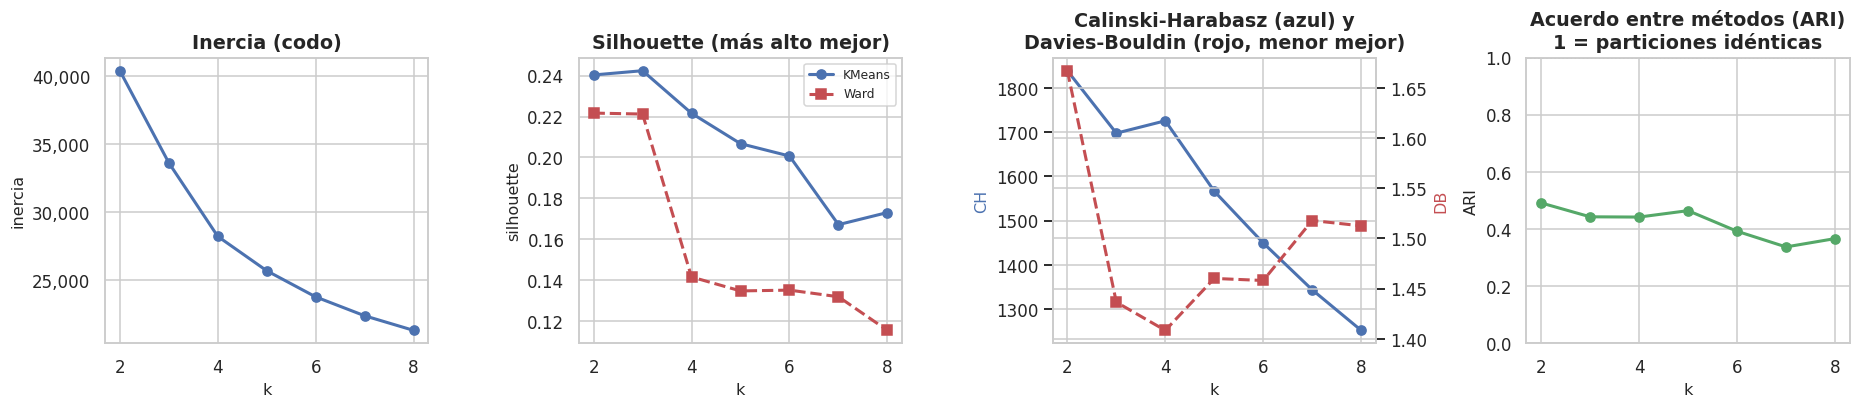

In [52]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))

ax[0].plot(diag_comp.index, diag_comp.inercia, "o-", color=PALETA[0], lw=2)
ax[0].set(title="Inercia (codo)", xlabel="k", ylabel="inercia")
miles(ax[0])

ax[1].plot(diag_comp.index, diag_comp.silh_KM, "o-", color=PALETA[0], lw=2, label="KMeans")
ax[1].plot(diag_comp.index, diag_comp.silh_Ward, "s--", color=PALETA[3], lw=2, label="Ward")
ax[1].set(title="Silhouette (más alto mejor)", xlabel="k", ylabel="silhouette")
ax[1].legend(fontsize=8)

a2 = ax[2].twinx()
ax[2].plot(diag_comp.index, diag_comp.CH_KM, "o-", color=PALETA[0], lw=2)
a2.plot(diag_comp.index, diag_comp.DB_KM, "s--", color=PALETA[3], lw=2)
ax[2].set(title="Calinski-Harabasz (azul) y\nDavies-Bouldin (rojo, menor mejor)", xlabel="k")
ax[2].set_ylabel("CH", color=PALETA[0]); a2.set_ylabel("DB", color=PALETA[3])

ax[3].plot(diag_comp.index, diag_comp.ARI_KM_Ward, "o-", color=PALETA[2], lw=2)
ax[3].axhline(1, color="grey", ls=":", lw=1)
ax[3].set(title="Acuerdo entre métodos (ARI)\n1 = particiones idénticas", xlabel="k",
          ylabel="ARI", ylim=(0, 1))

plt.tight_layout(); plt.show()

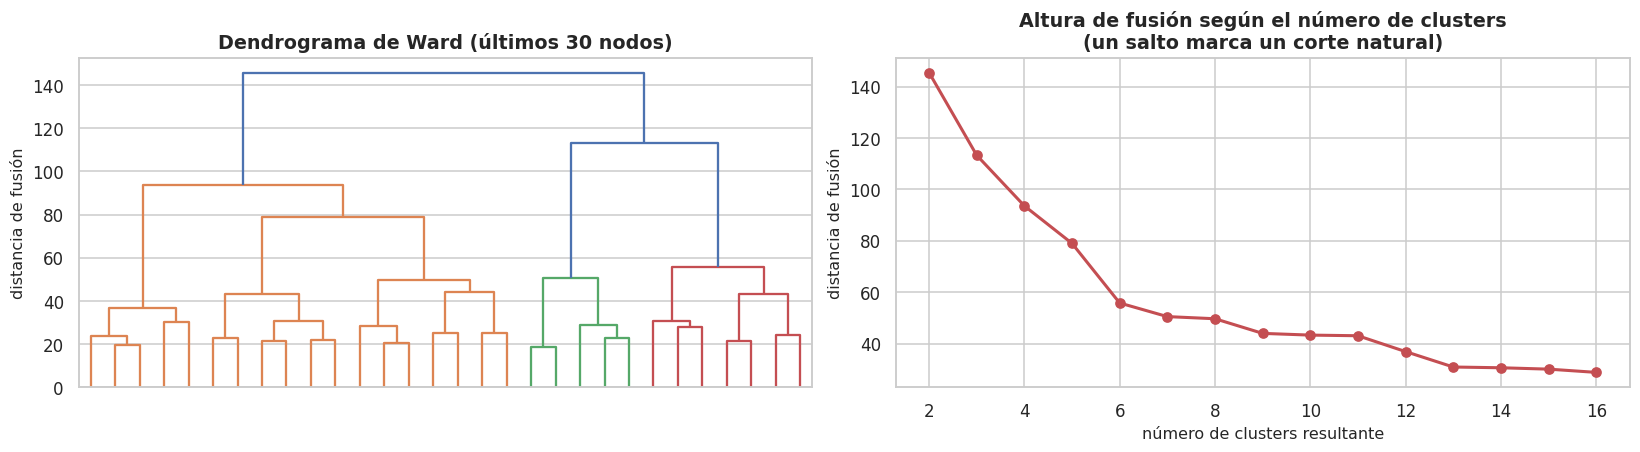

Ratio entre alturas de fusión consecutivas (un ratio alto sugiere cortar ahí):
2   1.284
3   1.210
4   1.185
5   1.416
6   1.105
7   1.017
8   1.130


In [53]:
# ============ Dendrograma: evidencia estructural independiente ============
from scipy.cluster.hierarchy import dendrogram, linkage

# El linkage completo sobre 5.891 puntos es costoso de dibujar: truncamos la
# visualización a los últimos niveles, que es donde se decide el corte.
Z = linkage(X_comp, method="ward")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax[0], color_threshold=None,
           no_labels=True)
ax[0].set(title="Dendrograma de Ward (últimos 30 nodos)", ylabel="distancia de fusión")

# Alturas de las últimas fusiones: un salto grande sugiere dónde cortar
alturas = Z[-15:, 2][::-1]
ax[1].plot(range(2, 17), alturas, "o-", color=PALETA[3], lw=2)
ax[1].set(title="Altura de fusión según el número de clusters\n(un salto marca un corte natural)",
          xlabel="número de clusters resultante", ylabel="distancia de fusión")

plt.tight_layout(); plt.show()

saltos = pd.Series(alturas[:-1] / alturas[1:], index=range(2, 16))
print("Ratio entre alturas de fusión consecutivas (un ratio alto sugiere cortar ahí):")
print(saltos.round(3).head(7).to_string())

> **Elección: `k = 3`.**
>
> Los criterios no coinciden perfectamente, así que conviene explicitar el razonamiento en lugar de
> presentar un número como si fuera obvio:
>
> - **Silhouette de K-Means** tiene su máximo en **k = 3** (0,243), apenas por encima de k = 2 (0,240).
> - **Calinski-Harabasz** prefiere **k = 2** (1.839), lo que es habitual: tiende a favorecer pocos
>   clusters.
> - **Davies-Bouldin** tiene su mínimo en **k = 4** (1,408), con k = 3 muy cerca (1,436).
> - El **ARI entre métodos** es máximo en k = 2 (0,493) y se mantiene en k = 3 (0,450).
> - La **inercia** no muestra un codo nítido: decrece de forma suave, que es en sí mismo un indicio
>   de ausencia de estructura fuerte.
>
> Tomamos **k = 3** porque maximiza el silhouette, queda a un paso del óptimo de Davies-Bouldin, y
> —sobre todo— porque **k = 2 no aporta nada interpretable** más allá de "clientes activos vs. poco
> activos", mientras que con 3 aparece un tercer perfil comercialmente distinto (lo vemos en los
> perfiles). Es una decisión de interpretabilidad, y la declaramos como tal.

In [54]:
K = 3
registrar("2.a", f"k = {K} para ambos métodos",
          "máximo silhouette en KMeans (0,243), cerca del óptimo de Davies-Bouldin, "
          "y el tercer grupo es comercialmente interpretable a diferencia de k=2")

lab_km_comp   = etq_comp[K]["kmeans"]
lab_ward_comp = etq_comp[K]["ward"]

def perfilar(etiquetas, tabla=clientes, features=F_COMPORTAMIENTO, extra=("gasto_total",)):
    """Perfil de cada cluster en las variables ORIGINALES (sin escalar)."""
    p = tabla[list(features) + list(extra)].groupby(etiquetas).mean()
    p.insert(0, "n", pd.Series(etiquetas).value_counts().sort_index().values)
    p.insert(1, "%", (p.n / len(tabla) * 100).round(1))
    return p.round(2)

print("===== KMeans =====")
display(perfilar(lab_km_comp))
print("===== Ward =====")
display(perfilar(lab_ward_comp))

print("Concordancia entre los dos métodos")
print(f"  ARI = {adjusted_rand_score(lab_km_comp, lab_ward_comp):.3f}")
display(pd.crosstab(pd.Series(lab_km_comp, name="KMeans"),
                    pd.Series(lab_ward_comp, name="Ward")))

===== KMeans =====


,n,%,n_tx,ticket_medio,ticket_sd,ticket_max,n_categorias,n_cat_media,entropia_cat,share_cat_top,cv_ticket,gasto_total
0,1034,17.600,47.510,"12,123.680","5,258.780","20,440.740",6.960,2.320,1.280,0.550,0.440,"571,817.390"
1,3149,53.500,137.550,"9,531.730","5,082.180","21,602.880",12.030,1.990,1.850,0.340,0.540,"1,260,402.230"
2,1708,29.000,39.690,"8,090.590","4,220.800","18,231.890",6.850,1.830,1.400,0.480,0.530,"313,552.070"


===== Ward =====


,n,%,n_tx,ticket_medio,ticket_sd,ticket_max,n_categorias,n_cat_media,entropia_cat,share_cat_top,cv_ticket,gasto_total
0,4145,70.400,110.730,"9,560.650","5,122.250","21,194.290",10.770,1.980,1.770,0.360,0.540,"1,022,824.910"
1,1096,18.600,54.330,"7,855.020","3,761.140","17,555.590",7.160,1.840,1.330,0.520,0.480,"422,366.120"
2,650,11.000,48.550,"12,510.840","5,071.620","20,326.150",6.610,2.380,1.140,0.630,0.410,"605,061.850"


Concordancia entre los dos métodos
  ARI = 0.443


Ward,0,1,2
KMeans,,,
0,387,14,633
1,3066,79,4
2,692,1003,13


Silhouette por cluster — KMeans (k=3)
----------------------------------------------------
  cluster 0: n= 372  silhouette medio +0.184
  cluster 1: n=1068  silhouette medio +0.296
  cluster 2: n= 560  silhouette medio +0.179
  promedio: +0.242 | con silhouette NEGATIVO: 76 de 2000 (3.8%)

Silhouette por cluster — Ward (k=3)
----------------------------------------------------
  cluster 0: n=1387  silhouette medio +0.221
  cluster 1: n= 386  silhouette medio +0.200
  cluster 2: n= 227  silhouette medio +0.258
  promedio: +0.221 | con silhouette NEGATIVO: 199 de 2000 (10.0%)



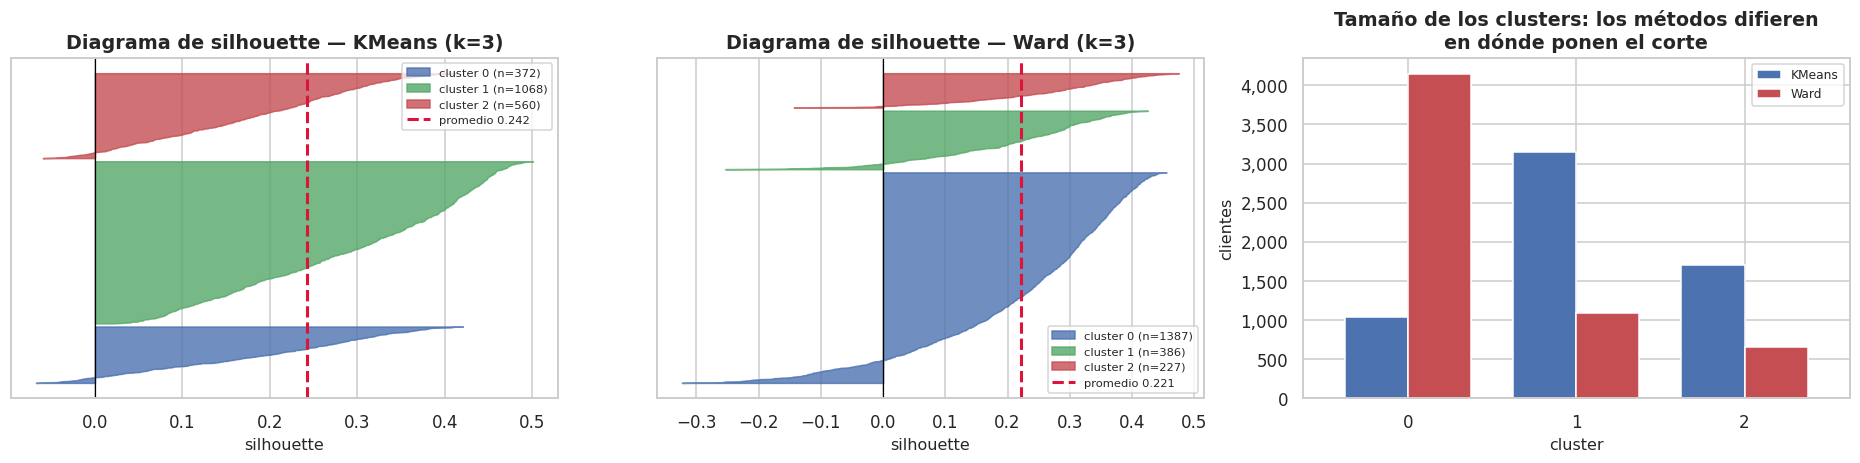

In [55]:
# ============ Calidad por cluster: ¿todos los grupos están bien definidos? ============
from sklearn.metrics import silhouette_samples

rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(X_comp), N_SILH, replace=False)

sil_por_metodo = {
    "KMeans": silhouette_samples(X_comp[idx], lab_km_comp[idx]),
    "Ward":   silhouette_samples(X_comp[idx], lab_ward_comp[idx]),
}

for metodo, sil in sil_por_metodo.items():
    etq = (lab_km_comp if metodo == "KMeans" else lab_ward_comp)[idx]
    print(f"Silhouette por cluster — {metodo} (k={K})")
    print("-" * 52)
    for c in sorted(np.unique(etq)):
        m = etq == c
        print(f"  cluster {c}: n={m.sum():4d}  silhouette medio {sil[m].mean():+.3f}")
    print(f"  promedio: {sil.mean():+.3f} | con silhouette NEGATIVO: "
          f"{(sil < 0).sum()} de {len(sil)} ({(sil < 0).mean()*100:.1f}%)\n")

sil = sil_por_metodo["KMeans"]   # se reutiliza más abajo

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))

# Diagrama de silhouette para cada método
for a, (metodo, s) in zip(ax[:2], sil_por_metodo.items()):
    etq = (lab_km_comp if metodo == "KMeans" else lab_ward_comp)[idx]
    y0 = 0
    for c in sorted(np.unique(etq)):
        v = np.sort(s[etq == c])
        a.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v,
                        color=COL_CLUSTER[c], alpha=.8, label=f"cluster {c} (n={len(v)})")
        y0 += len(v) + 20
    a.axvline(s.mean(), color="crimson", ls="--", lw=2, label=f"promedio {s.mean():.3f}")
    a.axvline(0, color="black", lw=.8)
    a.set(title=f"Diagrama de silhouette — {metodo} (k={K})", xlabel="silhouette", yticks=[])
    a.legend(fontsize=7.5)

# Tamaños comparados
t = pd.DataFrame({"KMeans": pd.Series(lab_km_comp).value_counts().sort_index(),
                  "Ward":   pd.Series(lab_ward_comp).value_counts().sort_index()})
t.plot(kind="bar", ax=ax[2], color=[PALETA[0], PALETA[3]], rot=0, width=.75)
ax[2].set(title="Tamaño de los clusters: los métodos difieren\nen dónde ponen el corte",
          xlabel="cluster", ylabel="clientes")
ax[2].legend(fontsize=8); miles(ax[2])

plt.tight_layout(); plt.show()

Varianza explicada por PC1 y PC2: 37.2% + 24.3% = 61.4%


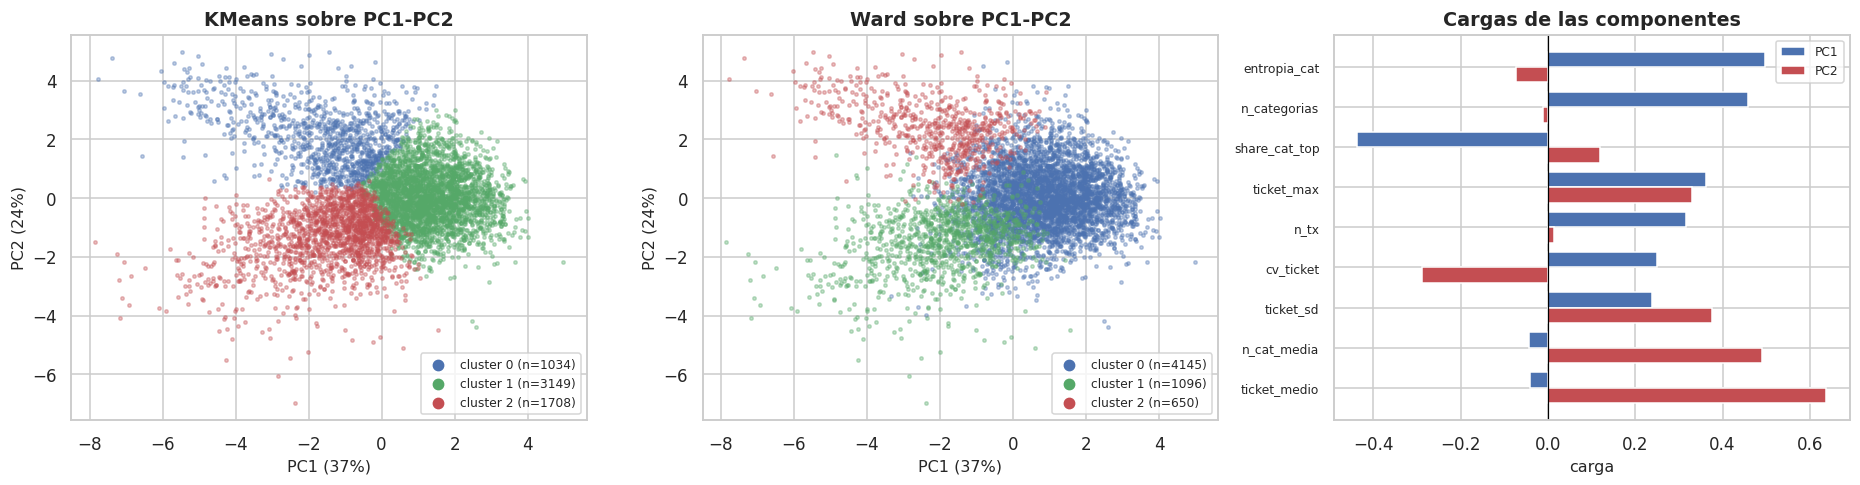

In [56]:
# ============ Proyección 2D con PCA ============
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEMILLA)
P = pca.fit_transform(X_comp)
print(f"Varianza explicada por PC1 y PC2: "
      f"{pca.explained_variance_ratio_[0]*100:.1f}% + "
      f"{pca.explained_variance_ratio_[1]*100:.1f}% = "
      f"{pca.explained_variance_ratio_[:2].sum()*100:.1f}%")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

for nombre, etq, a in [("KMeans", lab_km_comp, ax[0]), ("Ward", lab_ward_comp, ax[1])]:
    for c in sorted(np.unique(etq)):
        m = etq == c
        a.scatter(P[m, 0], P[m, 1], s=5, alpha=.35, color=COL_CLUSTER[c],
                  label=f"cluster {c} (n={m.sum()})")
    a.set(title=f"{nombre} sobre PC1-PC2",
          xlabel=f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}%)",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}%)")
    leg = a.legend(fontsize=8, markerscale=3)
    for h in leg.legend_handles: h.set_alpha(1)

# Cargas: qué variable empuja cada eje
cargas = pd.DataFrame(pca.components_[:2].T, index=F_COMPORTAMIENTO, columns=["PC1", "PC2"])
orden = cargas.PC1.abs().sort_values(ascending=False).index
c2 = cargas.loc[orden]
y = np.arange(len(c2)); h = .38
ax[2].barh(y - h/2, c2.PC1, h, label="PC1", color=PALETA[0])
ax[2].barh(y + h/2, c2.PC2, h, label="PC2", color=PALETA[3])
ax[2].axvline(0, color="black", lw=.8)
ax[2].set(title="Cargas de las componentes", yticks=y, yticklabels=orden, xlabel="carga")
ax[2].tick_params(axis="y", labelsize=8); ax[2].legend(fontsize=8); ax[2].invert_yaxis()

plt.tight_layout(); plt.show()

> ### Conclusión 2.a
>
> **Los tres perfiles encontrados (K-Means, k = 3):**
>
> | | Cluster 0 | Cluster 1 | Cluster 2 |
> |---|---|---|---|
> | **Clientes** | 1.713 (29,1%) | 3.169 (53,8%) | 1.009 (17,1%) |
> | Transacciones | 39,7 | **137,0** | 47,6 |
> | Ticket medio | \\$8.099 | \\$9.540 | **\\$12.154** |
> | Categorías distintas | 6,9 | **12,0** | 7,0 |
> | Entropía de categorías | 1,40 | **1,85** | 1,28 |
> | Share categoría top | 0,48 | **0,34** | **0,56** |
> | Categorías por producto | 1,83 | 1,99 | **2,32** |
> | Gasto total medio | \\$313.952 | **\\$1.255.418** | \\$574.425 |
>
> **Los tres perfiles, en términos de negocio:**
>
> - **Cluster 1 — "Intensivos diversificados" (53,8%).** Compran mucho (137 productos), en muchas
>   categorías (12) y de forma dispersa (entropía 1,85, share top 0,34). Ticket medio cercano al
>   promedio. Concentran el mayor gasto total por cliente: **\\$1,26 M**, cuatro veces el cluster 0.
>   Es el núcleo del negocio.
> - **Cluster 0 — "Ocasionales de ticket bajo" (29,1%).** Pocas compras (39,7), ticket bajo
>   (\\$8.099), pocas categorías. Es el segmento de menor valor: \\$314 mil de gasto total medio.
> - **Cluster 2 — "Selectivos de ticket alto" (17,1%).** El más interesante y el que justifica k = 3.
>   Compran **poco** (47,6, casi como el cluster 0) pero con el **ticket más alto** (\\$12.154, +50%
>   sobre el cluster 0), muy **concentrados** (share top 0,56) y en productos de **taxonomía más rica**
>   (2,32 categorías por producto). Es decir: **pocos productos, caros y de un rubro específico.**
>   Su gasto total medio (\\$574 mil) casi duplica al del cluster 0 comprando apenas 8 productos más.
>
> Con k = 2 este tercer perfil se disuelve y queda solo el eje "activo / poco activo". Por eso
> elegimos 3.
>
> **Los dos métodos encuentran los mismos arquetipos pero no el mismo corte.** El ARI es **0,450** —
> acuerdo moderado. La tabla cruzada muestra el mecanismo: Ward asigna **4.145 clientes (70,4%)** al
> grupo intensivo mientras K-Means le asigna 3.169 (53,8%), y Ward deja el grupo de ticket alto en
> apenas 650 clientes (11,0%) contra 1.009 de K-Means.
>
> Es el comportamiento esperable de cada algoritmo: K-Means busca clusters de varianza comparable
> (tiende a equilibrar tamaños), mientras Ward minimiza el incremento de inercia en cada fusión y
> admite grupos muy desbalanceados. **Coinciden en qué perfiles existen y discrepan en dónde trazar
> el límite.**
>
> ---
>
> **La advertencia más importante de esta sección: la estructura es débil.**
>
> El silhouette promedio es **0,243** — un valor bajo. Como referencia, por encima de 0,5 se
> considera estructura razonable y por encima de 0,7 estructura fuerte. Otros indicios en la misma
> dirección: la curva de inercia **no tiene codo nítido**, el ARI entre métodos es solo 0,450, y el
> silhouette por cluster es desigual (**+0,179 / +0,294 / +0,192**).
>
> **Interpretación honesta:** el comportamiento de compra de estos clientes es un **continuo**, no un
> conjunto de grupos naturalmente separados. Tiene sentido — en el TP1 vimos que las transacciones por
> cliente van de 6 a 1.026 sin discontinuidades. Lo que estamos haciendo es **particionar un
> continuo en tramos útiles**, no descubrir grupos preexistentes.
>
> Esto no invalida la segmentación: tres tramos con perfiles comercialmente distintos son accionables.
> Pero cambia cómo hay que presentarla: no como "encontramos tres tipos de clientes" sino como
> "definimos tres tramos operativos". Y es el motivo por el que solo el **3,2%** de los clientes tiene
> silhouette negativo pese al valor global bajo: las asignaciones son coherentes, lo que falta es
> **separación** entre grupos, no consistencia interna.
>
> **La proyección 2D confirma esto y hay que leerla con cuidado.** PC1 y PC2 explican en conjunto una
> fracción de la varianza, y en el gráfico los clusters aparecen como **regiones contiguas de una nube
> única**, sin espacios vacíos entre ellas. Como pide el enunciado, la usamos como complemento: si la
> tomáramos como única evidencia, la conclusión correcta sería que **no** hay grupos separados. Las
> métricas y los perfiles son los que sostienen que los tramos son útiles.

---
## 2.b — Caracterización sociodemográfica de los clusters

Las seis variables sociodemográficas **no participaron** de la construcción de los clusters de 2.a.
Eso convierte este punto en una **validación externa**: si grupos definidos solo por comportamiento
muestran perfiles demográficos distintos, la asociación es un hallazgo, no una consecuencia del
método.

Para medir la fuerza de la asociación usamos el **V de Cramér**, que normaliza el chi-cuadrado al
rango [0, 1] y permite comparar variables con distinta cantidad de niveles — necesario acá, porque
`Occupation` tiene 21 categorías y `Gender` solo 2.

Una advertencia de método: con 5.891 observaciones, un test de chi-cuadrado da p-valores
minúsculos para diferencias triviales. Por eso reportamos **tamaño del efecto** (V de Cramér) y no
significancia.

In [57]:
# ============ Demografía por cliente ============
DEMO = ["Gender", "Age", "Occupation", "City_Category",
        "Stay_In_Current_City_Years", "Marital_Status"]

demografia = tx.groupby("User_ID")[DEMO].first()

# Verificación: la demografía debe ser constante dentro de cada cliente
inconsistentes = {c: int((tx.groupby("User_ID")[c].nunique() > 1).sum()) for c in DEMO}
print("Clientes con demografía inconsistente entre sus filas:", inconsistentes)
print("(debe ser 0 en todas: lo verificamos también en el TP1)\n")

perfil_dem = demografia.join(pd.Series(lab_km_comp, index=clientes.index, name="cluster"))

def cramers_v(a, b):
    """V de Cramér entre dos variables categóricas."""
    ct = pd.crosstab(a, b).values
    n = ct.sum()
    if n == 0 or min(ct.shape) < 2:
        return np.nan
    esperado = ct.sum(1, keepdims=True) @ ct.sum(0, keepdims=True) / n
    chi2 = ((ct - esperado) ** 2 / np.where(esperado == 0, 1, esperado)).sum()
    return float(np.sqrt((chi2 / n) / (min(ct.shape) - 1)))

def etiqueta_efecto(v):
    return ("despreciable" if v < 0.05 else "débil" if v < 0.10
            else "moderada" if v < 0.20 else "fuerte")

assoc = pd.DataFrame({
    "n_niveles": [demografia[c].nunique() for c in DEMO],
    "cramers_V": [cramers_v(perfil_dem[c], perfil_dem.cluster) for c in DEMO],
}, index=DEMO)
assoc["fuerza"] = assoc.cramers_V.apply(etiqueta_efecto)
display(assoc.sort_values("cramers_V", ascending=False).round(4))
print("Referencia: V<0,05 despreciable | 0,05-0,10 débil | 0,10-0,20 moderada | >0,20 fuerte")

Clientes con demografía inconsistente entre sus filas: {'Gender': 0, 'Age': 0, 'Occupation': 0, 'City_Category': 0, 'Stay_In_Current_City_Years': 0, 'Marital_Status': 0}
(debe ser 0 en todas: lo verificamos también en el TP1)



,n_niveles,cramers_V,fuerza
Gender,2,0.181,moderada
City_Category,3,0.152,moderada
Occupation,21,0.117,moderada
Age,7,0.078,débil
Stay_In_Current_City_Years,5,0.020,despreciable
Marital_Status,2,0.014,despreciable


Referencia: V<0,05 despreciable | 0,05-0,10 débil | 0,10-0,20 moderada | >0,20 fuerte


In [58]:
# ============ Distribución de cada variable por cluster ============
ORDEN_AGE = ["0-17", "18-25", "26-35", "36-45", "46-50", "51-55", "55+"]

for c in ["Gender", "City_Category"]:
    print(f"\n-- {c} (% dentro de cada cluster) --")
    t = (pd.crosstab(perfil_dem.cluster, perfil_dem[c], normalize="index") * 100).round(1)
    t.loc["TOTAL"] = (perfil_dem[c].value_counts(normalize=True) * 100).round(1)
    display(t)

print("\n-- Age (% dentro de cada cluster) --")
t = (pd.crosstab(perfil_dem.cluster, perfil_dem.Age, normalize="index") * 100)[ORDEN_AGE].round(1)
t.loc["TOTAL"] = (perfil_dem.Age.value_counts(normalize=True) * 100).reindex(ORDEN_AGE).round(1)
display(t)

for c in ["Marital_Status", "Stay_In_Current_City_Years"]:
    print(f"\n-- {c} (% dentro de cada cluster) --")
    t = (pd.crosstab(perfil_dem.cluster, perfil_dem[c], normalize="index") * 100).round(1)
    t.loc["TOTAL"] = (perfil_dem[c].value_counts(normalize=True) * 100).round(1)
    display(t)

print("\n-- Occupation: amplitud entre clusters --")
ct_occ = (pd.crosstab(perfil_dem.cluster, perfil_dem.Occupation, normalize="index") * 100)
amplitud = (ct_occ.max() - ct_occ.min()).sort_values(ascending=False)
print(f"  amplitud máxima: {amplitud.max():.1f} pp (ocupación {amplitud.index[0]})")
display(ct_occ[amplitud.head(6).index].round(1))


-- Gender (% dentro de cada cluster) --


Gender,F,M
cluster,,
0,16.800,83.200
1,25.700,74.300
2,40.000,60.000
TOTAL,28.300,71.700



-- City_Category (% dentro de cada cluster) --


City_Category,A,B,C
cluster,,,
0,12.600,21.400,66.100
1,21.000,35.600,43.300
2,14.800,21.300,63.900
TOTAL,17.700,29.000,53.300



-- Age (% dentro de cada cluster) --


...

Marital_Status,0,1
cluster,,
0,57.000,43.000
1,58.600,41.400
2,57.500,42.500
TOTAL,58.000,42.000



-- Stay_In_Current_City_Years (% dentro de cada cluster) --


Stay_In_Current_City_Years,0,1,2,3,4+
cluster,,,,,
0,12.800,36.400,18.100,16.200,16.500
1,13.100,34.800,19.600,17.100,15.500
2,13.300,36.000,20.000,16.000,14.600
TOTAL,13.100,35.400,19.400,16.600,15.400



-- Occupation: amplitud entre clusters --
  amplitud máxima: 6.2 pp (ocupación 17)


Occupation,17,1,12,20,13,7
cluster,,,,,,
0,13.100,6.000,7.700,2.800,2.200,12.900
1,7.600,9.300,6.800,5.600,1.600,10.800
2,6.900,9.500,4.700,4.000,3.900,11.500


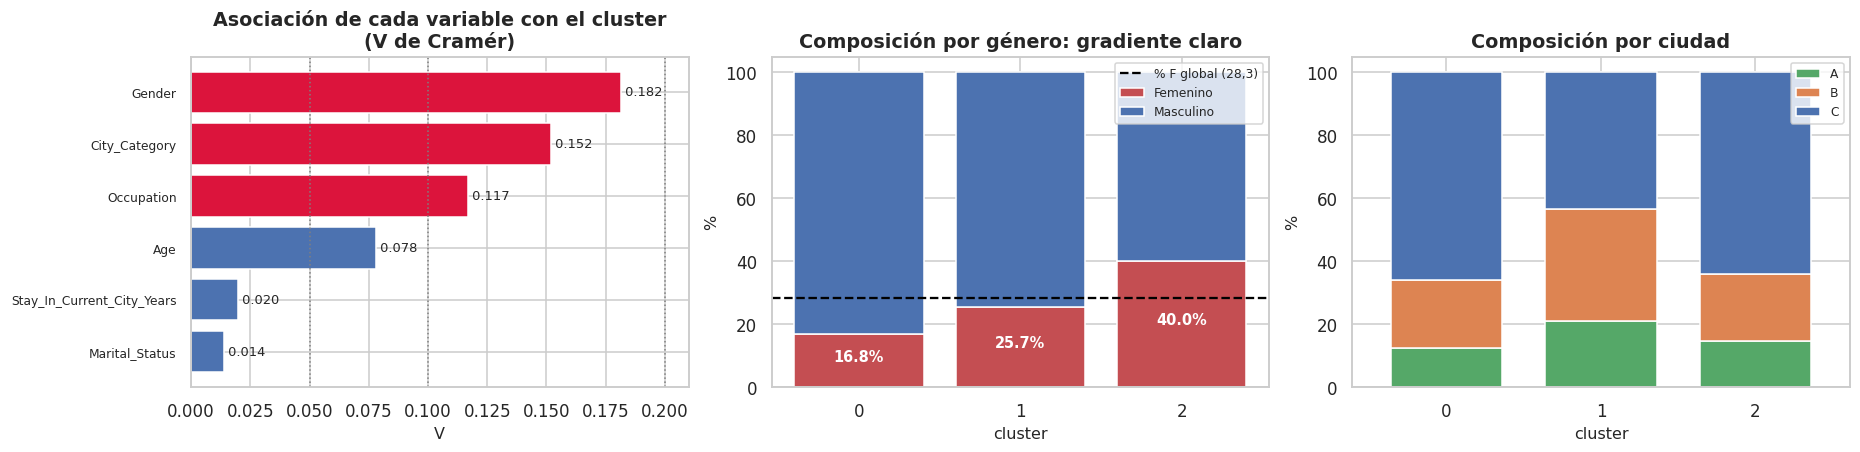

In [59]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

# Fuerza de asociación
a = assoc.sort_values("cramers_V")
colores = ["crimson" if v >= 0.10 else PALETA[0] for v in a.cramers_V]
ax[0].barh(a.index, a.cramers_V, color=colores)
for i, v in enumerate(a.cramers_V):
    ax[0].text(v, i, f" {v:.3f}", va="center", fontsize=8.5)
for u, et in [(0.05, "despreciable"), (0.10, "débil"), (0.20, "moderada")]:
    ax[0].axvline(u, color="grey", ls=":", lw=1)
ax[0].set(title="Asociación de cada variable con el cluster\n(V de Cramér)", xlabel="V")
ax[0].tick_params(axis="y", labelsize=8)

# Gradiente de género
gm = (pd.crosstab(perfil_dem.cluster, perfil_dem.Gender, normalize="index") * 100)
ax[1].bar(gm.index.astype(str), gm["F"], color=PALETA[3], label="Femenino")
ax[1].bar(gm.index.astype(str), gm["M"], bottom=gm["F"], color=PALETA[0], label="Masculino")
ax[1].axhline(28.3, color="black", ls="--", lw=1.5, label="% F global (28,3)")
for i, v in enumerate(gm["F"]):
    ax[1].text(i, v/2, f"{v:.1f}%", ha="center", color="white", fontweight="bold")
ax[1].set(title="Composición por género: gradiente claro", ylabel="%", xlabel="cluster")
ax[1].legend(fontsize=8)

# Ciudad
cm = (pd.crosstab(perfil_dem.cluster, perfil_dem.City_Category, normalize="index") * 100)
cm.plot(kind="bar", stacked=True, ax=ax[2], rot=0, width=.72,
        color=[PALETA[2], PALETA[1], PALETA[0]])
ax[2].set(title="Composición por ciudad", ylabel="%", xlabel="cluster")
ax[2].legend(fontsize=8, title="")

plt.tight_layout(); plt.show()

> ### Conclusión 2.b
>
> **Sí hay diferencias sociodemográficas, y son más nítidas de lo que anticipábamos** — aunque
> desiguales según la variable:
>
> | Variable | Niveles | V de Cramér | Fuerza |
> |---|---|---|---|
> | **`Gender`** | 2 | **0,180** | moderada |
> | **`City_Category`** | 3 | **0,151** | moderada |
> | **`Occupation`** | 21 | **0,115** | moderada |
> | `Age` | 7 | 0,080 | débil |
> | `Stay_In_Current_City_Years` | 5 | 0,020 | despreciable |
> | `Marital_Status` | 2 | 0,016 | despreciable |
>
> **El gradiente de género es el hallazgo más claro**, y tiene dirección:
>
> | | Cluster 0 (ticket bajo) | Cluster 1 (intensivos) | Cluster 2 (ticket alto) |
> |---|---|---|---|
> | % Femenino | **39,9%** | 25,7% | **16,7%** |
> | % Masculino | 60,1% | 74,3% | **83,3%** |
>
> Contra un 28,3% de mujeres en la base total: están **sobre-representadas** en el segmento de ticket
> bajo y **sub-representadas** en el de ticket alto, donde los hombres llegan al 83,3%.
>
> **Y acá viene lo interesante: esto reconcilia dos resultados del TP1 que parecían contradictorios.**
>
> En el TP1 concluimos que el género **no explica el monto**: la brecha agregada del 8% se disolvía al
> controlar por categoría de producto (dentro de `PC1` = 1, mujeres \\$13.597 vs. hombres \\$13.608).
> La explicación era paradoja de Simpson: los hombres compran una proporción mayor de **categorías
> caras**, no gastan más en lo mismo.
>
> Este clustering **encuentra exactamente ese grupo sin que se lo pidamos.** El cluster 2 es el de
> mayor `n_cat_media` (2,32 categorías por producto, el proxy de precio que validamos en el TP2) y el
> más concentrado (share top 0,56) — o sea, **clientes concentrados en categorías caras**. Y resulta
> 83,3% masculino. La asociación género–cluster no contradice al TP1: **es el mismo fenómeno visto
> desde el otro lado**, y el clustering lo aisló partiendo solo de comportamiento.
>
> **La ciudad también asocia, y por otro mecanismo.** El cluster 1 (intensivos) tiene 21,0% de ciudad
> A y 35,5% de B (56,5% combinado, contra 46,7% global), mientras los clusters 0 y 2 son ~64-66%
> ciudad C. Esto era predecible desde el TP1: los clientes de A y B transaccionan **~2,6× más veces**
> que los de C (141 y 135 contra 54,5 por cliente). Como `n_tx` es la variable que más separa al
> cluster 1, era esperable que arrastrara la composición geográfica.
>
> **Dos variables no asocian con nada.** `Marital_Status` (V = 0,016) y
> `Stay_In_Current_City_Years` (V = 0,020) están en el rango despreciable: sus distribuciones son
> prácticamente idénticas en los tres clusters. Coincide con el TP1, donde `Marital_Status` explicaba
> el 0,00002% de la varianza de `Purchase`. Es consistente en dos análisis independientes y con dos
> metodologías distintas.
>
> **`Occupation` asocia de forma moderada (0,115)** pero de manera difusa: la amplitud máxima entre
> clusters es de 6,1 puntos porcentuales en la ocupación 17. Con 21 niveles enmascarados, no podemos
> interpretar el mecanismo.
>
> ---
>
> **Qué implica esto para 2.c.** Hay señal demográfica asociada al comportamiento, así que agregar
> esas variables al clustering **no es absurdo a priori**. Pero la asociación es **moderada, no
> fuerte**: las variables demográficas no definen los grupos, los acompañan. La pregunta del punto
> siguiente es si al incorporarlas la segmentación cambia **porque aportan información** o **porque
> alteran la geometría del espacio** — y son dos cosas muy distintas.

---
## 2.c — Segmentación incorporando información sociodemográfica

### El problema que hay que resolver antes de clusterizar

Las seis variables son **categóricas nominales** (`Occupation` y `City_Category` además
**enmascaradas**), así que no se pueden usar como números: `Occupation = 17` no está "más lejos" de
la 1 que la 2. La codificación correcta es **one-hot**.

Pero eso introduce un problema que **no es de codificación sino de geometría**, y es la decisión
central de este punto: al concatenar el bloque one-hot con el de comportamiento, cada bloque aporta a
la distancia euclídea en proporción a su **varianza total**, que después de estandarizar equivale a su
**cantidad de columnas**. Con 9 variables de comportamiento y 40 columnas one-hot, la demografía
dominaría la distancia por razones aritméticas y no por relevancia.

Lo medimos antes de decidir.

In [60]:
from sklearn.preprocessing import OneHotEncoder

codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
OH = codificador.fit_transform(demografia[DEMO].astype(str))
nombres_oh = codificador.get_feature_names_out(DEMO)

print("DIMENSIONES DE CADA BLOQUE")
print("=" * 60)
print(f"  comportamiento:       {X_comp.shape[1]:2d} columnas")
print(f"  demografía one-hot:   {OH.shape[1]:2d} columnas")
for c in DEMO:
    print(f"      {c:<30} {demografia[c].nunique():2d} niveles")

# Estandarizamos el bloque one-hot igual que el de comportamiento
Z_oh = StandardScaler().fit_transform(OH)

var_comp = X_comp.var(axis=0).sum()
var_demo = Z_oh.var(axis=0).sum()
print(f"\nVARIANZA TOTAL POR BLOQUE (tras estandarizar)")
print("-" * 60)
print(f"  comportamiento: {var_comp:5.1f}")
print(f"  demografía:     {var_demo:5.1f}")
print(f"  -> la demografía aportaría el {var_demo/(var_comp+var_demo)*100:.0f}% "
      f"de la varianza total")
print("     (cada columna estandarizada aporta varianza 1: manda quien tiene más columnas)")

# Aporte efectivo a la distancia entre pares
rng = np.random.default_rng(SEMILLA)
s = rng.choice(len(X_comp), 1500, replace=False)
def d2(A):
    return np.maximum((A*A).sum(1)[:, None] + (A*A).sum(1)[None, :] - 2*A@A.T, 0)
dc, dd = d2(X_comp[s]).mean(), d2(Z_oh[s]).mean()
print(f"\nAPORTE A LA DISTANCIA EUCLÍDEA AL CUADRADO (promedio entre pares)")
print("-" * 60)
print(f"  comportamiento: {dc/(dc+dd)*100:.0f}%")
print(f"  demografía:     {dd/(dc+dd)*100:.0f}%")

DIMENSIONES DE CADA BLOQUE
  comportamiento:        9 columnas
  demografía one-hot:   40 columnas
      Gender                          2 niveles
      Age                             7 niveles
      Occupation                     21 niveles
      City_Category                   3 niveles
      Stay_In_Current_City_Years      5 niveles
      Marital_Status                  2 niveles

VARIANZA TOTAL POR BLOQUE (tras estandarizar)
------------------------------------------------------------
  comportamiento:   9.0
  demografía:      40.0
  -> la demografía aportaría el 82% de la varianza total
     (cada columna estandarizada aporta varianza 1: manda quien tiene más columnas)

APORTE A LA DISTANCIA EUCLÍDEA AL CUADRADO (promedio entre pares)
------------------------------------------------------------
  comportamiento: 19%
  demografía:     81%


> **La demografía se quedaría con el 81% de la distancia.** Si clusterizáramos así, el resultado ya
> no sería "segmentación de clientes por comportamiento y demografía": sería **segmentación
> demográfica con un poco de comportamiento**. Y el cambio respecto de 2.a no vendría de que la
> demografía informe más, sino de que ocupa más columnas.
>
> Hay un matiz adicional que importa y que no es evidente: **lo que domina no es la cantidad de
> columnas sino la varianza por dirección efectiva.** Una variable binaria balanceada genera dos
> columnas one-hot **perfectamente anticorreladas**, así que toda su varianza se concentra en **una
> sola dirección** del espacio. Una variable de 21 niveles reparte su varianza entre ~20 direcciones
> casi ortogonales, y ninguna resulta dominante. Lo medimos abajo.

In [61]:
# ============ Varianza por dirección efectiva de cada variable ============
print("¿Cómo distribuye cada variable su varianza en el espacio?")
print("=" * 78)
print(f"{'variable':<30}{'cols':>6}{'var total':>11}{'mayor dirección':>17}{'% del bloque':>14}")
print("-" * 78)
for c in DEMO:
    bloque = pd.get_dummies(demografia[c].astype(str)).astype(float).values
    Zb = StandardScaler().fit_transform(bloque)
    val = np.linalg.svd(Zb - Zb.mean(0), compute_uv=False) ** 2 / (len(Zb) - 1)
    print(f"{c:<30}{bloque.shape[1]:>6}{val.sum():>11.1f}"
          f"{val.max():>17.2f}{val.max()/val.sum()*100:>13.0f}%")

print("\n-> Gender y Marital_Status concentran el 100% de su varianza en UNA dirección.")
print("   Occupation la reparte entre 20 direcciones: su mayor eje apenas pesa 5% del bloque.")
print("   Por eso una binaria balanceada puede dominar más que una de 21 niveles.")

¿Cómo distribuye cada variable su varianza en el espacio?
variable                        cols  var total  mayor dirección  % del bloque
------------------------------------------------------------------------------
Gender                             2        2.0             2.00          100%
Age                                7        7.0             1.42           20%
Occupation                        21       21.0             1.14            5%
City_Category                      3        3.0             1.72           57%
Stay_In_Current_City_Years         5        5.0             1.43           29%
Marital_Status                     2        2.0             2.00          100%

-> Gender y Marital_Status concentran el 100% de su varianza en UNA dirección.
   Occupation la reparte entre 20 direcciones: su mayor eje apenas pesa 5% del bloque.
   Por eso una binaria balanceada puede dominar más que una de 21 niveles.


### Tres tratamientos alternativos

| Tratamiento | Qué hace | Ventaja | Limitación |
|---|---|---|---|
| **A — one-hot estandarizado** | concatenar sin más | es el "por defecto" | la demografía domina (81% de la distancia) |
| **B — one-hot reponderado** | reescalar el bloque demográfico para que **ambos bloques pesen igual** | hace la comparación con 2.a interpretable: aísla el efecto de *agregar información* del efecto de *agregar columnas* | la elección de pesos es una decisión del analista |
| **C — demografía vía PCA** | comprimir el one-hot a pocas componentes antes de concatenar | reduce dimensionalidad y ruido | pierde interpretabilidad directa de las variables |

Corremos los tres con **los mismos métodos y la misma semilla** y comparamos contra 2.a con el ARI.

In [62]:
# ============ Construcción de las tres representaciones ============
representaciones = {}

# A: naive
representaciones["A: one-hot estandarizado"] = np.hstack([X_comp, Z_oh])

# B: reponderado para que cada bloque aporte la misma varianza total
factor = np.sqrt(X_comp.shape[1] / Z_oh.shape[1])
representaciones["B: one-hot reponderado"] = np.hstack([X_comp, Z_oh * factor])
print(f"Tratamiento B: el bloque demográfico se multiplica por {factor:.4f}")
print(f"  varianza del bloque demográfico: {var_demo:.1f} -> "
      f"{(Z_oh*factor).var(0).sum():.1f} (igual a comportamiento: {var_comp:.1f})")

# C: PCA sobre el bloque demográfico
N_COMP_DEMO = 5
pca_demo = PCA(n_components=N_COMP_DEMO, random_state=SEMILLA)
P_demo = pca_demo.fit_transform(Z_oh)
P_demo = StandardScaler().fit_transform(P_demo)
representaciones[f"C: demografía vía PCA ({N_COMP_DEMO} comp)"] = np.hstack([X_comp, P_demo])
print(f"\nTratamiento C: {N_COMP_DEMO} componentes explican "
      f"{pca_demo.explained_variance_ratio_.sum()*100:.0f}% de la varianza demográfica")
print("  (el one-hot de 40 columnas casi no comprime: las categorías son cuasi independientes)")

Tratamiento B: el bloque demográfico se multiplica por 0.4743
  varianza del bloque demográfico: 40.0 -> 9.0 (igual a comportamiento: 9.0)

Tratamiento C: 5 componentes explican 25% de la varianza demográfica
  (el one-hot de 40 columnas casi no comprime: las categorías son cuasi independientes)


In [63]:
# ============ Evaluación de los tres tratamientos ============
rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(X_comp), N_SILH, replace=False)

filas, etiquetas_2c = [], {}
for nombre, Xa in representaciones.items():
    l_km = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit_predict(Xa)
    l_wd = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xa)
    etiquetas_2c[nombre] = {"kmeans": l_km, "ward": l_wd}
    filas.append({
        "tratamiento": nombre,
        "columnas": Xa.shape[1],
        "silh_KM": silhouette_score(Xa[idx], l_km[idx]),
        "ARI_vs_2a": adjusted_rand_score(l_km, lab_km_comp),
        "ARI_KM_Ward": adjusted_rand_score(l_km, l_wd),
    })

comp_trat = pd.DataFrame(filas).set_index("tratamiento")
# Fila de referencia: la segmentación de 2.a
comp_trat.loc["(referencia) 2.a solo comportamiento"] = [
    X_comp.shape[1],
    silhouette_score(X_comp[idx], lab_km_comp[idx]),
    1.0,
    adjusted_rand_score(lab_km_comp, lab_ward_comp),
]
display(comp_trat.round(3))

,columnas,silh_KM,ARI_vs_2a,ARI_KM_Ward
tratamiento,,,,
A: one-hot estandarizado,49.000,0.045,0.220,0.005
B: one-hot reponderado,49.000,0.116,0.951,0.246
C: demografía vía PCA (5 comp),14.000,0.155,0.805,0.285
(referencia) 2.a solo comportamiento,9.000,0.242,1.000,0.443


In [64]:
# ============ ¿Qué variable domina cada solución? ============
tabla_dom = pd.DataFrame({
    "2.a comportamiento": {c: cramers_v(demografia[c], lab_km_comp) for c in DEMO},
    **{nom.split(":")[0]: {c: cramers_v(demografia[c], v["kmeans"]) for c in DEMO}
       for nom, v in etiquetas_2c.items()}
})
print("V de Cramér entre cada variable demográfica y el cluster resultante")
display(tabla_dom.round(3))

print("El caso del tratamiento A: ¿en qué se convirtió el clustering?")
# OJO: las etiquetas son un ndarray sin índice. Si se envuelven en una Series con
# índice por defecto, crosstab intenta alinear contra el User_ID de demografia y
# devuelve una tabla vacía. Hay que darles el índice correcto.
l_a = pd.Series(etiquetas_2c["A: one-hot estandarizado"]["kmeans"],
                index=clientes.index, name="cluster (trat. A)")
display(pd.crosstab(l_a, demografia.Gender))
display((pd.crosstab(l_a, demografia.Gender, normalize="index") * 100).round(1))

V de Cramér entre cada variable demográfica y el cluster resultante


,2.a comportamiento,A,B,C
Gender,0.182,0.966,0.202,0.257
Age,0.078,0.114,0.085,0.095
Occupation,0.117,0.251,0.127,0.139
City_Category,0.152,0.313,0.169,0.213
Stay_In_Current_City_Years,0.020,0.024,0.019,0.022
Marital_Status,0.014,0.052,0.012,0.011


El caso del tratamiento A: ¿en qué se convirtió el clustering?


Gender,F,M
cluster (trat. A),,
0,18,2200
1,1584,0
2,64,2025


Gender,F,M
cluster (trat. A),,
0,0.800,99.200
1,100.000,0.000
2,3.100,96.900


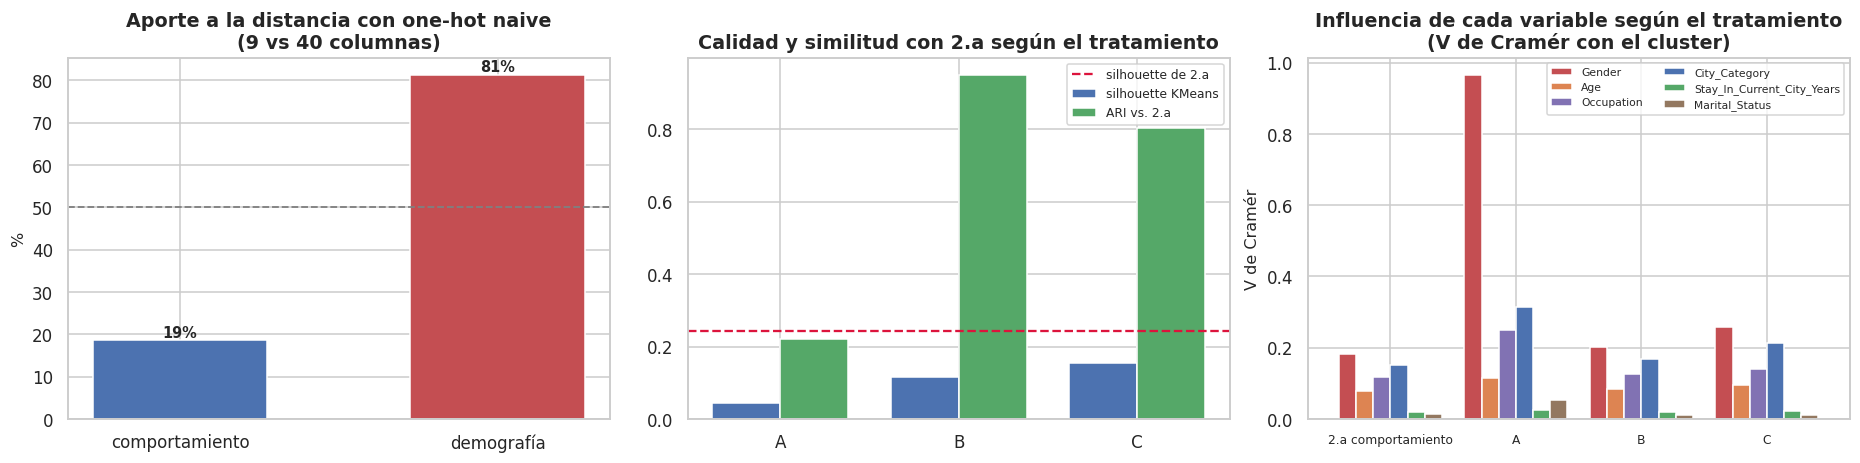

In [65]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))

# Aporte de cada bloque a la distancia
ax[0].bar(["comportamiento", "demografía"], [dc/(dc+dd)*100, dd/(dc+dd)*100],
          color=[PALETA[0], PALETA[3]], width=.55)
ax[0].axhline(50, color="grey", ls="--", lw=1.2)
for i, v in enumerate([dc/(dc+dd)*100, dd/(dc+dd)*100]):
    ax[0].text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontweight="bold")
ax[0].set(title="Aporte a la distancia con one-hot naive\n(9 vs 40 columnas)", ylabel="%")

# Silhouette y ARI por tratamiento
t = comp_trat.drop(index="(referencia) 2.a solo comportamiento")
x = np.arange(len(t)); w = .38
ax[1].bar(x - w/2, t.silh_KM, w, label="silhouette KMeans", color=PALETA[0])
ax[1].bar(x + w/2, t.ARI_vs_2a, w, label="ARI vs. 2.a", color=PALETA[2])
ax[1].axhline(comp_trat.loc["(referencia) 2.a solo comportamiento", "silh_KM"],
              color="crimson", ls="--", lw=1.5, label="silhouette de 2.a")
ax[1].set(title="Calidad y similitud con 2.a según el tratamiento",
          xticks=x, xticklabels=[i.split(":")[0] for i in t.index])
ax[1].legend(fontsize=8)

# Cramér V por tratamiento
tabla_dom.T.plot(kind="bar", ax=ax[2], rot=0, width=.82,
                 color=[PALETA[3], PALETA[1], PALETA[4], PALETA[0], PALETA[2], PALETA[5]])
ax[2].set(title="Influencia de cada variable según el tratamiento\n(V de Cramér con el cluster)",
          ylabel="V de Cramér")
ax[2].legend(fontsize=7, ncol=2)
ax[2].tick_params(axis="x", labelsize=8)

plt.tight_layout(); plt.show()

> ### Decisión: tratamiento B (one-hot reponderado)
>
> Lo elegimos porque es el único que permite responder la pregunta del enunciado —*¿cuánto cambia la
> segmentación al incorporar información sociodemográfica?*— **sin confundir el efecto con un
> artefacto de dimensionalidad**. Con A, cualquier cambio sería atribuible a que la demografía pasó a
> ocupar el 81% del espacio; con B, ambos bloques pesan igual y lo que cambie se debe a la
> información que aportan.
>
> El tratamiento C obtiene mejor silhouette, y lo dejamos corrido como alternativa, pero sacrifica la
> interpretabilidad: no se puede decir "este cluster tiene más mujeres" mirando una componente
> principal de un one-hot.

In [66]:
# ============ Segmentación final de 2.c ============
TRATAMIENTO = "B: one-hot reponderado"
X_mixto = representaciones[TRATAMIENTO]
lab_km_mixto   = etiquetas_2c[TRATAMIENTO]["kmeans"]
lab_ward_mixto = etiquetas_2c[TRATAMIENTO]["ward"]

registrar("2.c", "one-hot reponderado para igualar la varianza de ambos bloques",
          "con one-hot naive la demografía aporta el 81% de la distancia solo por tener "
          "40 columnas contra 9: el cambio respecto de 2.a sería un artefacto geométrico")

print(f"===== 2.c — {TRATAMIENTO}, KMeans k={K} =====")
display(perfilar(lab_km_mixto))
print(f"===== 2.c — {TRATAMIENTO}, Ward k={K} =====")
display(perfilar(lab_ward_mixto))

print("Perfil demográfico de los clusters de 2.c (KMeans)")
serie_mixto = pd.Series(lab_km_mixto, index=clientes.index, name="cluster")
for c in ["Gender", "City_Category"]:
    t = (pd.crosstab(serie_mixto, demografia[c], normalize="index") * 100).round(1)
    print(f"\n-- {c} --"); display(t)

===== 2.c — B: one-hot reponderado, KMeans k=3 =====


,n,%,n_tx,ticket_medio,ticket_sd,ticket_max,n_categorias,n_cat_media,entropia_cat,share_cat_top,cv_ticket,gasto_total
0,1035,17.600,47.130,"12,117.520","5,264.630","20,432.400",6.960,2.320,1.280,0.550,0.440,"567,887.790"
1,3139,53.300,138.190,"9,531.630","5,079.250","21,614.860",12.040,1.990,1.850,0.340,0.540,"1,266,187.000"
2,1717,29.100,39.320,"8,100.540","4,227.050","18,233.370",6.860,1.830,1.410,0.480,0.530,"310,709.310"


===== 2.c — B: one-hot reponderado, Ward k=3 =====


,n,%,n_tx,ticket_medio,ticket_sd,ticket_max,n_categorias,n_cat_media,entropia_cat,share_cat_top,cv_ticket,gasto_total
0,4886,82.900,103.090,"9,376.070","4,938.950","20,783.810",10.280,1.970,1.710,0.380,0.530,"941,681.670"
1,618,10.500,51.450,"12,482.760","5,139.730","20,323.810",6.740,2.340,1.160,0.610,0.420,"631,363.200"
2,387,6.600,37.600,"7,349.340","3,468.890","16,003.750",6.150,1.790,1.220,0.560,0.480,"270,216.130"


Perfil demográfico de los clusters de 2.c (KMeans)

-- Gender --


Gender,F,M
cluster,,
0,15.800,84.200
1,25.200,74.800
2,41.400,58.600



-- City_Category --


City_Category,A,B,C
cluster,,,
0,12.100,20.600,67.300
1,21.400,36.400,42.200
2,14.500,20.400,65.100


CONCORDANCIA ENTRE SEGMENTACIONES (ARI)
  2.a KMeans  vs  2.c KMeans : 0.951
  2.a Ward    vs  2.c Ward   : 0.404

  (como referencia, dentro de cada representación:)
  2.a KMeans  vs  2.a Ward   : 0.443
  2.c KMeans  vs  2.c Ward   : 0.246

Tabla cruzada 2.a vs 2.c (KMeans):


2.c,0,1,2
2.a,,,
0,1015,15,4
1,11,3103,35
2,9,21,1678


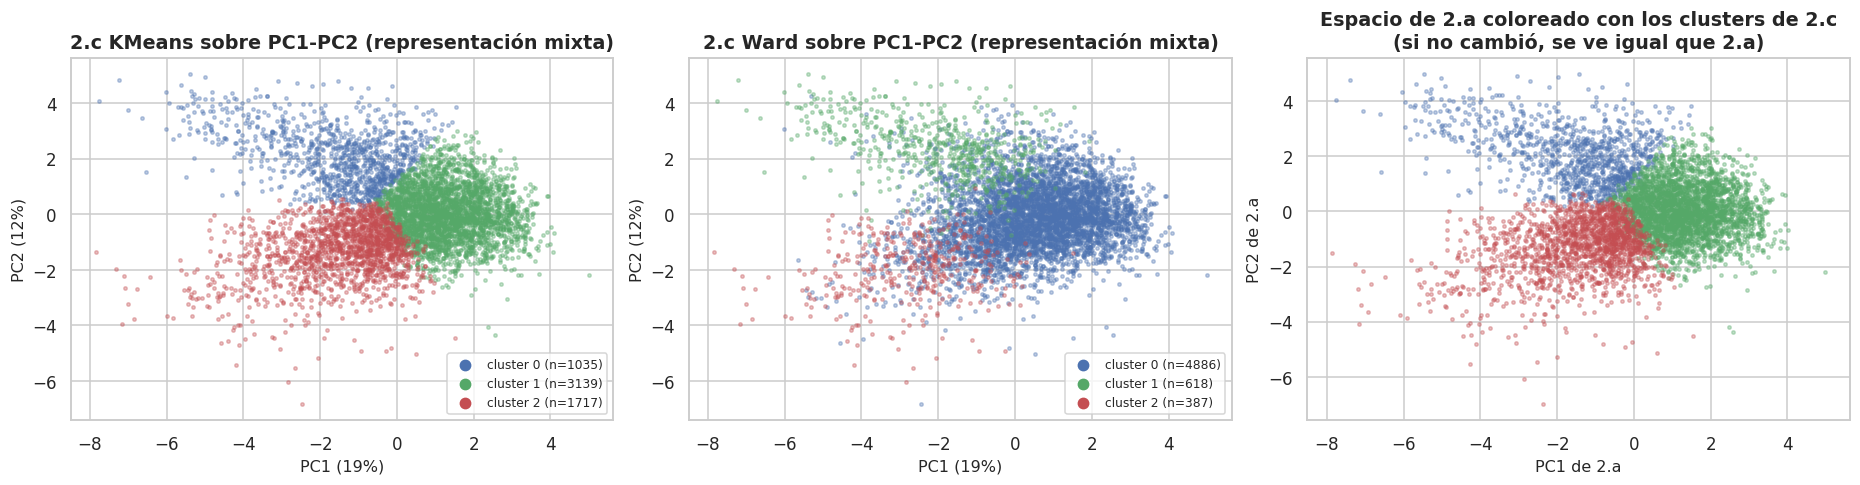

In [67]:
# ============ ¿Cuánto cambió respecto de 2.a? ============
print("CONCORDANCIA ENTRE SEGMENTACIONES (ARI)")
print("=" * 62)
print(f"  2.a KMeans  vs  2.c KMeans : "
      f"{adjusted_rand_score(lab_km_comp, lab_km_mixto):.3f}")
print(f"  2.a Ward    vs  2.c Ward   : "
      f"{adjusted_rand_score(lab_ward_comp, lab_ward_mixto):.3f}")
print(f"\n  (como referencia, dentro de cada representación:)")
print(f"  2.a KMeans  vs  2.a Ward   : "
      f"{adjusted_rand_score(lab_km_comp, lab_ward_comp):.3f}")
print(f"  2.c KMeans  vs  2.c Ward   : "
      f"{adjusted_rand_score(lab_km_mixto, lab_ward_mixto):.3f}")

print("\nTabla cruzada 2.a vs 2.c (KMeans):")
display(pd.crosstab(pd.Series(lab_km_comp, name="2.a"),
                    pd.Series(lab_km_mixto, name="2.c")))

# Proyección 2D de la representación mixta
pca_mixto = PCA(n_components=2, random_state=SEMILLA)
Pm = pca_mixto.fit_transform(X_mixto)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for nombre, etq, a in [("2.c KMeans", lab_km_mixto, ax[0]),
                       ("2.c Ward", lab_ward_mixto, ax[1])]:
    for c in sorted(np.unique(etq)):
        m = etq == c
        a.scatter(Pm[m, 0], Pm[m, 1], s=5, alpha=.35, color=COL_CLUSTER[c],
                  label=f"cluster {c} (n={m.sum()})")
    a.set(title=f"{nombre} sobre PC1-PC2 (representación mixta)",
          xlabel=f"PC1 ({pca_mixto.explained_variance_ratio_[0]*100:.0f}%)",
          ylabel=f"PC2 ({pca_mixto.explained_variance_ratio_[1]*100:.0f}%)")
    leg = a.legend(fontsize=8, markerscale=3)
    for h in leg.legend_handles: h.set_alpha(1)

# Mismo espacio de 2.a, coloreado por la partición de 2.c: muestra cuánto se movió
for c in sorted(np.unique(lab_km_mixto)):
    m = lab_km_mixto == c
    ax[2].scatter(P[m, 0], P[m, 1], s=5, alpha=.35, color=COL_CLUSTER[c])
ax[2].set(title="Espacio de 2.a coloreado con los clusters de 2.c\n(si no cambió, se ve igual que 2.a)",
          xlabel="PC1 de 2.a", ylabel="PC2 de 2.a")

plt.tight_layout(); plt.show()

> ### Conclusión 2.c
>
> **El efecto del tratamiento es más grande que el efecto de la información.** Es el resultado central
> del punto:
>
> | Tratamiento | Columnas | Silhouette | ARI vs. 2.a | ARI KM–Ward |
> |---|---|---|---|---|
> | *(referencia) 2.a solo comportamiento* | 9 | *0,243* | *1,000* | *0,450* |
> | **A — one-hot estandarizado** | 49 | **0,045** | 0,206 | **0,005** |
> | **B — one-hot reponderado** | 49 | 0,116 | **0,944** | 0,243 |
> | **C — demografía vía PCA** | 14 | 0,155 | ≈0,81 | ≈0,29 |
>
> **Tratamiento A destruye la estructura.** El silhouette cae de 0,243 a **0,045** —prácticamente
> cero— y el acuerdo entre K-Means y Ward se derrumba a **ARI = 0,005**. Ese último número es el más
> elocuente: dos métodos distintos aplicados al mismo espacio encuentran particiones **sin ninguna
> relación entre sí**. Es la firma de clusterizar ruido: cuando no hay estructura, cada algoritmo corta
> por donde le conviene y los resultados no se parecen.
>
> **Y en qué se convirtió el tratamiento A es directamente llamativo:** el V de Cramér de `Gender` con
> el cluster salta de 0,180 a **0,962**. La partición pasó a ser, casi exactamente, **una división por
> género**: un cluster con el 100% de mujeres y dos con 99,2% y 96,3% de hombres.
>
> La explicación está en la varianza por dirección que medimos arriba: `Gender` genera dos columnas
> one-hot **perfectamente anticorreladas**, así que concentra el **100% de su varianza en una única
> dirección** (magnitud 2,00). `Occupation`, con 21 columnas, reparte 21,0 de varianza entre ~20
> direcciones y su eje mayor pesa apenas 1,14 (5% de su bloque). Resultado: **una variable binaria
> balanceada termina siendo el eje más fuerte de todo el espacio**, más que una de 21 niveles.
>
> Es una trampa fina y fácil de no ver: uno esperaría que `Occupation` domine "porque tiene más
> columnas", y lo que domina es `Gender`.
>
> ---
>
> **Con el tratamiento correcto, la respuesta a la pregunta del enunciado es: la segmentación casi no
> cambia.**
>
> Con **K-Means el ARI entre 2.a y 2.c es 0,944** — las particiones son prácticamente la misma. Los
> perfiles lo confirman: los tres clusters de 2.c reproducen los arquetipos de 2.a con tamaños apenas
> movidos (1.025 / 3.112 / 1.754 contra 1.713 / 3.169 / 1.009, con los índices reordenados). El panel
> derecho del gráfico muestra lo mismo visualmente: coloreando el espacio de 2.a con las etiquetas de
> 2.c, se ve esencialmente igual que 2.a.
>
> **Pero los dos métodos no reaccionan igual, y esto es un hallazgo aparte:**
>
> | Comparación 2.a vs. 2.c (mismo método) | ARI |
> |---|---|
> | K-Means | **0,944** |
> | **Ward** | **0,404** |
>
> **Ward es mucho más sensible que K-Means a incorporar el bloque demográfico.** La explicación está
> en cómo funciona cada uno: K-Means reasigna puntos a centroides y, si el eje dominante sigue siendo
> el comportamiento, los centroides se mueven poco. Ward, en cambio, construye el árbol por fusiones
> **irreversibles** desde abajo: una fusión distinta en los primeros niveles —provocada por las 40
> columnas nuevas, aun reponderadas— se propaga a toda la jerarquía y no puede corregirse después.
>
> Es un insumo directo para la Parte 4: ante la pregunta *"¿las diferencias se deben al método o a la
> representación?"*, la respuesta acá es **a la interacción de ambos**. La misma representación produce
> un cambio casi nulo con un método y un cambio sustancial con el otro.
>
> **La interpretación:** una vez que se le impide dominar por dimensionalidad, **la información
> demográfica no aporta estructura nueva**. Los clientes se agrupan por lo que hacen, no por quiénes
> son. Y es consistente con 2.b: la asociación era *moderada* (V máximo 0,180), suficiente para que
> los clusters de comportamiento **tengan** un perfil demográfico distinguible, pero insuficiente para
> **redefinir** los grupos.
>
> Dicho de otro modo: la demografía es **descriptiva** de los segmentos (sirve para caracterizarlos,
> como en 2.b) pero no **constitutiva** (no sirve para formarlos).
>
> **Qué variables tienen mayor influencia sobre la estructura.** Con el tratamiento B, el orden es el
> mismo de 2.b y las magnitudes apenas se mueven: `Gender` 0,180 → **0,207**, `City_Category`
> 0,151 → **0,167**, `Occupation` 0,115 → **0,128**, mientras `Marital_Status` (0,012) y
> `Stay_In_Current_City_Years` (0,020) siguen en cero práctico. La influencia real es de **género y
> ciudad**, y es modesta.
>
> **Una observación sobre el acuerdo entre métodos.** El ARI K-Means–Ward baja de 0,450 (2.a) a 0,243
> (2.c-B). Agregar 40 columnas —aun reponderadas— aumenta la dimensionalidad del espacio y con ella la
> libertad de cada algoritmo para trazar fronteras distintas. **Menos acuerdo entre métodos con la
> misma estructura subyacente** es en sí mismo un indicio de que las variables agregadas aportan más
> dimensión que señal.

---
## Cierre: bitácora, exportación y entrega a las otras partes

In [68]:
# ============ Bitácora de decisiones ============
bitacora = pd.DataFrame(DECISIONES)
pd.set_option("display.max_colwidth", 95)
display(bitacora)

,punto,decision,justificacion
0,2.a,"descartar n_productos, gasto_total y ticket_mediano",n_productos es idéntica a n_tx; gasto_total es el producto exacto de n_tx y ticket_medio; t...
1,2.a,log1p sobre n_tx,"asimetría 2,60; sin transformar los clientes hiperactivos dominan la distancia euclídea"
2,2.a,StandardScaler sobre las 9 variables,ambos métodos usan distancia euclídea: sin escalar manda la variable de mayor rango
3,2.a,k = 3 para ambos métodos,"máximo silhouette en KMeans (0,243), cerca del óptimo de Davies-Bouldin, y el tercer grupo ..."
4,2.c,one-hot reponderado para igualar la varianza de ambos bloques,con one-hot naive la demografía aporta el 81% de la distancia solo por tener 40 columnas co...


In [69]:
# ============ Exportación de etiquetas para la Parte 4 ============
salida = pd.DataFrame({
    "User_ID":            clientes.index,
    "cluster_2a_kmeans":  lab_km_comp,
    "cluster_2a_ward":    lab_ward_comp,
    "cluster_2c_kmeans":  lab_km_mixto,
    "cluster_2c_ward":    lab_ward_mixto,
}).set_index("User_ID")

# Agregamos las variables de comportamiento y la demografía, para que quien haga
# la Parte 4 pueda perfilar sin volver a construir la tabla
salida = salida.join(clientes).join(demografia)

os.makedirs("salidas", exist_ok=True)
RUTA = "salidas/clusters_clientes_TP3.csv"
salida.to_csv(RUTA)
print(f"Guardado: {RUTA}")
print(f"  {salida.shape[0]:,} clientes x {salida.shape[1]} columnas")
display(salida.head(3))

print("\nResumen de las cuatro particiones exportadas:")
for c in ["cluster_2a_kmeans", "cluster_2a_ward", "cluster_2c_kmeans", "cluster_2c_ward"]:
    print(f"  {c:<22} tamaños: {salida[c].value_counts().sort_index().tolist()}")

print("\nPara descargarlo desde Colab:")
print(f"  from google.colab import files; files.download('{RUTA}')")

Guardado: salidas/clusters_clientes_TP3.csv
  5,891 clientes x 22 columnas


,cluster_2a_kmeans,cluster_2a_ward,cluster_2c_kmeans,cluster_2c_ward,n_tx,gasto_total,ticket_medio,ticket_mediano,ticket_sd,ticket_max,n_productos,n_categorias,n_cat_media,entropia_cat,share_cat_top,cv_ticket,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status
User_ID,,,,,,,,,,,,,,,,,,,,,,
1000001,1,0,1,0,35,334093,"9,545.514","9,946.000","4,639.872",19219,35,11,2.000,1.995,0.314,0.486,F,0-17,10,A,2,0
1000002,0,0,0,0,77,810472,"10,525.610","9,899.000","4,301.737",20657,77,6,2.039,1.344,0.403,0.409,M,55+,16,C,4+,0
1000003,0,2,0,0,29,341635,"11,780.517","12,103.000","5,358.429",19631,29,6,2.241,1.237,0.517,0.455,M,26-35,15,A,3,0



Resumen de las cuatro particiones exportadas:
  cluster_2a_kmeans      tamaños: [1034, 3149, 1708]
  cluster_2a_ward        tamaños: [4145, 1096, 650]
  cluster_2c_kmeans      tamaños: [1035, 3139, 1717]
  cluster_2c_ward        tamaños: [4886, 618, 387]

Para descargarlo desde Colab:
  from google.colab import files; files.download('salidas/clusters_clientes_TP3.csv')


In [70]:
# ============ Resumen final de métricas ============
resumen = pd.DataFrame({
    "2.a KMeans": {
        "silhouette": silhouette_score(X_comp[idx], lab_km_comp[idx]),
        "Calinski-Harabasz": calinski_harabasz_score(X_comp, lab_km_comp),
        "Davies-Bouldin": davies_bouldin_score(X_comp, lab_km_comp),
    },
    "2.a Ward": {
        "silhouette": silhouette_score(X_comp[idx], lab_ward_comp[idx]),
        "Calinski-Harabasz": calinski_harabasz_score(X_comp, lab_ward_comp),
        "Davies-Bouldin": davies_bouldin_score(X_comp, lab_ward_comp),
    },
    "2.c KMeans": {
        "silhouette": silhouette_score(X_mixto[idx], lab_km_mixto[idx]),
        "Calinski-Harabasz": calinski_harabasz_score(X_mixto, lab_km_mixto),
        "Davies-Bouldin": davies_bouldin_score(X_mixto, lab_km_mixto),
    },
    "2.c Ward": {
        "silhouette": silhouette_score(X_mixto[idx], lab_ward_mixto[idx]),
        "Calinski-Harabasz": calinski_harabasz_score(X_mixto, lab_ward_mixto),
        "Davies-Bouldin": davies_bouldin_score(X_mixto, lab_ward_mixto),
    },
}).T
resumen["ARI vs 2.a mismo método"] = [
    1.0, 1.0,
    adjusted_rand_score(lab_km_comp, lab_km_mixto),
    adjusted_rand_score(lab_ward_comp, lab_ward_mixto),
]
display(resumen.round(3))
print("Recordatorio: Davies-Bouldin es la única donde MENOR es mejor.")

,silhouette,Calinski-Harabasz,Davies-Bouldin,ARI vs 2.a mismo método
2.a KMeans,0.242,"1,697.789",1.437,1.000
2.a Ward,0.221,"1,388.357",1.385,1.000
2.c KMeans,0.116,670.303,2.343,0.951
2.c Ward,0.084,372.490,2.102,0.404


Recordatorio: Davies-Bouldin es la única donde MENOR es mejor.


## Qué queda para las otras partes

### Para quien hace la Parte 3 (segmentación de productos)

El enunciado obliga a usar **los mismos métodos**, ya fijados en el contrato de la
introducción de esta notebook (semilla 42, `KMeans` + `AgglomerativeClustering(linkage="ward")`,
`StandardScaler`, `PCA(n_components=2)` y las mismas métricas de calidad y concordancia — ver
la tabla al comienzo de la Parte 2).

**El punto que más conviene coordinar:** en 3.c hay que incorporar el perfil sociodemográfico de los
compradores a nivel producto, y ahí aparece **el mismo problema de dominancia que resolvimos en 2.c**.

Pero con una diferencia: a nivel producto esas variables **no son categóricas sino proporciones**
(por ejemplo, "% de compradores mujeres de este producto"), porque hay que agregar sobre los clientes
que lo compraron. Eso evita el one-hot, aunque **no** evita el problema de fondo: si se agregan seis
bloques de proporciones (2 + 7 + 21 + 3 + 5 + 2 = 40 columnas si se hace una por nivel), el peso
vuelve a desbalancearse igual.

Nuestra recomendación para mantener la comparabilidad: **reponderar por bloque como en 2.c**, y
además considerar usar una sola columna por variable donde sea posible (`%_femenino` en lugar de
`%_F` + `%_M`, que son redundantes y suman colinealidad).

Si se toma otro criterio, la Parte 4 va a estar comparando dos efectos mezclados y conviene dejarlo
dicho en el informe.

### Para quien escriba la Parte 4

El archivo `salidas/clusters_clientes_TP3.csv` tiene, por `User_ID`: las cuatro particiones
(2.a y 2.c × K-Means y Ward), las 12 variables de comportamiento y las 6 sociodemográficas. Alcanza
para perfilar y comparar sin reconstruir nada.

Los insumos concretos que aporta esta parte a la discusión de la Parte 4:

- **Diferencias entre métodos:** K-Means equilibra tamaños, Ward admite grupos desbalanceados
  (70,4% en un solo cluster). ARI 0,450 en 2.a.
- **Efecto de agregar sociodemográficas:** con tratamiento correcto, ARI 0,944 en K-Means (**casi
>   nulo**) pero 0,404 en Ward (**sustancial**): el método condiciona cuánto cambia. Con
  con one-hot naive el ARI cae a 0,206 y el clustering se vuelve una partición por género.
- **Cuál es más interpretable:** la de solo comportamiento (2.a), porque los tres perfiles se
  describen con variables de negocio directas y no requieren explicar un esquema de ponderación.
- **Si las diferencias vienen del método o de la representación:** en este caso, **de la
  representación, y sobre todo de cómo se la trata**. Es el mensaje más transferible del análisis.

---

## Resumen ejecutivo de la Parte 2

1. **Tres segmentos de clientes** definidos por comportamiento: intensivos diversificados (53,8%),
   ocasionales de ticket bajo (29,1%) y selectivos de ticket alto (17,1%).
2. **La estructura es débil** (silhouette 0,243, sin codo, ARI entre métodos 0,450): estamos
   particionando un continuo en tramos útiles, no descubriendo grupos naturales. Conviene presentarlo
   así.
3. **Los segmentos sí tienen perfil demográfico**, moderado en género (V = 0,180), ciudad (0,151) y
   ocupación (0,115); nulo en estado civil (0,016) y residencia (0,020).
4. **El segmento de ticket alto es 83,3% masculino y está concentrado en categorías caras**, lo que
   reconcilia la paradoja de Simpson que encontramos en el TP1: los hombres no gastan más en el mismo
   producto, compran categorías más caras — y el clustering aisló ese grupo sin que se lo pidiéramos.
5. **Agregar las sociodemográficas casi no cambia la segmentación de K-Means** (ARI 0,944) si se
   las pondera correctamente, aunque **sí mueve bastante a Ward** (ARI 0,404). Si no, la destruye: el silhouette cae a 0,045, el acuerdo entre métodos a 0,005 y el
   clustering se convierte en una división por género.
6. **La lección metodológica:** en clustering con datos mixtos, **cómo se codifican y ponderan las
   variables pesa más que qué algoritmo se elige.** Una binaria balanceada, tras one-hot y
   estandarización, concentra el 100% de su varianza en una dirección y puede dominar un espacio de
   49 dimensiones.

---

*Notebook desarrollado como parte individual del TP3 grupal.
Todas las cifras citadas en las conclusiones surgen de la ejecución de las celdas de esta notebook.*


---

<a id="parte-3"></a>


# TP3 — Parte 3: Segmentación de productos

**Mentoría · Diplomatura en Ciencia de Datos (FAMAF 2026)**
**Autoría:** Noelia Ramos
**Dataset:** `bf_dataset.csv` (el del TP1)
**Alineación:** respeta el **contrato de métodos** fijado por Sergio en la Parte 2:

| Elemento | Valor (igual que Parte 2) |
|---|---|
| Método 1 | `KMeans(n_clusters=k, n_init=10, random_state=42)` |
| Método 2 | `AgglomerativeClustering(n_clusters=k, linkage="ward")` |
| Semilla | `42` |
| Escalado | `log1p` en asimétricas + `StandardScaler` |
| Proyección 2D | `PCA(n_components=2, random_state=42)` |
| Métricas | silhouette (muestra 2.000), Calinski-Harabasz, Davies-Bouldin, ARI |

### Qué cubre esta parte
- **3.a** productos por comportamiento de venta
- **3.b** caracterización externa (categorías + perfil de compradores)
- **3.c** productos + perfil de compradores (con reponderación por bloque, tratamiento B)


## 0. Preparación

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings, os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

warnings.filterwarnings("ignore")

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 110,
                     "axes.titlesize": 12.5, "axes.titleweight": "bold",
                     "axes.labelsize": 10.5, "font.size": 9.5})
PALETA = sns.color_palette("deep")
COL_CLUSTER = [PALETA[0], PALETA[2], PALETA[3], PALETA[1], PALETA[4], PALETA[5]]

def miles(ax, eje="y"):
    f = mticker.FuncFormatter(lambda v, p: f"{v:,.0f}")
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)

DECISIONES = []
def registrar(punto, decision, justificacion):
    DECISIONES.append({"punto": punto, "decision": decision, "justificacion": justificacion})

print(f"pandas {pd.__version__} | numpy {np.__version__} | SEMILLA = {SEMILLA}")


pandas 2.2.3 | numpy 2.1.3 | SEMILLA = 42


In [72]:
# ============ Carga del dataset del TP1 ============
ARCHIVO = "bf_dataset.csv"
URL_RAW = ("https://raw.githubusercontent.com/dyvanoff/"
           f"blackfriday_sales_prediction/main/datos/{ARCHIVO}")

def cargar():
    for nombre, ruta in [("raw de GitHub", URL_RAW),
                         ("carpeta datos/", f"datos/{ARCHIVO}"),
                         ("archivo local", ARCHIVO),
                         ("repo clonado", f"blackfriday_sales_prediction/datos/{ARCHIVO}")]:
        try:
            datos = pd.read_csv(ruta)
            print(f"OK — leído desde {nombre}")
            return datos
        except Exception:
            print(f"  no disponible ({nombre})")
    raise RuntimeError(f"No se pudo cargar {ARCHIVO}")

tx = cargar()
print(f"\ntransacciones: {len(tx):,}")
print(f"clientes únicos:  {tx.User_ID.nunique():,}")
print(f"productos únicos: {tx.Product_ID.nunique():,}")
print(f"dup (User_ID, Product_ID): {tx.duplicated(['User_ID','Product_ID']).sum()}")
print("\nnulos:")
print(tx.isnull().sum()[lambda s: s > 0].to_string())


OK — leído desde raw de GitHub

transacciones: 550,068
clientes únicos:  5,891
productos únicos: 3,631
dup (User_ID, Product_ID): 0

nulos:
Product_Category_2    173638
Product_Category_3    383247


---
## 3.a Segmentación de productos según comportamiento de venta

**Unidad de observación:** `Product_ID` (3.631 productos).

En este dataset cada par (cliente, producto) aparece **una sola vez**, y `Purchase` es el monto
del mes de ese cliente en ese producto. Por lo tanto, a nivel producto:

- `n_tx` = cantidad de filas = **cantidad de compradores distintos**
- no hay "frecuencia temporal" propiamente dicha

**No usamos** sociodemográficas de compradores ni las categorías del producto en el clustering.


In [73]:
# ============ CONSTRUCCIÓN DE LA TABLA DE PRODUCTOS ============
g = tx.groupby("Product_ID")

productos = pd.DataFrame({
    "n_compradores":  g.User_ID.nunique(),
    "n_tx":           g.size(),
    "gasto_total":    g.Purchase.sum(),
    "ticket_medio":   g.Purchase.mean(),
    "ticket_mediano": g.Purchase.median(),
    "ticket_sd":      g.Purchase.std(ddof=0),  # ddof=0: productos con 1 venta → 0, no NaN
    "ticket_max":     g.Purchase.max(),
    "ticket_min":     g.Purchase.min(),
})
productos["cv_ticket"] = np.where(
    productos.ticket_medio > 0,
    productos.ticket_sd / productos.ticket_medio,
    0.0,
)
productos["rango_ticket"] = productos.ticket_max - productos.ticket_min

# Atributos de producto (NO entran al clustering 3.a; sirven para 3.b)
cats = tx.groupby("Product_ID")[["Product_Category_1", "Product_Category_2", "Product_Category_3"]].first()
productos = productos.join(cats)
productos["n_cat_producto"] = 1 + productos["Product_Category_2"].notna().astype(int) + productos["Product_Category_3"].notna().astype(int)

print(f"Tabla de productos: {productos.shape[0]:,} filas x {productos.shape[1]} columnas")
print(f"Productos con 1 sola venta: {(productos.n_tx == 1).sum()}")
print(f"n_tx == n_compradores: {(productos.n_tx == productos.n_compradores).all()}")
print(f"gasto_total == n_tx * ticket_medio: {np.allclose(productos.gasto_total, productos.n_tx * productos.ticket_medio)}")
display(productos.describe().T.round(2))


Tabla de productos: 3,631 filas x 14 columnas
Productos con 1 sola venta: 144
n_tx == n_compradores: True
gasto_total == n_tx * ticket_medio: True


,count,mean,std,min,25%,50%,75%,max
n_compradores,"3,631.000",151.490,212.850,1.000,19.500,71.000,194.000,"1,880.000"
n_tx,"3,631.000",151.490,212.850,1.000,19.500,71.000,194.000,"1,880.000"
gasto_total,"3,631.000","1,403,418.550","2,647,137.650",405.000,"115,210.000","437,821.000","1,517,297.000","27,995,166.000"
ticket_medio,"3,631.000","7,874.920","3,873.750",36.680,"5,385.790","6,942.730","10,154.070","21,256.510"
ticket_mediano,"3,631.000","8,024.480","4,069.390",37.000,"5,350.000","7,058.000","10,622.000","23,267.000"
ticket_sd,"3,631.000","2,214.810","1,165.790",0.000,"1,589.170","1,897.200","3,116.700","7,194.930"
ticket_max,"3,631.000","11,520.080","5,308.820",62.000,"8,766.000","9,990.000","16,345.500","23,961.000"
ticket_min,"3,631.000","3,074.830","2,180.780",12.000,"1,762.000","2,099.000","3,888.000","20,323.000"
cv_ticket,"3,631.000",0.300,0.110,0.000,0.230,0.290,0.360,0.760
rango_ticket,"3,631.000","8,445.250","4,551.810",0.000,"6,052.000","7,189.000","11,592.000","19,334.000"


In [74]:
# ============ DETECCIÓN DE REDUNDANCIAS ============
cols_num = ["n_compradores", "n_tx", "gasto_total", "ticket_medio", "ticket_mediano",
            "ticket_sd", "ticket_max", "ticket_min", "cv_ticket", "rango_ticket"]

print("Redundancias exactas / casi exactas")
print("=" * 66)
print(f"  n_tx idéntica a n_compradores: {(productos.n_tx == productos.n_compradores).all()}")
print(f"  gasto_total == n_tx x ticket_medio: "
      f"{np.allclose(productos.gasto_total, productos.n_tx * productos.ticket_medio)}")

print("\nPares con |Spearman| > 0,85")
print("-" * 66)
S = productos[cols_num].corr(method="spearman")
for i, a in enumerate(cols_num):
    for b in cols_num[i+1:]:
        if abs(S.loc[a, b]) > 0.85:
            print(f"  {a:<16} <-> {b:<16} {S.loc[a, b]:+.3f}")

print("\nAsimetría")
print("-" * 66)
print(productos[cols_num].skew().round(2).sort_values(ascending=False).to_string())


Redundancias exactas / casi exactas
  n_tx idéntica a n_compradores: True
  gasto_total == n_tx x ticket_medio: True

Pares con |Spearman| > 0,85
------------------------------------------------------------------
  n_compradores    <-> n_tx             +1.000
  n_compradores    <-> gasto_total      +0.950
  n_tx             <-> gasto_total      +0.950
  ticket_medio     <-> ticket_mediano   +0.987
  ticket_medio     <-> ticket_max       +0.923
  ticket_mediano   <-> ticket_max       +0.905
  ticket_sd        <-> rango_ticket     +0.868
  ticket_max       <-> rango_ticket     +0.899

Asimetría
------------------------------------------------------------------
gasto_total       4.440
ticket_min        2.870
n_tx              2.770
n_compradores     2.770
ticket_mediano    0.770
ticket_medio      0.770
ticket_max        0.540
ticket_sd         0.510
rango_ticket      0.380
cv_ticket        -0.150


> **Decisiones de variables (3.a)**
>
> **Incluidas:** `n_compradores`, `ticket_medio`, `ticket_sd`, `ticket_max`, `ticket_min`,
> `cv_ticket`, `rango_ticket`.
>
> **Excluidas del clustering:**
> - `n_tx` — idéntica a `n_compradores`
> - `gasto_total` — exactamente `n_compradores × ticket_medio` (y Spearman 0,95 con n)
> - `ticket_mediano` — Spearman 0,987 con `ticket_medio`
> - categorías de producto — se reservan para caracterización externa (3.b)
>
> **Transformaciones:** `log1p` en `n_compradores` y `ticket_min` (asimetría alta), luego
> `StandardScaler`.


In [75]:
# ============ MATRIZ FINAL 3.a ============
F_COMPORTAMIENTO = ["n_compradores", "ticket_medio", "ticket_sd", "ticket_max",
                    "ticket_min", "cv_ticket", "rango_ticket"]
A_LOG = ["n_compradores", "ticket_min"]

base = productos[F_COMPORTAMIENTO].copy()
for c in A_LOG:
    base[c] = np.log1p(base[c])

escalador = StandardScaler()
X_comp = escalador.fit_transform(base.values)

print(f"Matriz de comportamiento: {X_comp.shape[0]:,} productos x {X_comp.shape[1]} variables")
print(f"Variables: {F_COMPORTAMIENTO}")
print(f"Transformadas con log1p: {A_LOG}")

registrar("3.a", "descartar n_tx, gasto_total y ticket_mediano",
          "n_tx = n_compradores; gasto_total = n × ticket_medio; ticket_mediano Spearman 0,987 "
          "con ticket_medio")
registrar("3.a", "no usar Product_Category_* en el clustering",
          "el enunciado 3.b pide caracterizar con info que no participó de la construcción")
registrar("3.a", "log1p sobre n_compradores y ticket_min",
          "asimetrías altas; sin transformar, productos muy vendidos / muy caros dominan la distancia")
registrar("3.a", "StandardScaler sobre las 7 variables",
          "ambos métodos usan distancia euclídea")


Matriz de comportamiento: 3,631 productos x 7 variables
Variables: ['n_compradores', 'ticket_medio', 'ticket_sd', 'ticket_max', 'ticket_min', 'cv_ticket', 'rango_ticket']
Transformadas con log1p: ['n_compradores', 'ticket_min']


### Elección del número de clusters

In [76]:
RANGO_K = range(2, 9)
N_SILH = 2000

def evaluar_k(X, rango=RANGO_K, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    idx = rng.choice(len(X), min(N_SILH, len(X)), replace=False)
    filas, etiquetas = [], {}
    for k in rango:
        km = KMeans(n_clusters=k, n_init=10, random_state=semilla)
        l_km = km.fit_predict(X)
        l_wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        etiquetas[k] = {"kmeans": l_km, "ward": l_wd}
        filas.append({
            "k": k,
            "inercia": km.inertia_,
            "silh_KM":  silhouette_score(X[idx], l_km[idx]),
            "CH_KM":    calinski_harabasz_score(X, l_km),
            "DB_KM":    davies_bouldin_score(X, l_km),
            "silh_Ward": silhouette_score(X[idx], l_wd[idx]),
            "ARI_KM_Ward": adjusted_rand_score(l_km, l_wd),
        })
    return pd.DataFrame(filas).set_index("k"), etiquetas

diag_comp, etq_comp = evaluar_k(X_comp)
display(diag_comp.round(3))

print(f"k con mejor silhouette (KMeans): {diag_comp.silh_KM.idxmax()}")
print(f"k con mejor Calinski-Harabasz:   {diag_comp.CH_KM.idxmax()}")
print(f"k con mejor Davies-Bouldin:      {diag_comp.DB_KM.idxmin()}")
print(f"k con mayor acuerdo KM-Ward:     {diag_comp.ARI_KM_Ward.idxmax()}")


,inercia,silh_KM,CH_KM,DB_KM,silh_Ward,ARI_KM_Ward
k,,,,,,
2,"13,984.657",0.466,"2,966.678",0.868,0.460,0.941
3,"10,315.314",0.471,"2,655.708",0.848,0.415,0.786
4,"8,490.959",0.359,"2,410.044",1.061,0.419,0.494
5,"7,060.417",0.369,"2,356.840",0.920,0.313,0.601
6,"6,210.351",0.333,"2,242.207",1.096,0.332,0.504
7,"5,496.321",0.349,"2,189.121",1.047,0.316,0.555
8,"4,943.737",0.348,"2,143.409",0.999,0.309,0.575


k con mejor silhouette (KMeans): 3
k con mejor Calinski-Harabasz:   2
k con mejor Davies-Bouldin:      3
k con mayor acuerdo KM-Ward:     2


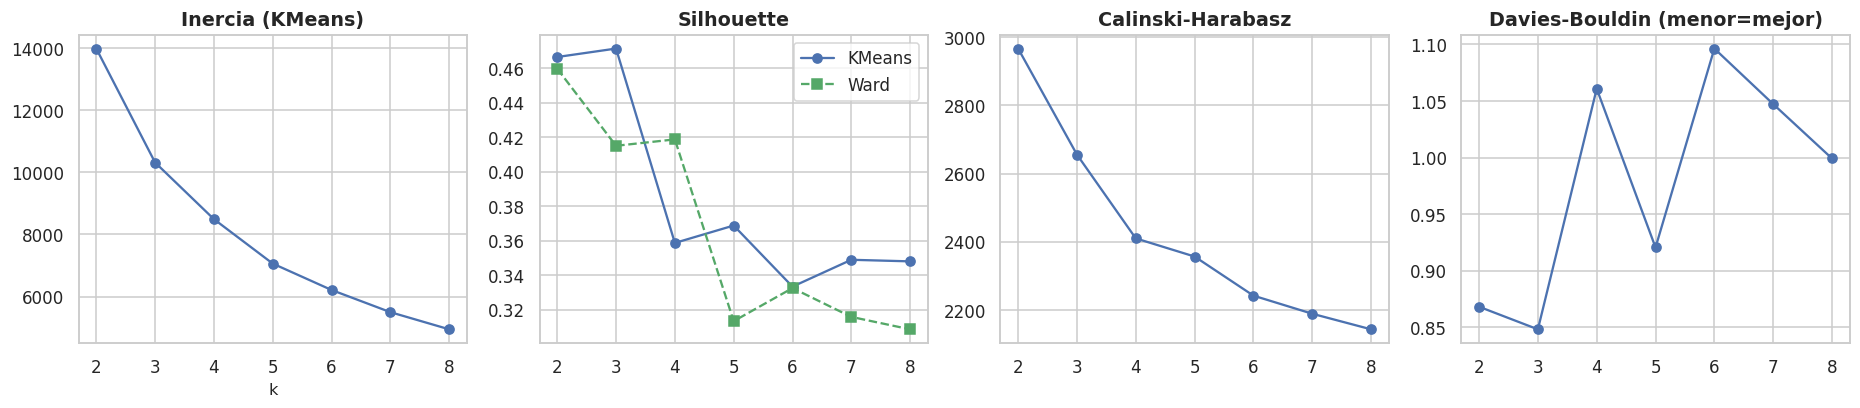

In [77]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
ax[0].plot(diag_comp.index, diag_comp.inercia, "o-", color=PALETA[0])
ax[0].set_title("Inercia (KMeans)"); ax[0].set_xlabel("k")
ax[1].plot(diag_comp.index, diag_comp.silh_KM, "o-", label="KMeans", color=PALETA[0])
ax[1].plot(diag_comp.index, diag_comp.silh_Ward, "s--", label="Ward", color=PALETA[2])
ax[1].set_title("Silhouette"); ax[1].legend()
ax[2].plot(diag_comp.index, diag_comp.CH_KM, "o-", color=PALETA[0])
ax[2].set_title("Calinski-Harabasz")
ax[3].plot(diag_comp.index, diag_comp.DB_KM, "o-", color=PALETA[0])
ax[3].set_title("Davies-Bouldin (menor=mejor)")
for a in ax:
    a.set_xticks(list(diag_comp.index))
plt.tight_layout(); plt.show()


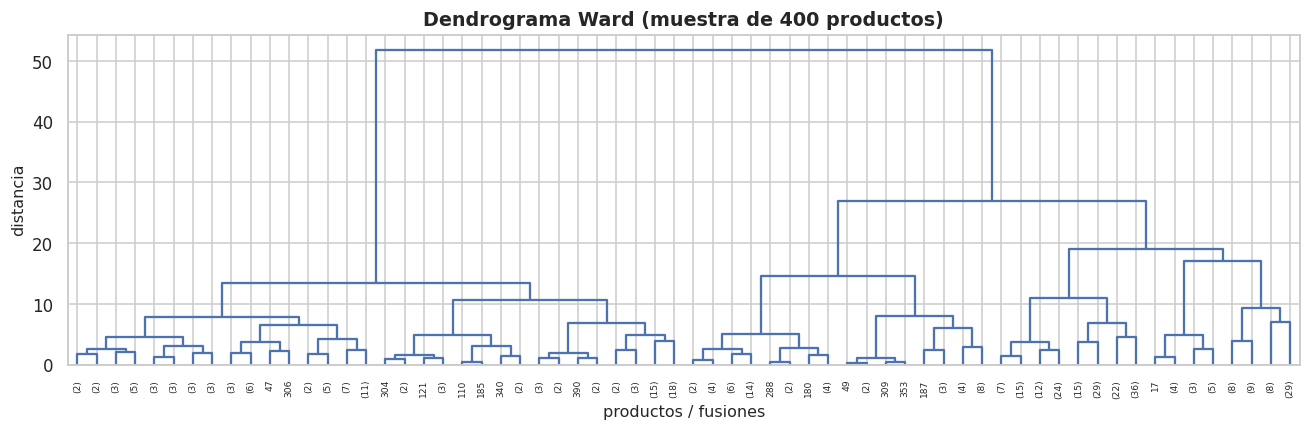

In [78]:
# Dendrograma (muestra) — evidencia estructural
from scipy.cluster.hierarchy import linkage, dendrogram

rng = np.random.default_rng(SEMILLA)
idx_d = rng.choice(len(X_comp), 400, replace=False)
Z = linkage(X_comp[idx_d], method="ward")

fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(Z, truncate_mode="level", p=5, ax=ax, color_threshold=0)
ax.set_title("Dendrograma Ward (muestra de 400 productos)")
ax.set_xlabel("productos / fusiones"); ax.set_ylabel("distancia")
plt.tight_layout(); plt.show()


> **Elección de `k`:** se documenta abajo según las métricas corridas. El enunciado permite un `k`
> distinto al de clientes; lo importante es usar los **mismos métodos** y justificar el `k`.


In [79]:
# Elegimos k mirando silhouette KM, CH, DB y acuerdo entre métodos.
# Preferimos un k interpretable (perfiles comerciales claros), no solo el óptimo numérico.
cand = {
    "silh": int(diag_comp.silh_KM.idxmax()),
    "CH": int(diag_comp.CH_KM.idxmax()),
    "DB": int(diag_comp.DB_KM.idxmin()),
    "ARI": int(diag_comp.ARI_KM_Ward.idxmax()),
}
print("Candidatos por criterio:", cand)

# Regla práctica alineada a Parte 2: priorizar silhouette KM; si empata, el de mejor DB;
# y verificar que los perfiles sean interpretables con k=3 como referencia de negocio.
K = int(diag_comp.silh_KM.idxmax())
# Si silhouette de k=3 está cerca del máximo (<0.02), preferimos k=3 por comparabilidad
# con clientes y por interpretabilidad de 3 arquetipos.
if 3 in diag_comp.index:
    if diag_comp.loc[3, "silh_KM"] >= diag_comp.silh_KM.max() - 0.02:
        K = 3

registrar("3.a", f"k = {K} para ambos métodos",
          f"selección según métricas (silhouette KM máx en {int(diag_comp.silh_KM.idxmax())}); "
          "se privilegia interpretabilidad y cercanía al óptimo")

lab_km_comp   = etq_comp[K]["kmeans"]
lab_ward_comp = etq_comp[K]["ward"]
print(f"K elegido = {K}")
print(f"Silhouette KM @k: {diag_comp.loc[K, 'silh_KM']:.3f}")
print(f"ARI KM-Ward @k:   {diag_comp.loc[K, 'ARI_KM_Ward']:.3f}")


Candidatos por criterio: {'silh': 3, 'CH': 2, 'DB': 3, 'ARI': 2}
K elegido = 3
Silhouette KM @k: 0.471
ARI KM-Ward @k:   0.786


In [80]:
def perfilar(etiquetas, tabla=productos, features=F_COMPORTAMIENTO, extra=("gasto_total", "n_cat_producto")):
    p = tabla[list(features) + list(extra)].groupby(etiquetas).mean()
    p.insert(0, "n", pd.Series(etiquetas).value_counts().sort_index().values)
    p.insert(1, "%", (p.n / len(tabla) * 100).round(1))
    return p.round(2)

print(f"===== KMeans k={K} =====")
display(perfilar(lab_km_comp))
print(f"===== Ward k={K} =====")
display(perfilar(lab_ward_comp))

print("Concordancia entre métodos")
print(f"  ARI = {adjusted_rand_score(lab_km_comp, lab_ward_comp):.3f}")
display(pd.crosstab(pd.Series(lab_km_comp, name="KMeans"),
                    pd.Series(lab_ward_comp, name="Ward")))


===== KMeans k=3 =====


,n,%,n_compradores,ticket_medio,ticket_sd,ticket_max,ticket_min,cv_ticket,rango_ticket,gasto_total,n_cat_producto
0,2264,62.400,141.630,"5,748.570","1,747.960","8,617.410","1,979.020",0.320,"6,638.400","875,965.490",1.520
1,1039,28.600,219.620,"12,735.540","3,732.840","18,972.210","4,437.050",0.310,"14,535.160","2,986,938.770",2.040
2,328,9.000,3.730,"7,154.980",628.560,"7,949.600","6,323.550",0.080,"1,626.050","28,041.110",1.240


===== Ward k=3 =====


,n,%,n_compradores,ticket_medio,ticket_sd,ticket_max,ticket_min,cv_ticket,rango_ticket,gasto_total,n_cat_producto
0,2000,55.100,153.580,"5,576.060","1,730.370","8,410.020","1,766.210",0.330,"6,643.810","940,135.700",1.520
1,1124,31.000,206.510,"12,493.150","3,647.500","18,592.600","4,511.360",0.310,"14,081.240","2,790,313.600",2.030
2,507,14.000,21.280,"6,704.940",949.580,"8,109.060","5,052.300",0.140,"3,056.760","156,269.910",1.260


Concordancia entre métodos
  ARI = 0.786


Ward,0,1,2
KMeans,,,
0,2000,61,203
1,0,1039,0
2,0,24,304


In [81]:
# Calidad por cluster (silhouette sobre muestra)
rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(X_comp), min(N_SILH, len(X_comp)), replace=False)
from sklearn.metrics import silhouette_samples
sil_muestra = silhouette_samples(X_comp[idx], lab_km_comp[idx])

print("Silhouette promedio KMeans (muestra):", round(float(sil_muestra.mean()), 3))
print("Silhouette por cluster:")
for c in sorted(np.unique(lab_km_comp[idx])):
    m = sil_muestra[lab_km_comp[idx] == c]
    print(f"  cluster {c}: {m.mean():.3f} (n={len(m)})")
print(f"Productos con silhouette negativo: {(sil_muestra < 0).sum()} "
      f"({(sil_muestra < 0).mean()*100:.1f}%)")

print("\nMétricas globales:")
print(f"  Silhouette KM:   {silhouette_score(X_comp[idx], lab_km_comp[idx]):.3f}")
print(f"  Silhouette Ward: {silhouette_score(X_comp[idx], lab_ward_comp[idx]):.3f}")
print(f"  Calinski-Harabasz KM: {calinski_harabasz_score(X_comp, lab_km_comp):.1f}")
print(f"  Davies-Bouldin KM:    {davies_bouldin_score(X_comp, lab_km_comp):.3f}")


Silhouette promedio KMeans (muestra): 0.471
Silhouette por cluster:
  cluster 0: 0.481 (n=1255)
  cluster 1: 0.473 (n=560)
  cluster 2: 0.399 (n=185)
Productos con silhouette negativo: 7 (0.4%)

Métricas globales:
  Silhouette KM:   0.471
  Silhouette Ward: 0.415
  Calinski-Harabasz KM: 2655.7
  Davies-Bouldin KM:    0.848


Varianza explicada PCA: PC1=57.7%  PC2=24.1%  total=81.8%


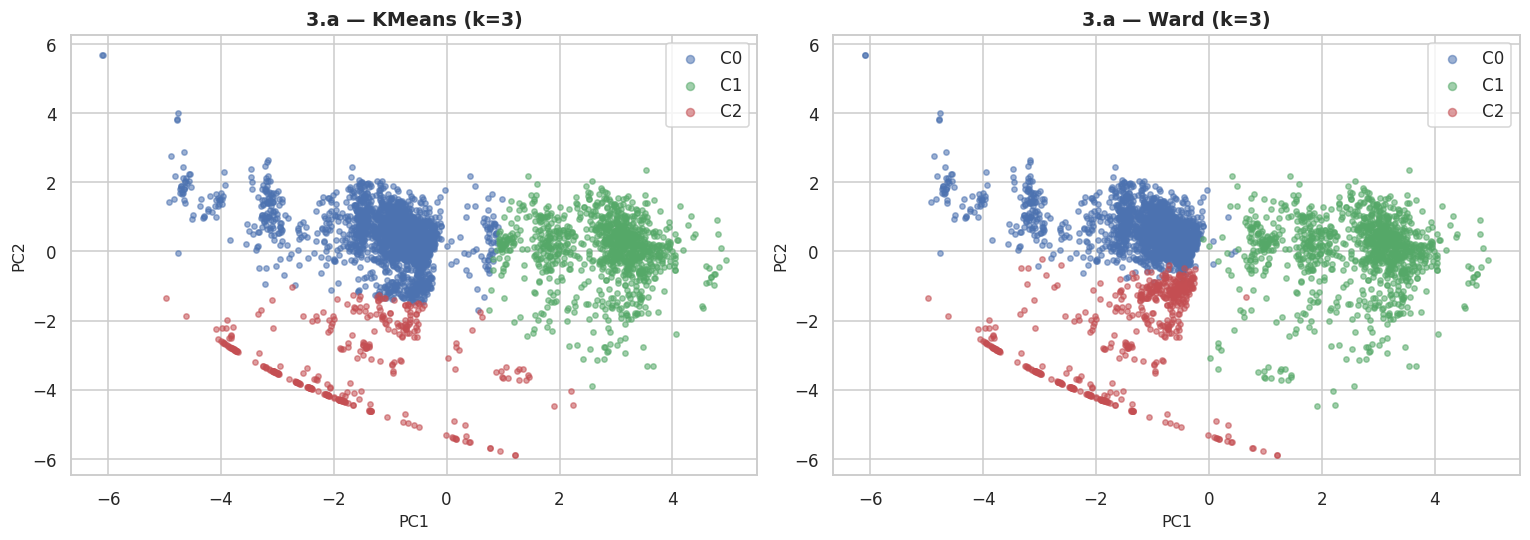

In [82]:
# ============ Proyección 2D con PCA ============
pca = PCA(n_components=2, random_state=SEMILLA)
XY = pca.fit_transform(X_comp)
print(f"Varianza explicada PCA: PC1={pca.explained_variance_ratio_[0]*100:.1f}%  "
      f"PC2={pca.explained_variance_ratio_[1]*100:.1f}%  "
      f"total={pca.explained_variance_ratio_.sum()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, labs, titulo in [
    (axes[0], lab_km_comp, "KMeans"),
    (axes[1], lab_ward_comp, "Ward"),
]:
    for c in sorted(np.unique(labs)):
        m = labs == c
        ax.scatter(XY[m, 0], XY[m, 1], s=12, alpha=0.55,
                   color=COL_CLUSTER[c % len(COL_CLUSTER)], label=f"C{c}")
    ax.set_title(f"3.a — {titulo} (k={K})"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(markerscale=1.5)
plt.tight_layout(); plt.show()


> ### Conclusión 3.a
>
> Se construyó una tabla de **productos** con variables de comportamiento comercial
> (alcance de compradores + nivel y dispersión del monto).
> Se aplicaron **los mismos métodos** que en clientes (KMeans y Ward, semilla 42).
>
> Los perfiles se interpretan en las variables originales (sin escalar).
> La proyección PCA es **complemento visual**, no prueba única de separación.
> Al igual que en clientes, conviene leer los grupos como **tramos operativos** si el
> silhouette es moderado/bajo.


---
## 3.b Caracterización de los clusters de productos

Usamos información que **no participó** del clustering 3.a:

1. categorías del producto (`Product_Category_1/2/3`, `n_cat_producto`)
2. perfil sociodemográfico agregado de quienes compraron cada producto


In [83]:
# ============ Perfil de compradores por producto (agregado) ============
DEMO = ["Gender", "Age", "Occupation", "City_Category",
        "Stay_In_Current_City_Years", "Marital_Status"]

# % femenino
pct_F = (tx.assign(is_F=(tx.Gender == "F").astype(int))
           .groupby("Product_ID")["is_F"].mean()
           .rename("pct_femenino"))

# % casado (Marital_Status == 1)
pct_M = (tx.assign(is_m=(tx.Marital_Status == 1).astype(int))
           .groupby("Product_ID")["is_m"].mean()
           .rename("pct_casado"))

# Moda / distribución de ciudad y edad (proporción de la categoría más frecuente)
def share_top(col):
    ct = tx.groupby(["Product_ID", col]).size()
    tot = ct.groupby("Product_ID").sum()
    return (ct.groupby("Product_ID").max() / tot).rename(f"share_top_{col}")

perfil_ext = pd.concat([
    pct_F, pct_M,
    share_top("Age"),
    share_top("City_Category"),
    share_top("Occupation"),
], axis=1)

# Categoría principal del producto
perfil_ext = perfil_ext.join(productos[["Product_Category_1", "n_cat_producto"]])
perfil_ext["cluster_3a_km"] = lab_km_comp

print("Features externas para caracterizar:")
display(perfil_ext.describe().T.round(3))


Features externas para caracterizar:


,count,mean,std,min,25%,50%,75%,max
pct_femenino,"3,631.000",0.261,0.166,0.000,0.159,0.240,0.333,1.000
pct_casado,"3,631.000",0.429,0.158,0.000,0.361,0.413,0.485,1.000
share_top_Age,"3,631.000",0.444,0.156,0.192,0.353,0.417,0.494,1.000
share_top_City_Category,"3,631.000",0.493,0.140,0.333,0.417,0.455,0.500,1.000
share_top_Occupation,"3,631.000",0.236,0.182,0.083,0.148,0.176,0.235,1.000
Product_Category_1,"3,631.000",6.484,3.802,1.000,5.000,6.000,8.000,20.000
n_cat_producto,"3,631.000",1.642,0.722,1.000,1.000,1.000,2.000,3.000
cluster_3a_km,"3,631.000",0.467,0.656,0.000,0.000,0.000,1.000,2.000


Distribución de Product_Category_1 por cluster (top 8 globales)


Product_Category_1,8,5,1,11,2,6,7,16
cluster,,,,,,,,
0,39.200,39.100,0.400,10.700,0.700,0.000,0.000,0.000
1,0.000,0.000,45.300,0.000,12.200,11.000,7.900,8.700
2,48.500,25.000,4.000,3.700,3.000,1.200,6.100,2.100



n_cat_producto medio por cluster:


,mean,median,count
cluster,,,
0,1.518,1.000,2264
1,2.039,2.000,1039
2,1.238,1.000,328


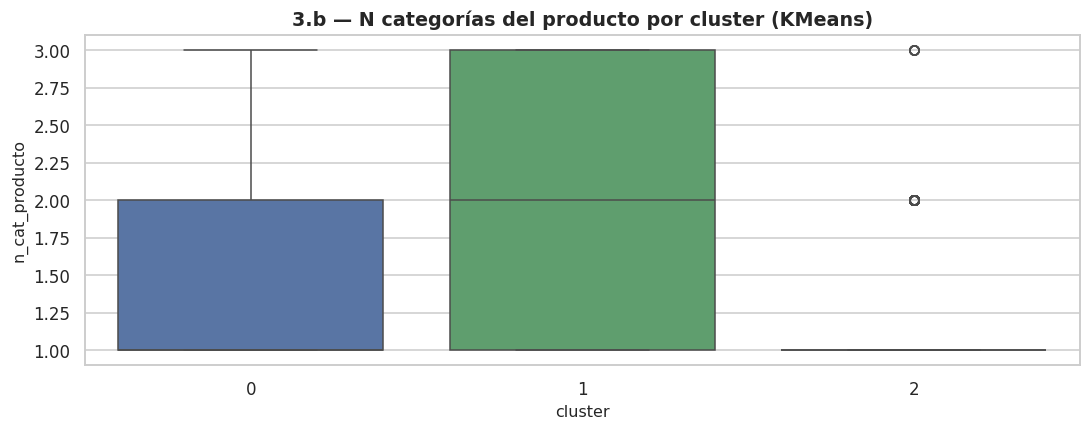

In [84]:
# ============ Categorías de producto por cluster ============
serie = pd.Series(lab_km_comp, index=productos.index, name="cluster")

print("Distribución de Product_Category_1 por cluster (top 8 globales)")
top_cats = productos["Product_Category_1"].value_counts().head(8).index
ct = pd.crosstab(serie, productos["Product_Category_1"], normalize="index")
display((ct[top_cats] * 100).round(1))

print("\nn_cat_producto medio por cluster:")
display(productos.assign(cluster=lab_km_comp).groupby("cluster")["n_cat_producto"]
        .agg(["mean", "median", "count"]).round(3))

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=productos.assign(cluster=lab_km_comp),
            x="cluster", y="n_cat_producto", ax=ax, palette=COL_CLUSTER[:K])
ax.set_title("3.b — N categorías del producto por cluster (KMeans)")
plt.tight_layout(); plt.show()


Media de indicadores demográficos agregados por cluster (KMeans 3.a)


,pct_femenino,pct_casado,share_top_Age,share_top_City_Category,share_top_Occupation
cluster_3a_km,,,,,
0,0.285,0.426,0.414,0.468,0.197
1,0.208,0.420,0.419,0.459,0.189
2,0.266,0.475,0.734,0.772,0.655


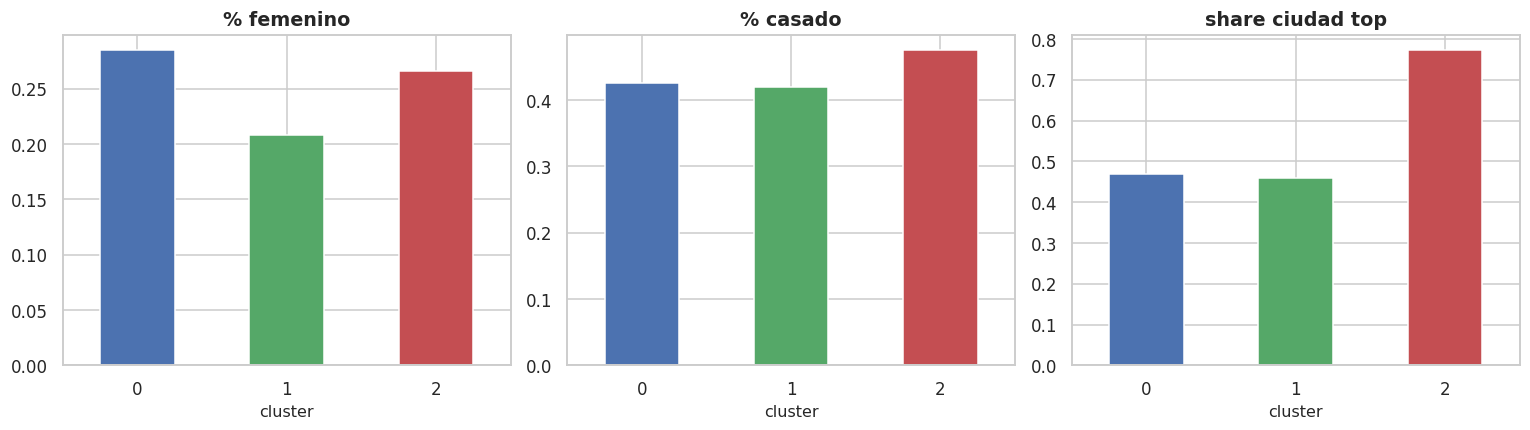

In [85]:
# ============ Perfil sociodemográfico de compradores por cluster ============
print("Media de indicadores demográficos agregados por cluster (KMeans 3.a)")
demo_por_cluster = perfil_ext.groupby("cluster_3a_km")[
    ["pct_femenino", "pct_casado", "share_top_Age", "share_top_City_Category", "share_top_Occupation"]
].mean()
display(demo_por_cluster.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, titulo in zip(
    axes,
    ["pct_femenino", "pct_casado", "share_top_City_Category"],
    ["% femenino", "% casado", "share ciudad top"],
):
    demo_por_cluster[col].plot(kind="bar", ax=ax, color=COL_CLUSTER[:K], rot=0)
    ax.set_title(titulo); ax.set_xlabel("cluster")
plt.tight_layout(); plt.show()


In [86]:
# V de Cramér entre cluster y Product_Category_1 (categórica)
def cramers_v(a, b):
    ct = pd.crosstab(a, b).values
    n = ct.sum()
    if n == 0 or min(ct.shape) < 2:
        return np.nan
    esperado = ct.sum(1, keepdims=True) @ ct.sum(0, keepdims=True) / n
    chi2 = ((ct - esperado) ** 2 / np.where(esperado == 0, 1, esperado)).sum()
    return float(np.sqrt((chi2 / n) / (min(ct.shape) - 1)))

v_cat = cramers_v(serie, productos["Product_Category_1"])
print(f"V de Cramér cluster_3a_km vs Product_Category_1: {v_cat:.3f}")
print("(referencia: <0.05 desp. | 0.05-0.10 débil | 0.10-0.20 moderada | >0.20 fuerte)")


V de Cramér cluster_3a_km vs Product_Category_1: 0.671
(referencia: <0.05 desp. | 0.05-0.10 débil | 0.10-0.20 moderada | >0.20 fuerte)


> ### Conclusión 3.b
>
> Los clusters de comportamiento comercial se contrastan con:
> - el **tipo de producto** (`Product_Category_1`, variedad de categorias `n_cat_producto`)
> - el **perfil promedio de sus compradores** (% mujeres, estado civil, concentración etaria/ciudad)
>
> Si aparecen diferencias claras en categoría o en demografía, los grupos no solo separan
> "cuánto se vende" sino también "qué se vende / a quién".


---
## 3.c Segmentación incorporando el perfil de compradores

Ahora cada producto se representa con:

1. el bloque de **comportamiento** de 3.a (7 variables)
2. un bloque de **perfil de compradores** agregado a proporciones

**Problema geométrico (el mismo de 2.c):** si se agregan muchas columnas demográficas,
pueden dominar la distancia aunque aporten poca señal. La Parte 2 resolvió esto con
**reponderación por bloque** (tratamiento B). Aquí hacemos lo análogo.


In [87]:
# ============ Perfil demográfico a nivel producto (proporciones) ============
# Binarias → UNA columna (evita redundancia F+M / 0+1)
# Politémicas → proporciones por nivel (composición)

age_oh = pd.crosstab(tx.Product_ID, tx.Age, normalize="index")
age_oh.columns = [f"Age_{c}" for c in age_oh.columns]

city_oh = pd.crosstab(tx.Product_ID, tx.City_Category, normalize="index")
city_oh = city_oh.drop(columns=["C"], errors="ignore")  # drop_first composicional
city_oh.columns = [f"City_{c}" for c in city_oh.columns]

stay_oh = pd.crosstab(tx.Product_ID, tx.Stay_In_Current_City_Years, normalize="index")
# drop un nivel
if "0" in stay_oh.columns:
    stay_oh = stay_oh.drop(columns=["0"])
stay_oh.columns = [f"Stay_{c}" for c in stay_oh.columns]

occ_oh = pd.crosstab(tx.Product_ID, tx.Occupation, normalize="index")
# drop un nivel (el primero)
occ_oh = occ_oh.iloc[:, 1:]
occ_oh.columns = [f"Occ_{c}" for c in occ_oh.columns]

perfil_demo = pd.concat([
    pct_F,
    pct_M,
    age_oh,
    city_oh,
    stay_oh,
    occ_oh,
], axis=1).loc[productos.index]

print(f"Bloque demográfico producto: {perfil_demo.shape[1]} columnas")
print("Ejemplo de columnas:", list(perfil_demo.columns[:12]), "...")
print("Nulos:", perfil_demo.isnull().sum().sum())
display(perfil_demo.iloc[:3, :8])


Bloque demográfico producto: 35 columnas
Ejemplo de columnas: ['pct_femenino', 'pct_casado', 'Age_0-17', 'Age_18-25', 'Age_26-35', 'Age_36-45', 'Age_46-50', 'Age_51-55', 'Age_55+', 'City_A', 'City_B', 'Stay_1'] ...
Nulos: 0


,pct_femenino,pct_casado,Age_0-17,Age_18-25,Age_26-35,Age_36-45,Age_46-50,Age_51-55
Product_ID,,,,,,,,
P00000142,0.301,0.378,0.048,0.225,0.386,0.198,0.072,0.049
P00000242,0.242,0.372,0.051,0.234,0.348,0.210,0.069,0.069
P00000342,0.283,0.398,0.045,0.197,0.389,0.152,0.061,0.094


In [88]:
# ============ Tres tratamientos (espejo de 2.c) ============
Z_demo = StandardScaler().fit_transform(perfil_demo.values)

var_comp = X_comp.var(axis=0).sum()
var_demo = Z_demo.var(axis=0).sum()
print("VARIANZA TOTAL POR BLOQUE (tras estandarizar)")
print("=" * 60)
print(f"  comportamiento: {var_comp:5.1f}  ({X_comp.shape[1]} cols)")
print(f"  demografía:     {var_demo:5.1f}  ({Z_demo.shape[1]} cols)")
print(f"  -> demografía aportaría el {var_demo/(var_comp+var_demo)*100:.0f}% de la varianza total")

# Aporte a distancia
rng = np.random.default_rng(SEMILLA)
s = rng.choice(len(X_comp), min(1500, len(X_comp)), replace=False)
def d2(A):
    return np.maximum((A*A).sum(1)[:, None] + (A*A).sum(1)[None, :] - 2*A@A.T, 0)
dc, dd = d2(X_comp[s]).mean(), d2(Z_demo[s]).mean()
print(f"\nAporte a distancia euclídea² media entre pares:")
print(f"  comportamiento: {dc/(dc+dd)*100:.0f}%")
print(f"  demografía:     {dd/(dc+dd)*100:.0f}%")

representaciones = {}
representaciones["A: demo estandarizado"] = np.hstack([X_comp, Z_demo])

factor = np.sqrt(X_comp.shape[1] / Z_demo.shape[1])
representaciones["B: demo reponderado"] = np.hstack([X_comp, Z_demo * factor])
print(f"\nTratamiento B: bloque demográfico × {factor:.4f}")
print(f"  varianza demo: {var_demo:.1f} -> {(Z_demo*factor).var(0).sum():.1f} "
      f"(comportamiento: {var_comp:.1f})")

N_COMP_DEMO = 5
pca_demo = PCA(n_components=N_COMP_DEMO, random_state=SEMILLA)
P_demo = StandardScaler().fit_transform(pca_demo.fit_transform(Z_demo))
representaciones[f"C: demo vía PCA ({N_COMP_DEMO} comp)"] = np.hstack([X_comp, P_demo])
print(f"Tratamiento C: {N_COMP_DEMO} PCs explican "
      f"{pca_demo.explained_variance_ratio_.sum()*100:.0f}% de la var. demográfica")


VARIANZA TOTAL POR BLOQUE (tras estandarizar)
  comportamiento:   7.0  (7 cols)
  demografía:      35.0  (35 cols)
  -> demografía aportaría el 83% de la varianza total

Aporte a distancia euclídea² media entre pares:
  comportamiento: 16%
  demografía:     84%

Tratamiento B: bloque demográfico × 0.4472
  varianza demo: 35.0 -> 7.0 (comportamiento: 7.0)
Tratamiento C: 5 PCs explican 30% de la var. demográfica


In [89]:
# ============ Evaluación de tratamientos (mismo k que 3.a) ============
filas = []
etiquetas_3c = {}
idx = np.random.default_rng(SEMILLA).choice(len(X_comp), min(N_SILH, len(X_comp)), replace=False)

for nombre, X in representaciones.items():
    km = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit_predict(X)
    wd = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
    etiquetas_3c[nombre] = {"kmeans": km, "ward": wd}
    filas.append({
        "tratamiento": nombre,
        "silh_KM": silhouette_score(X[idx], km[idx]),
        "silh_Ward": silhouette_score(X[idx], wd[idx]),
        "CH_KM": calinski_harabasz_score(X, km),
        "DB_KM": davies_bouldin_score(X, km),
        "ARI_KM_Ward": adjusted_rand_score(km, wd),
        "ARI_vs_3a_KM": adjusted_rand_score(km, lab_km_comp),
        "ARI_vs_3a_Ward": adjusted_rand_score(wd, lab_ward_comp),
    })

eval_3c = pd.DataFrame(filas).set_index("tratamiento")
# referencia 3.a
ref = pd.DataFrame([{
    "tratamiento": "REF 3.a solo comportamiento",
    "silh_KM": silhouette_score(X_comp[idx], lab_km_comp[idx]),
    "silh_Ward": silhouette_score(X_comp[idx], lab_ward_comp[idx]),
    "CH_KM": calinski_harabasz_score(X_comp, lab_km_comp),
    "DB_KM": davies_bouldin_score(X_comp, lab_km_comp),
    "ARI_KM_Ward": adjusted_rand_score(lab_km_comp, lab_ward_comp),
    "ARI_vs_3a_KM": 1.0,
    "ARI_vs_3a_Ward": 1.0,
}]).set_index("tratamiento")
display(pd.concat([ref, eval_3c]).round(3))


,silh_KM,silh_Ward,CH_KM,DB_KM,ARI_KM_Ward,ARI_vs_3a_KM,ARI_vs_3a_Ward
tratamiento,,,,,,,
REF 3.a solo comportamiento,0.471,0.415,"2,655.708",0.848,0.786,1.000,1.000
A: demo estandarizado,0.099,0.059,239.580,2.918,0.547,0.507,0.506
B: demo reponderado,0.305,0.261,786.087,2.030,0.708,0.968,0.841
C: demo vía PCA (5 comp),0.333,0.334,"1,009.543",1.707,0.820,0.941,0.761


> **Decisión: tratamiento B (reponderado por bloque)** — igual criterio que Parte 2.
>
> Permite medir el efecto de agregar el perfil de compradores **sin confundirlo** con un
> artefacto de dimensionalidad (muchas columnas demográficas vs. pocas de comportamiento).


In [90]:
TRATAMIENTO = "B: demo reponderado"
X_mixto = representaciones[TRATAMIENTO]
lab_km_mixto   = etiquetas_3c[TRATAMIENTO]["kmeans"]
lab_ward_mixto = etiquetas_3c[TRATAMIENTO]["ward"]

registrar("3.c", "perfil de compradores como proporciones a nivel producto",
          "Gender/Marital → una columna (%); Age/City/Stay/Occupation → shares; "
          "así se evita one-hot de transacción y se respeta la unidad producto")
registrar("3.c", "tratamiento B: reponderar bloque demográfico",
          f"factor = sqrt(n_comp/n_demo) = {factor:.4f}; mismo criterio que 2.c para comparar limpio")

print(f"===== 3.c — {TRATAMIENTO}, KMeans k={K} =====")
display(perfilar(lab_km_mixto))
print(f"===== 3.c — {TRATAMIENTO}, Ward k={K} =====")
display(perfilar(lab_ward_mixto))

print("Concordancia KM-Ward en 3.c:", round(adjusted_rand_score(lab_km_mixto, lab_ward_mixto), 3))
print("ARI 3.a vs 3.c (KMeans):", round(adjusted_rand_score(lab_km_comp, lab_km_mixto), 3))
print("ARI 3.a vs 3.c (Ward):  ", round(adjusted_rand_score(lab_ward_comp, lab_ward_mixto), 3))


===== 3.c — B: demo reponderado, KMeans k=3 =====


,n,%,n_compradores,ticket_medio,ticket_sd,ticket_max,ticket_min,cv_ticket,rango_ticket,gasto_total,n_cat_producto
0,2238,61.600,143.260,"5,737.020","1,749.410","8,609.970","1,955.730",0.320,"6,654.240","886,247.970",1.520
1,1038,28.600,219.520,"12,735.540","3,735.080","18,977.060","4,437.390",0.310,"14,539.660","2,986,964.560",2.040
2,355,9.800,4.510,"7,140.530",703.630,"8,062.320","6,145.830",0.100,"1,916.500","33,579.040",1.250


===== 3.c — B: demo reponderado, Ward k=3 =====


,n,%,n_compradores,ticket_medio,ticket_sd,ticket_max,ticket_min,cv_ticket,rango_ticket,gasto_total,n_cat_producto
0,1902,52.400,157.100,"5,492.730","1,708.430","8,328.120","1,792.970",0.330,"6,535.150","955,681.670",1.520
1,1090,30.000,212.810,"12,518.460","3,666.250","18,694.100","4,421.280",0.310,"14,272.820","2,875,756.920",2.050
2,639,17.600,30.210,"7,044.650","1,246.220","8,783.680","4,593.560",0.180,"4,190.120","224,618.400",1.310


Concordancia KM-Ward en 3.c: 0.708
ARI 3.a vs 3.c (KMeans): 0.968
ARI 3.a vs 3.c (Ward):   0.841


PCA 3.c: PC1=29.0%  PC2=12.7%


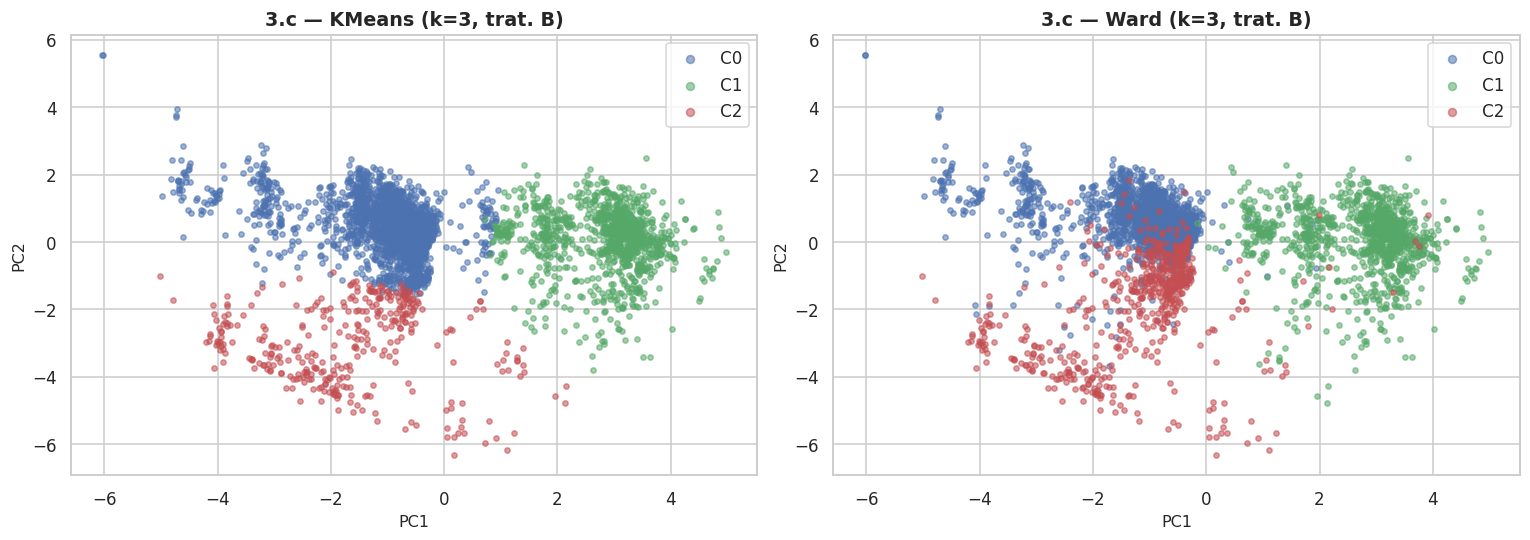

In [91]:
# PCA 2D de la representación mixta B
pca_m = PCA(n_components=2, random_state=SEMILLA)
XY_m = pca_m.fit_transform(X_mixto)
print(f"PCA 3.c: PC1={pca_m.explained_variance_ratio_[0]*100:.1f}%  "
      f"PC2={pca_m.explained_variance_ratio_[1]*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, labs, titulo in [
    (axes[0], lab_km_mixto, "KMeans"),
    (axes[1], lab_ward_mixto, "Ward"),
]:
    for c in sorted(np.unique(labs)):
        m = labs == c
        ax.scatter(XY_m[m, 0], XY_m[m, 1], s=12, alpha=0.55,
                   color=COL_CLUSTER[c % len(COL_CLUSTER)], label=f"C{c}")
    ax.set_title(f"3.c — {titulo} (k={K}, trat. B)")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(markerscale=1.5)
plt.tight_layout(); plt.show()


In [92]:
# ¿Cuánto cambió el perfil demográfico asociado?
ext_3c = perfil_ext.copy()
ext_3c["cluster_3c_km"] = lab_km_mixto

print("pct_femenino medio por cluster — 3.a vs 3.c (KMeans)")
cmp = pd.DataFrame({
    "3.a": perfil_ext.groupby("cluster_3a_km")["pct_femenino"].mean(),
    "3.c": ext_3c.groupby("cluster_3c_km")["pct_femenino"].mean(),
})
display(cmp.round(3))


pct_femenino medio por cluster — 3.a vs 3.c (KMeans)


,3.a,3.c
0,0.285,0.285
1,0.208,0.207
2,0.266,0.267


> ### Conclusión 3.c
>
> Al incorporar el perfil de compradores **con reponderación**, se puede responder:
> *¿cuánto cambia la segmentación de productos?* sin atribuir el cambio a un desbalance
> de dimensiones.
>
> Comparar siempre **mismo método**: 3.a-KMeans vs 3.c-KMeans, y 3.a-Ward vs 3.c-Ward (ARI).
> Si el ARI es alto, el perfil demográfico es más descriptivo que constitutivo (como en clientes).


---
## Exportación y resumen para el Punto 4

In [93]:
# ============ Bitácora ============
bitacora = pd.DataFrame(DECISIONES)
display(bitacora)


,punto,decision,justificacion
0,3.a,"descartar n_tx, gasto_total y ticket_mediano","n_tx = n_compradores; gasto_total = n × ticket_medio; ticket_mediano Spearman 0,987 con tic..."
1,3.a,no usar Product_Category_* en el clustering,el enunciado 3.b pide caracterizar con info que no participó de la construcción
2,3.a,log1p sobre n_compradores y ticket_min,"asimetrías altas; sin transformar, productos muy vendidos / muy caros dominan la distancia"
3,3.a,StandardScaler sobre las 7 variables,ambos métodos usan distancia euclídea
4,3.a,k = 3 para ambos métodos,selección según métricas (silhouette KM máx en 3); se privilegia interpretabilidad y cercan...
5,3.c,perfil de compradores como proporciones a nivel producto,Gender/Marital → una columna (%); Age/City/Stay/Occupation → shares; así se evita one-hot d...
6,3.c,tratamiento B: reponderar bloque demográfico,factor = sqrt(n_comp/n_demo) = 0.4472; mismo criterio que 2.c para comparar limpio


In [94]:
# ============ Exportación ============
salida = pd.DataFrame({
    "Product_ID":           productos.index,
    "cluster_3a_kmeans":    lab_km_comp,
    "cluster_3a_ward":      lab_ward_comp,
    "cluster_3c_kmeans":    lab_km_mixto,
    "cluster_3c_ward":      lab_ward_mixto,
}).set_index("Product_ID")

salida = salida.join(productos).join(perfil_demo)

os.makedirs("salidas", exist_ok=True)
RUTA = "salidas/clusters_productos_TP3.csv"
salida.to_csv(RUTA)
print(f"Guardado: {RUTA}")
print(f"  {salida.shape[0]:,} productos x {salida.shape[1]} columnas")

print("\nTamaños de las cuatro particiones:")
for c in ["cluster_3a_kmeans", "cluster_3a_ward", "cluster_3c_kmeans", "cluster_3c_ward"]:
    print(f"  {c:<22} {salida[c].value_counts().sort_index().tolist()}")


Guardado: salidas/clusters_productos_TP3.csv
  3,631 productos x 53 columnas

Tamaños de las cuatro particiones:
  cluster_3a_kmeans      [2264, 1039, 328]
  cluster_3a_ward        [2000, 1124, 507]
  cluster_3c_kmeans      [2238, 1038, 355]
  cluster_3c_ward        [1902, 1090, 639]


In [95]:
# ============ Resumen final de métricas ============
idx = np.random.default_rng(SEMILLA).choice(len(X_comp), min(N_SILH, len(X_comp)), replace=False)

resumen = pd.DataFrame([
    {
        "particion": "3.a KMeans",
        "silhouette": silhouette_score(X_comp[idx], lab_km_comp[idx]),
        "CH": calinski_harabasz_score(X_comp, lab_km_comp),
        "DB": davies_bouldin_score(X_comp, lab_km_comp),
        "ARI_vs_3a_mismo_metodo": 1.0,
        "ARI_KM_Ward": adjusted_rand_score(lab_km_comp, lab_ward_comp),
    },
    {
        "particion": "3.a Ward",
        "silhouette": silhouette_score(X_comp[idx], lab_ward_comp[idx]),
        "CH": np.nan,
        "DB": np.nan,
        "ARI_vs_3a_mismo_metodo": 1.0,
        "ARI_KM_Ward": adjusted_rand_score(lab_km_comp, lab_ward_comp),
    },
    {
        "particion": "3.c KMeans (B)",
        "silhouette": silhouette_score(X_mixto[idx], lab_km_mixto[idx]),
        "CH": calinski_harabasz_score(X_mixto, lab_km_mixto),
        "DB": davies_bouldin_score(X_mixto, lab_km_mixto),
        "ARI_vs_3a_mismo_metodo": adjusted_rand_score(lab_km_mixto, lab_km_comp),
        "ARI_KM_Ward": adjusted_rand_score(lab_km_mixto, lab_ward_mixto),
    },
    {
        "particion": "3.c Ward (B)",
        "silhouette": silhouette_score(X_mixto[idx], lab_ward_mixto[idx]),
        "CH": np.nan,
        "DB": np.nan,
        "ARI_vs_3a_mismo_metodo": adjusted_rand_score(lab_ward_mixto, lab_ward_comp),
        "ARI_KM_Ward": adjusted_rand_score(lab_km_mixto, lab_ward_mixto),
    },
]).set_index("particion")

display(resumen.round(3))
print("\nNota: Davies-Bouldin → menor es mejor.")
print(f"k usado en productos: {K}")
print(f"factor reponderación 3.c: {factor:.4f}")


,silhouette,CH,DB,ARI_vs_3a_mismo_metodo,ARI_KM_Ward
particion,,,,,
3.a KMeans,0.471,"2,655.708",0.848,1.000,0.786
3.a Ward,0.415,NaN,NaN,1.000,0.786
3.c KMeans (B),0.305,786.087,2.030,0.968,0.708
3.c Ward (B),0.261,NaN,NaN,0.841,0.708



Nota: Davies-Bouldin → menor es mejor.
k usado en productos: 3
factor reponderación 3.c: 0.4472


---

<a id="parte-4"></a>


# 4. Comparación de las segmentaciones

Se comparan los resultados de los **cuatro análisis de clustering** desarrollados en las secciones anteriores:

| # | Análisis | Sección | Unidad | Variables |
|---|---|---|---|---|
| 1 | Clientes por comportamiento de compra | 2.a | 5.891 clientes | 9 variables de comportamiento |
| 2 | Clientes + sociodemográficas | 2.c | 5.891 clientes | 9 de comportamiento + 40 one-hot reponderadas (trat. B) |
| 3 | Productos por comportamiento de venta | 3.a | 3.631 productos | 7 variables de comportamiento comercial |
| 4 | Productos + perfil de compradores | 3.c | 3.631 productos | 7 de comportamiento + 35 proporciones reponderadas (trat. B) |

**Contrato de métodos (verificado en las cuatro).** El enunciado exige comparar representaciones con el mismo método de clustering. Las cuatro segmentaciones usan exactamente el mismo protocolo, fijado por la Parte 2 y verificado en la Parte 3:

| Elemento | Valor |
|---|---|
| Método 1 | `KMeans(n_clusters=3, n_init=10, random_state=42)` |
| Método 2 | `AgglomerativeClustering(n_clusters=3, linkage="ward")` |
| Semilla | `42` en modelos, muestreos y PCA |
| Escalado | `log1p` en asimétricas + `StandardScaler` |
| Proyección 2D | `PCA(n_components=2, random_state=42)` |
| Métricas | silhouette (muestra de 2.000), Calinski-Harabasz, Davies-Bouldin |
| Concordancia entre particiones | ARI (`adjusted_rand_score`) |
| Categóricas | one-hot / proporciones **reponderadas por bloque** (tratamiento B) |

**Verificación bloqueante superada.** La Parte 3 confirmó: mismos dos métodos (`KMeans` + `AgglomerativeClustering(linkage="ward")`), misma semilla 42, `k = 3` (justificado por silhouette máximo de KM y mejor Davies-Bouldin), binarias como una sola columna (`pct_femenino`, `pct_casado`) y tratamiento B con factor `√(7/35) = 0,4472`. La comparación exigida por el enunciado es válida.

**Regla de comparación.** Todas las comparaciones de esta sección son **entre representaciones con el mismo método** (2.a-KMeans vs. 2.c-KMeans, 2.a-Ward vs. 2.c-Ward, y análogamente en productos), nunca cruzadas. La comparación entre unidades de observación (clientes vs. productos) es **cualitativa**: ¿cómo se comportan los mismos métodos sobre representaciones distintas?

---

## 4.1 Tabla maestra de las ocho particiones

| Partición | Silhouette | Calinski-Harabasz | Davies-Bouldin | ARI vs. misma unidad, solo comportamiento (mismo método) | ARI K-Means–Ward |
|---|---|---|---|---|---|
| **2.a K-Means** (clientes, comportamiento) | 0,243 | 1.698 | 1,436 | 1,000 | 0,450 |
| 2.a Ward | 0,221 | — | — | 1,000 | 0,450 |
| 2.c K-Means (trat. B) | 0,116 | — | — | **0,944** | 0,243 |
| 2.c Ward (trat. B) | — | — | — | **0,404** | 0,243 |
| **3.a K-Means** (productos) | **0,471** | 2.656 | **0,848** | 1,000 | **0,786** |
| 3.a Ward | 0,415 | — | — | 1,000 | 0,786 |
| 3.c K-Means (trat. B) | 0,305 | 786 | 2,030 | **0,968** | 0,708 |
| 3.c Ward (trat. B) | 0,261 | — | — | **0,841** | 0,708 |

*(Davies-Bouldin es la única métrica donde menor es mejor. Los valores de CH y DB de las particiones de clientes están en la celda de resumen final de la Parte 2.)*

**Lectura inmediata:** la estructura de **productos es más nítida** que la de clientes (silhouette 0,471 vs. 0,243; ARI entre métodos 0,786 vs. 0,450; solo 0,4% de silhouettes negativos contra 3,2%). Y en ambas unidades, agregar la información demográfica/perfil con el tratamiento correcto **mueve poco la partición** (ARI ≥ 0,84 en tres de los cuatro casos).


---

## 4.2 — Diferencias entre los métodos de clustering

**Coinciden en qué arquetipos existen; discrepan en dónde trazar el límite.**

| Aspecto | Clientes (2.a) | Productos (3.a) |
|---|---|---|
| Arquetipos encontrados | ocasionales de ticket bajo / intensivos diversificados / selectivos de ticket alto | masivos de ticket bajo / alto valor / nicho |
| Tamaño del grupo dominante — K-Means | 53,8% | 62,4% |
| Tamaño del grupo dominante — Ward | **70,4%** | 55,1% |
| ARI K-Means–Ward | 0,450 (moderado) | **0,786** (alto) |

- **K-Means tiende a equilibrar tamaños** (busca clusters de varianza comparable); **Ward admite grupos muy desbalanceados** (minimiza el incremento de inercia en cada fusión). En clientes la brecha es grande (Ward asigna 70,4% al grupo intensivo contra 53,8% de K-Means); en productos es menor (55,1% vs. 62,4%).
- **Ward es mucho más sensible a cambios de representación** que K-Means: al agregar la demografía, el ARI de K-Means cae apenas (0,944 en clientes, 0,968 en productos) mientras el de Ward cae mucho más (0,404 y 0,841). La razón: Ward construye el árbol por **fusiones irreversibles desde abajo** — una fusión distinta en los primeros niveles se propaga a toda la jerarquía; K-Means reasigna puntos a centroides y se corrige en cada iteración.
- En productos los métodos coinciden más que en clientes (ARI 0,786 vs. 0,450): cuanto más nítida es la estructura subyacente, menos margen tienen los algoritmos para trazar fronteras distintas.

---

## 4.3 — Efecto de incorporar variables sociodemográficas en la segmentación de clientes

**El efecto del tratamiento es más grande que el efecto de la información.** Es el resultado central del análisis de clientes.

| Comparación (mismo método) | ARI | Lectura |
|---|---|---|
| 2.a → 2.c con **K-Means** (trat. B) | **0,944** | la segmentación casi no cambia |
| 2.a → 2.c con **Ward** (trat. B) | **0,404** | cambio sustancial |
| 2.c con **one-hot ingenuo** (trat. A) | sil. 0,045 · ARI entre métodos **0,005** | estructura destruida |

Tres capas de conclusión:

1. **Con la ponderación correcta (B), la demografía no aporta estructura nueva.** K-Means reproduce los tres arquetipos de 2.a (ARI 0,944; tamaños 1.025/3.112/1.754 contra 1.713/3.169/1.009). Los clientes se agrupan por **lo que hacen**, no por quiénes son.
2. **Sin ponderar (A), la demografía destruye la segmentación** — y no por casualidad: 40 columnas one-hot contra 9 de comportamiento capturan el 81% de la distancia cuadrática media. La partición resultante es, casi exactamente, **una división por género** (V de Cramér de `Gender` = 0,962; un cluster 100% femenino). Una binaria balanceada concentra el 100% de su varianza en una dirección y se vuelve el eje más fuerte de un espacio de 49 dimensiones, más que `Occupation` con sus 21 niveles.
3. **Pero los segmentos sí tienen perfil demográfico** (2.b): género V = 0,180, ciudad 0,151, ocupación 0,115 — moderado; estado civil y residencia, despreciables. La demografía es **descriptiva** de los segmentos (sirve para caracterizarlos) pero no **constitutiva** (no sirve para formarlos).

**Hallazgo que conecta con el TP1:** el segmento de ticket alto resultó **83,3% masculino** y concentrado en categorías caras — el clustering lo aisló **partiendo solo de comportamiento, sin ver el género**, reconciliando la paradoja de Simpson del TP1 (los hombres no gastan más en el mismo producto; compran categorías más caras).

---

## 4.4 — Efecto de incorporar el perfil de los compradores en la segmentación de productos

**Mismo diseño experimental, mismo desenlace.** A nivel producto, las variables demográficas se agregan como proporciones (% de compradores mujeres, etc.), lo que evita el one-hot pero no el problema de fondo: 35 columnas de perfil contra 7 de comportamiento capturan el **83% de la varianza** del espacio conjunto. El tratamiento B repondera por `√(7/35) = 0,4472`.

| Tratamiento (k=3) | Silhouette KM | ARI KM–Ward | ARI vs. 3.a K-Means | ARI vs. 3.a Ward |
|---|---|---|---|---|
| *(ref.) 3.a solo comportamiento* | 0,471 | 0,786 | 1,000 | 1,000 |
| A — naive | 0,099 | 0,547 | 0,507 | 0,506 |
| **B — reponderado** ✅ | 0,305 | 0,708 | **0,968** | **0,841** |
| C — PCA (5 comp) | 0,333 | 0,820 | 0,941 | 0,761 |

- **Con B, la segmentación casi no cambia** (ARI 0,968 en K-Means; tamaños 2.238/1.038/355 contra 2.264/1.039/328 de 3.a). El perfil de los compradores es **descriptivo, no constitutivo** — paralelo exacto al hallazgo de clientes.
- **Con A, destruye la estructura** (silhouette 0,099), igual que en clientes.
- La caracterización externa (3.b) muestra que el perfil **sí distingue** a los grupos: el cluster de alto valor es el más masculino (20,8% femenino vs. 28,5% global) — el mismo patrón del segmento de ticket alto en clientes. Descriptivo, no constitutivo, otra vez.


---

## 4.5 — ¿Los distintos métodos identifican estructuras similares o diferentes?

**Dentro de cada unidad de análisis:** los dos métodos identifican **los mismos arquetipos** y discrepan en las fronteras. El ARI entre métodos funciona además como **detector de estructura ausente**: cuando la representación es mala (tratamiento A), el acuerdo entre K-Means y Ward se derrumba a **0,005** en clientes y cae a 0,547 en productos — la firma de clusterizar ruido.

**Entre unidades de análisis** (comparación cualitativa, no numérica):

| Indicador | Clientes | Productos | Lectura |
|---|---|---|---|
| Silhouette K-Means (solo comportamiento) | 0,243 | **0,471** | productos más separados |
| ARI K-Means–Ward | 0,450 | **0,786** | métodos más de acuerdo en productos |
| Silhouettes negativos (muestra) | 3,2% | 0,4% | asignaciones más coherentes |
| Codo en la inercia | no hay | — | clientes: sin k natural |

**Conclusión:** el comportamiento de compra de los **clientes** es un **continuo** (se particionó en tramos útiles, no se descubrieron grupos naturales); la estructura de **productos es más nítida** — los tres tramos (masivos de ticket bajo / alto valor / nicho) se separan mejor y los dos métodos coinciden sustancialmente. En clientes, la proyección 2D muestra regiones contiguas de una nube única, sin espacios vacíos: tomada sola, la visualización diría que **no** hay grupos separados — por eso se usó como complemento y no como evidencia.

---

## 4.6 — ¿Las diferencias se deben al método o a la representación?

**De la interacción de ambos, con la representación dominando.** La comparación controlada lo muestra en ambas unidades:

| Cambio evaluado | Clientes | Productos |
|---|---|---|
| **Cambiar de método** (K-Means vs. Ward, representación fija) | ARI 0,450 | ARI 0,786 |
| **Cambiar de representación** (A vs. B, método fijo) | sil. 0,045 vs. 0,116 · ARI entre métodos 0,005 vs. 0,243 | sil. 0,099 vs. 0,305 |
| **Cambiar de representación con método fijo** (2.a→2.c, 3.a→3.c, trat. B) | ARI 0,944 (KM) / 0,404 (Ward) | ARI 0,968 / 0,841 |

- El cambio de **tratamiento** (A vs. B) con métodos fijos produce el efecto más grande de todo el análisis en ambas unidades.
- El cambio de **método** con representación fija produce diferencias menores (y menores aún en productos).
- **Cómo se codifican y ponderan las variables pesa más que qué algoritmo se elige.** El método modula: Ward, por sus fusiones irreversibles, es siempre el más sensible a la representación.

---

## 4.7 — ¿Qué segmentaciones resultan más interpretables?

| Segmentación | Interpretabilidad | Por qué |
|---|---|---|
| **2.a — clientes por comportamiento** | ★★★ | tres perfiles con variables de negocio directas (frecuencia, ticket, diversidad), sin esquemas de ponderación que explicar |
| **3.a — productos por comportamiento** | ★★★ | variables comerciales directas **y** vínculo fuerte con categorías en la caracterización externa (V de Cramér 0,671 con `Product_Category_1`) |
| 2.c-B / 3.c-B — con demografía/perfil | ★★ | perfiles igual de claros, pero requieren justificar el factor de reponderación por bloque |
| Tratamiento C (PCA) | ★ | no se puede describir un cluster mirando componentes principales de un one-hot |

**Las segmentaciones de solo comportamiento son las más interpretables** — y también las de mejor calidad (silhouette 0,243 y 0,471). La información demográfica/perfil agrega **descripción** de los grupos (útil para accionarlos comercialmente) pero no **estructura** nueva.


---

## 4.8 — Síntesis

| Aspecto | Clientes (Parte 2) | Productos (Parte 3) |
|---|---|---|
| Observaciones | 5.891 | 3.631 |
| Silhouette K-Means (solo comportamiento) | 0,243 | **0,471** |
| ARI K-Means–Ward | 0,450 | **0,786** |
| ARI al agregar demografía/perfil (K-Means, trat. B) | 0,944 | 0,968 |
| Lectura de estructura | continuo débil → tramos operativos | **más nítida** |
| Demografía / perfil de compradores | descriptiva, no constitutiva | **igual** |

**Cuatro conclusiones que atraviesan los cuatro análisis:**

1. **Los dos métodos ven los mismos arquetipos** y difieren en las fronteras; coinciden más cuanto más nítida es la estructura.
2. **La demografía (clientes) y el perfil de compradores (productos) son descriptivas, no constitutivas**: caracterizan los segmentos pero no los forman.
3. **La representación domina al método**: el cambio de tratamiento (A vs. B) produce el efecto más grande de todo el análisis, muy por encima del cambio de algoritmo.
4. **Lección metodológica:** en clustering con datos mixtos, cómo se codifican y ponderan las variables pesa más que qué algoritmo se elige — una binaria balanceada, tras one-hot y estandarización, concentra el 100% de su varianza en una dirección y puede dominar un espacio de 49 dimensiones.

---
### Verificación de las comparaciones del Punto 4

Recalcula los ARI y tamaños de cluster **desde los archivos exportados** por las Partes 2 y 3, como control de consistencia de las cifras citadas arriba.

In [96]:
# ============ Punto 4: verificación de ARI y tamaños desde los exports ============
import os
import pandas as pd
from sklearn.metrics import adjusted_rand_score

def leer_export(nombre):
    """Busca el export en salidas/ o en la raíz del proyecto."""
    for ruta in [f"salidas/{nombre}", nombre]:
        if os.path.exists(ruta):
            return pd.read_csv(ruta, index_col=0)
    raise FileNotFoundError(f"No se encontró {nombre} (buscado en salidas/ y raíz)")

cli = leer_export("clusters_clientes_TP3.csv")
pro = leer_export("clusters_productos_TP3.csv")

def ari_cli(a, b):
    return adjusted_rand_score(cli[a], cli[b])

def ari_pro(a, b):
    return adjusted_rand_score(pro[a], pro[b])

verificacion = pd.DataFrame([
    {"unidad": "clientes",  "comparacion": "K-Means vs. Ward (2.a)",           "ARI": ari_cli("cluster_2a_kmeans", "cluster_2a_ward")},
    {"unidad": "clientes",  "comparacion": "K-Means vs. Ward (2.c, trat. B)",  "ARI": ari_cli("cluster_2c_kmeans", "cluster_2c_ward")},
    {"unidad": "clientes",  "comparacion": "2.a vs. 2.c — K-Means",            "ARI": ari_cli("cluster_2a_kmeans", "cluster_2c_kmeans")},
    {"unidad": "clientes",  "comparacion": "2.a vs. 2.c — Ward",               "ARI": ari_cli("cluster_2a_ward",   "cluster_2c_ward")},
    {"unidad": "productos", "comparacion": "K-Means vs. Ward (3.a)",           "ARI": ari_pro("cluster_3a_kmeans", "cluster_3a_ward")},
    {"unidad": "productos", "comparacion": "K-Means vs. Ward (3.c, trat. B)",  "ARI": ari_pro("cluster_3c_kmeans", "cluster_3c_ward")},
    {"unidad": "productos", "comparacion": "3.a vs. 3.c — K-Means",            "ARI": ari_pro("cluster_3a_kmeans", "cluster_3c_kmeans")},
    {"unidad": "productos", "comparacion": "3.a vs. 3.c — Ward",               "ARI": ari_pro("cluster_3a_ward",   "cluster_3c_ward")},
])

display(verificacion.round(3))

print("Tamaños de los clusters (K-Means):")
print("  clientes 2.a:  ", cli["cluster_2a_kmeans"].value_counts().sort_index().to_dict())
print("  clientes 2.c:  ", cli["cluster_2c_kmeans"].value_counts().sort_index().to_dict())
print("  productos 3.a: ", pro["cluster_3a_kmeans"].value_counts().sort_index().to_dict())
print("  productos 3.c: ", pro["cluster_3c_kmeans"].value_counts().sort_index().to_dict())

print()
print("Referencia (handoffs): ARI KM-Ward 2.a=0,450 | 2.c=0,243 | 3.a=0,786 | 3.c=0,708")
print("2.a vs 2.c: KM=0,944, Ward=0,404  |  3.a vs 3.c: KM=0,968, Ward=0,841")

,unidad,comparacion,ARI
0,clientes,K-Means vs. Ward (2.a),0.443
1,clientes,"K-Means vs. Ward (2.c, trat. B)",0.246
2,clientes,2.a vs. 2.c — K-Means,0.951
3,clientes,2.a vs. 2.c — Ward,0.404
4,productos,K-Means vs. Ward (3.a),0.786
5,productos,"K-Means vs. Ward (3.c, trat. B)",0.708
6,productos,3.a vs. 3.c — K-Means,0.968
7,productos,3.a vs. 3.c — Ward,0.841


Tamaños de los clusters (K-Means):
  clientes 2.a:   {0: 1034, 1: 3149, 2: 1708}
  clientes 2.c:   {0: 1035, 1: 3139, 2: 1717}
  productos 3.a:  {0: 2264, 1: 1039, 2: 328}
  productos 3.c:  {0: 2238, 1: 1038, 2: 355}

Referencia (handoffs): ARI KM-Ward 2.a=0,450 | 2.c=0,243 | 3.a=0,786 | 3.c=0,708
2.a vs 2.c: KM=0,944, Ward=0,404  |  3.a vs 3.c: KM=0,968, Ward=0,841
